# Signature methods for LQ stochastic control — the $N$-dimensional extension

This notebook extends the 1-dimensional implementation accompanying
*Aqsha, Bank & Sánchez-Betancourt, "Solving Linear-Quadratic Stochastic Control Problems with Signatures"* (arXiv:2602.23473)
to the general setting of Section 3.2 of the paper:

* an **$N$-dimensional** controlled state $X$,
* driven by a **$D$-dimensional** Brownian motion $W$,
* with a **$K$-dimensional** signature control $u^{(k)}_t = \langle \mathtt u^{(k)}, \widehat{\mathbb W}_t\rangle$, $\mathtt u^{(k)}\in T^M$.

**Contents.**

1. Tensor-algebra utilities (flat storage, tensor and shuffle products, the expected Brownian signature).
2. Shuffle-pairing matrices $G_{\mathbf v,\mathbf w}=\langle \mathbf v ⧢ \mathbf w, g\rangle$, which turn every term of the cost into a matrix quadratic form.
3. The state tensors $\mathtt X^{(1)},\dots,\mathtt X^{(N)}$ solving (3.2), computed three ways:
   **(A) the proposed Picard/truncation recursion** (implemented exactly as specified),
   (B) level-wise forward substitution, and (C) a control-independent resolvent $\mathtt X=\mathtt p\otimes(I-\mathtt Q)^{-1}$.
4. The cost (Prop. 3.6) assembled **exactly** as a quadratic $J^{\rm L}(\theta)=c_0+2h^\top\theta+\theta^\top H\theta$, using that $\mathtt X^{\mathtt u}$ is affine in the control coefficients $\theta$.
   For comparison, the paper's route (explicit $\mathtt J^{\rm L}(\mathtt u)$ tensor as a black box plus polarisation) is also implemented.
5. Independent benchmarks: the multi-dimensional Riccati equation (optimal value and feedback), an **exact** second-moment ODE for the cost of any fixed signature control, and Monte Carlo.
6. Optional numerical optimisation of the control coefficients with **SGD or Adam**, using exact deterministic gradients or Monte-Carlo minibatch gradients (§9).
7. **Fractional Brownian motion** (§10): empirical signature functionals, a rough-path-consistent simulation scheme, and the Duncan–Pasik-Duncan optimal control as benchmark for $\sigma_2=0$ (with exact Gaussian cost); every method is applied, including a case with $\sigma_2\ne0$.
8. Experiments: a replication of the paper's 1-D example, an $N=D=K=2$ example, and an $N=3,\,D=1,\,K=1$ example run with option (A).

> **Standalone.** The notebook is self-contained: it needs only `numpy`, `scipy` and `matplotlib`, and does not import anything from the paper's GitHub repository.


In [1]:
import numpy as np, itertools, time, os
from math import factorial, comb
from dataclasses import dataclass
import matplotlib.pyplot as plt
np.set_printoptions(precision=5, suppress=True, linewidth=120)

import matplotlib.pylab as pylab
params = {'font.size': 14,
          'legend.fontsize': 'medium',
          'figure.figsize': (15, 5),
          'axes.labelsize': 'x-large',
          'axes.titlesize': 'x-large',
          'figure.titlesize': 'x-large',
          'xtick.labelsize': 'large',
          'ytick.labelsize': 'large'}
pylab.rcParams.update(params)
%config InlineBackend.figure_format = "retina"

import matplotlib
plt.rc('text', usetex=True)
plt.rc('text.latex', preamble=r'\usepackage{amsmath,amsfonts}')

def tex_text(s):
    """Plain text -> upright LaTeX text, $\\mathrm{...}$ (spaces, underscores, colons and % escaped)."""
    for a, b in [('_', r'\_'), ('%', r'\%'), (':', '{:}'), (' ', r'\ ')]:
        s = s.replace(a, b)
    return r"$\mathrm{" + s + "}$"

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
def save_figure(fig, name):
    """Save a whole figure (all of its subplots) as a single PDF in FIG_DIR."""
    fig.savefig(os.path.join(FIG_DIR, name + ".pdf"), bbox_inches='tight')

## 1. Tensor algebra conventions

The paper's alphabet is $\{\mathbf 1,\dots,\bar{\mathbf D}\}$ with $\mathbf 1$ = time and $\mathbf{(d{+}1)}$ = $W^{(d)}$.
In code we use **0-based letters**: `0` = time, `d` = $W^{(d)}$ for $d=1,\dots,D$; the alphabet size is `d = D + 1` $=\bar D$.
`TensorSpace.word_str` prints words in the paper's 1-based convention.

A truncated tensor in $T^L((\mathbb R^{\bar D})^*)$ is stored as one flat vector `[level 0 | level 1 | … | level L]`, and level $m$ is the row-major flattening of $(\mathbb R^{\bar D})^{\otimes m}$:
the word $i_1\cdots i_m$ sits at `offset[m] + Σ_k i_k d^(m-k)`. This is the same ordering `iisignature` uses, so signatures from that package can be paired directly with these tensors.
Concatenating a letter $j$ on the right (the operation $\ell\mapsto\ell\otimes \mathbf j$) is then just "reshape to `(d^m, d)` and write column `j`".

In [2]:
class TensorSpace:
    """Truncated tensor algebra T^L(R^d), stored flat: level 0, level 1, ..., level L.
    Word (i1..im) at level m has flat index offset[m] + sum_k i_k d^(m-k)  (row-major)."""
    def __init__(self, d, L):
        self.d, self.L = d, L
        self.sizes = [d**m for m in range(L + 1)]
        self.offsets = np.concatenate([[0], np.cumsum(self.sizes)]).astype(int)
        self.dim = int(self.offsets[-1])
    def sl(self, m):
        return slice(self.offsets[m], self.offsets[m + 1])
    def index(self, word):
        m = len(word); i = 0
        for a in word: i = i * self.d + a
        return int(self.offsets[m] + i)
    def words(self):
        return [w for m in range(self.L + 1) for w in itertools.product(range(self.d), repeat=m)]
    @staticmethod
    def word_str(w):
        return "∅" if len(w) == 0 else "".join(str(a + 1) for a in w)   # paper's letters: 1 = time

def to_levels(x, ts):
    return [x[..., ts.sl(m)] for m in range(ts.L + 1)]

def from_levels(levels):
    return np.concatenate(levels, axis=-1)

def tensor_product_levels(x, y, Lout, d):
    """(x ⊗ y) truncated at Lout; x, y are lists of level arrays (no batch)."""
    out = [np.zeros(d**n) for n in range(Lout + 1)]
    for p, xp in enumerate(x):
        if p > Lout or not np.any(xp): continue
        for q, yq in enumerate(y):
            if p + q > Lout or not np.any(yq): continue
            out[p + q] += np.outer(xp, yq).ravel()
    return out

### Expected signature of time-augmented Brownian motion (Fawcett)

$$\mathbb E[\widehat{\mathbb W}_T]=\exp_\otimes\!\Big(T\big(\mathbf 1+\tfrac12\textstyle\sum_{d=1}^D \mathbf{(d{+}1)}\otimes\mathbf{(d{+}1)}\big)\Big),$$
the $D$-dimensional version of the formula in Section 4.1.
For other drivers (e.g. fBM, Section 3.5), replace `ES` by a Monte-Carlo estimate of the expected signature: everything downstream uses only this list of level arrays.

In [3]:
def expected_signature_bm(D, T, Lmax):
    """E[Ŵ_T] = exp_⊗( T (e_time + 1/2 Σ_d e_d⊗e_d) ), letters: 0 = time, 1..D = W^(1..D)."""
    d = D + 1
    Q = [np.zeros(d**n) for n in range(Lmax + 1)]
    if Lmax >= 1: Q[1][0] = 1.0
    if Lmax >= 2:
        for a in range(1, d): Q[2][a * d + a] = 0.5
    ES = [np.zeros(d**n) for n in range(Lmax + 1)]; ES[0][0] = 1.0
    term = [lv.copy() for lv in ES]
    for k in range(1, Lmax + 1):
        term = tensor_product_levels(term, Q, Lmax, d)
        term = [t * (T / k) for t in term]
        ES = [a + b for a, b in zip(ES, term)]
    return ES

## 2. Shuffles and shuffle-pairing matrices

Every term of the cost (Prop. 3.6) has one of the forms $\langle (\mathbf 1^{\otimes m}⧢ x ⧢ y)\otimes \mathbf 1, \mathbb E\widehat{\mathbb W}_T\rangle$, $\langle x ⧢ y,\mathbb E\widehat{\mathbb W}_T\rangle$, or a linear version of these.
These are **bilinear in $(x,y)$**, so they can be written as $x^\top G\, y$ with

$$G_{\mathbf v,\mathbf w} = \langle \mathbf v ⧢ \mathbf w,\ g\rangle \qquad (|\mathbf v|\le L,\ |\mathbf w|\le L).$$

`shuffle_pair_matrix` computes all of $G$ at once from the recursion
$\langle \mathbf v\mathbf a ⧢ \mathbf w\mathbf b, g\rangle=\langle \mathbf v ⧢ \mathbf w\mathbf b, g|_{\mathbf a}\rangle+\langle \mathbf v\mathbf a ⧢ \mathbf w, g|_{\mathbf b}\rangle$, where $g|_{\mathbf c}[\mathbf u]:=g[\mathbf u\mathbf c]$.
The stripped functional depends only on how many letters have been removed, not on the order, so a dynamic programme over $(|\mathbf v|,|\mathbf w|)$ costs $O\big((p+1)(q+1)\,\bar D^{\,p+q}\big)$ per block.

The running cost uses the functional $\Gamma^{(m)}$ with
$\langle u,\Gamma^{(m)}\rangle=\langle(\mathbf 1^{\otimes m}⧢u)\otimes\mathbf 1,\mathbb E\widehat{\mathbb W}_T\rangle=\mathbb E\!\int_0^T\frac{t^m}{m!}\langle u,\widehat{\mathbb W}_t\rangle\,dt$ (Lemma 3.2 (d), (g)).

`shuffle_product` is an explicit shuffle used only by the paper-style black box in §4 and for testing.

In [4]:
_shuffle_cache = {}
def _shuffle_index(p, q, d):
    """For each shuffle (choice of positions of the first word) the output index of (v, w)."""
    key = (p, q, d)
    if key in _shuffle_cache: return _shuffle_cache[key]
    n = p + q
    vdig = np.array(list(itertools.product(range(d), repeat=p)), dtype=np.int64).reshape(d**p, p)
    wdig = np.array(list(itertools.product(range(d), repeat=q)), dtype=np.int64).reshape(d**q, q)
    idx = []
    for pos in itertools.combinations(range(n), p):
        rest = [i for i in range(n) if i not in pos]
        vc = (vdig * (d ** (n - 1 - np.array(pos, dtype=np.int64)))).sum(1) if p else np.zeros(1, np.int64)
        wc = (wdig * (d ** (n - 1 - np.array(rest, dtype=np.int64)))).sum(1) if q else np.zeros(1, np.int64)
        idx.append((vc[:, None] + wc[None, :]).ravel())
    _shuffle_cache[key] = idx
    return idx

def shuffle_levels(xp, yq, p, q, d):
    out = np.zeros(d ** (p + q))
    prod = np.outer(xp, yq).ravel()
    for idx in _shuffle_index(p, q, d):
        np.add.at(out, idx, prod)
    return out

def shuffle_product(x, y, Lout, d):
    """x ш y truncated at Lout; x, y lists of level arrays."""
    out = [np.zeros(d**n) for n in range(Lout + 1)]
    for p, xp in enumerate(x):
        if not np.any(xp): continue
        for q, yq in enumerate(y):
            if p + q > Lout or not np.any(yq): continue
            out[p + q] += shuffle_levels(xp, yq, p, q, d)
    return out

def shuffle_pair_matrix(g, p, q, d):
    """g: (B, d^(p+q)).  Returns M (B, d^p, d^q) with M[b, v, w] = <v ш w, g_b>.
    Recursion  <va ш wb, g> = <v ш wb, g|a> + <va ш w, g|b>,  g|c[u] := g[uc],
    evaluated by dynamic programming over (|v|, |w|), one anti-diagonal at a time."""
    g = np.atleast_2d(g); B0 = g.shape[0]; n = p + q
    # stripped[k] has batch index (b, a1, ..., ak) with a1 the last stripped letter
    stripped = [g]
    for k in range(n):
        x = stripped[-1]
        stripped.append(x.reshape(x.shape[0], d ** (n - k - 1), d).transpose(0, 2, 1)
                         .reshape(x.shape[0] * d, d ** (n - k - 1)))
    prev = {}
    for s in range(0, n + 1):                       # s = pp + qq
        gk = stripped[n - s]; Bk = gk.shape[0]; cur = {}
        for pp in range(max(0, s - q), min(p, s) + 1):
            qq = s - pp
            if pp == 0:   cur[(pp, qq)] = gk.reshape(Bk, 1, d**qq); continue
            if qq == 0:   cur[(pp, qq)] = gk.reshape(Bk, d**pp, 1); continue
            T1 = prev[(pp - 1, qq)].reshape(Bk, d, d**(pp - 1), d**qq).transpose(0, 2, 1, 3).reshape(Bk, d**pp, d**qq)
            T2 = prev[(pp, qq - 1)].reshape(Bk, d, d**pp, d**(qq - 1)).transpose(0, 2, 3, 1).reshape(Bk, d**pp, d**qq)
            cur[(pp, qq)] = T1 + T2
        prev = cur
    return prev[(p, q)]

def pairing_matrix(g_levels, Lr, Lc, d):
    """G[v, w] = <v ш w, g> for all words |v| <= Lr, |w| <= Lc (flat layout)."""
    tr, tc = TensorSpace(d, Lr), TensorSpace(d, Lc)
    G = np.zeros((tr.dim, tc.dim))
    for p in range(Lr + 1):
        for q in range(Lc + 1):
            G[tr.sl(p), tc.sl(q)] = shuffle_pair_matrix(g_levels[p + q][None], p, q, d)[0]
    return G

def running_functional(ES, m, Lmax, d):
    """Γ^(m) with  <u, Γ^(m)> = <(1^{⊗m} ш u) ⊗ 1, E[Ŵ_T]> = E ∫_0^T t^m/m! <u, Ŵ_t> dt   (levels 0..Lmax)."""
    out = []
    for n in range(Lmax + 1):
        h = ES[m + n + 1].reshape(d ** (m + n), d)[:, 0]        # strip final time letter
        out.append(shuffle_pair_matrix(h[None], m, n, d)[0, 0, :])   # row of word 1^{⊗m} (index 0)
    return out

In [5]:
# sanity checks
rng = np.random.default_rng(0)
d, L = 3, 3
ts = TensorSpace(d, L)
g = [rng.normal(size=d**n) for n in range(2 * L + 1)]
x, y = rng.normal(size=ts.dim), rng.normal(size=ts.dim)
lhs = sum(a @ b for a, b in zip(shuffle_product(to_levels(x, ts), to_levels(y, ts), 2 * L, d), g))
print("<x ш y, g> explicit vs pairing matrix:", lhs, x @ pairing_matrix(g, L, L, d) @ y)
ES = expected_signature_bm(2, 1.0, 8)
G0 = running_functional(ES, 0, 3, 3)
print("E∫ t dt =", G0[1][0], "(1/2);   E∫ (W_t^1)^2/2 dt =", G0[2][4], "(1/4);   E∫ t·t dt =", running_functional(ES, 1, 2, 3)[1][0], "(1/3)")

<x ш y, g> explicit vs pairing matrix: 57.25186085107153 57.25186085107147
E∫ t dt = 0.5 (1/2);   E∫ (W_t^1)^2/2 dt = 0.25 (1/4);   E∫ t·t dt = 0.3333333333333333 (1/3)


## 3. The controlled system and its tensor equation

The state follows (3.1):
$$dX^{(n)}_t=\Big[b_0^{(n)}+\sum_k b_1^{(n,k)}u^{(k)}_t+\sum_{n'}b_2^{(n,n')}X^{(n')}_t\Big]dt+\sum_{d=1}^D\Big[\sigma_0^{(n,d)}+\sum_{n'}\sigma_2^{(n,d,n')}X_t^{(n')}\Big]\circ dW^{(d)}_t .$$
The cost (3.5) has polynomial-in-time weights $A(t)=\sum_m \frac{t^m}{m!}A_m$, and likewise $B,C,D$. They are passed as lists `A=[A_0, A_1, …]`; the linear control weight is called `Dlin` to avoid a clash with the noise dimension.

With the ansatz $X^{(n)}_t=\langle \mathtt X^{(n)},\widehat{\mathbb W}_t\rangle$, the tensors solve (3.2):
$$\mathtt X^{(n)}=\mathtt p^{(n)}+\sum_{n'}\mathtt X^{(n')}\otimes\mathtt q^{(n,n')},\qquad
\mathtt p^{(n)}=X^{(n)}_0\,\emptyset+\Big(b_0^{(n)}\emptyset+\sum_k b_1^{(n,k)}\mathtt u^{(k)}\Big)\otimes\mathbf 1+\sum_d\sigma_0^{(n,d)}\,\mathbf{(d{+}1)},\quad
\mathtt q^{(n,n')}=b_2^{(n,n')}\mathbf 1+\sum_d\sigma_2^{(n,d,n')}\,\mathbf{(d{+}1)}.$$
The noise $W^{(d)}$ carries letter $\mathbf{(d{+}1)}$ because letter $\mathbf 1$ is time.

**Control parametrisation.** $\theta\in\mathbb R^P$, $P=K\cdot\dim T^M$, stacks the coefficients of $\mathtt u^{(1)},\dots,\mathtt u^{(K)}$.
$\mathtt p$ is affine in $\theta$, $\mathtt p=\mathtt p_0+\sum_i\theta_i\mathtt p_i$, and `build_p` returns $\mathtt p_0$ and all $\mathtt p_i$.

In [6]:
@dataclass
class LQModel:
    """dX^(n) = [b0^(n) + Σ_k b1^(n,k) u^(k) + Σ_n' b2^(n,n') X^(n')] dt
              + Σ_d [σ0^(n,d) + Σ_n' σ2^(n,d,n') X^(n')] ∘ dW^(d)
    J(u) = E[∫ X'A(t)X + u'B(t)u + 2C(t)'X + 2D(t)'u dt + X_T'E X_T + 2G'X_T],
    A(t) = Σ_m t^m/m! A[m]  (same for B, C, Dlin)."""
    T: float
    X0: np.ndarray; b0: np.ndarray; b1: np.ndarray; b2: np.ndarray
    sigma0: np.ndarray; sigma2: np.ndarray
    A: list; B: list; C: list; Dlin: list
    E: np.ndarray; G: np.ndarray
    def __post_init__(self):
        f = lambda z: np.array(z, dtype=float)
        self.X0, self.b0, self.b1, self.b2 = f(self.X0), f(self.b0), f(self.b1), f(self.b2)
        self.sigma0, self.sigma2, self.E, self.G = f(self.sigma0), f(self.sigma2), f(self.E), f(self.G)
        self.A = [f(a) for a in self.A]; self.B = [f(a) for a in self.B]
        self.C = [f(a) for a in self.C]; self.Dlin = [f(a) for a in self.Dlin]
        self.N, self.K = self.b1.shape; self.D = self.sigma0.shape[1]; self.d = self.D + 1
        assert self.b2.shape == (self.N, self.N) and self.sigma2.shape == (self.N, self.D, self.N)
    @property
    def m_max(self):
        return max(len(self.A), len(self.B), len(self.C), len(self.Dlin)) - 1
    @staticmethod
    def poly(coefs, t):
        return sum(t**m / factorial(m) * c for m, c in enumerate(coefs))

def build_q(model):
    """q[n, n', j]: coefficient of letter j in q^(n,n') = b2^(n,n') 1 + Σ_d σ2^(n,d,n') (d+1)."""
    q = np.zeros((model.N, model.N, model.d))
    q[:, :, 0] = model.b2
    q[:, :, 1:] = model.sigma2.transpose(0, 2, 1)
    return q

def build_p(model, L, M):
    """Affine parametrisation  p^u = p0 + Σ_i θ_i pU[i],  θ = (u^(1) coeffs, ..., u^(K) coeffs) in T^M.
    Returns p0 (N, dim_L) and pU (P, N, dim_L), P = K * dim(T^M)."""
    d = model.d; ts, tM = TensorSpace(d, L), TensorSpace(d, M)
    p0 = np.zeros((model.N, ts.dim))
    p0[:, 0] = model.X0
    if L >= 1:
        p0[:, ts.index((0,))] += model.b0
        for dd in range(model.D): p0[:, ts.index((dd + 1,))] += model.sigma0[:, dd]
    pU = np.zeros((model.K * tM.dim, model.N, ts.dim))
    for k in range(model.K):
        for iv, v in enumerate(tM.words()):
            if len(v) + 1 <= L:                       # u ⊗ 1 lands on level |v| + 1
                pU[k * tM.dim + iv, :, ts.index(v + (0,))] = model.b1[:, k]
    return p0, pU

### Solving for $\mathtt X^{(1)},\dots,\mathtt X^{(N)}$ — three equivalent options

**(A) Proposed recursion (`solver='picard'`).** Start from $\mathtt X^{(n)}=X^{(n)}_0\emptyset$. For $m=1,\dots,L$:
1. for every $n$, $\mathtt X^{(n),\rm NEW}=\mathtt p^{(n)}+\sum_{n'}\mathtt X^{(n')}\otimes\mathtt q^{(n,n')}$, with the *old* $\mathtt X$ on the right;
2. truncate every $\mathtt X^{(n),\rm NEW}$ at level $m$;
3. replace the old values by the new ones.

This terminates *exactly* after $L$ sweeps. Because $(\mathtt q^{(n,n')})^\emptyset=0$ and $\mathtt q$ only has one-letter words, level $m$ of the right-hand side depends only on level $m-1$ of $\mathtt X$. By induction, levels $0,\dots,m$ are exact after sweep $m$, which is the nilpotency used in Prop. 3.1 and Lemma 3.7. The Jacobi-style update (all $n$ from old values) is enough, and a Gauss–Seidel ordering over $n$ would change nothing, since the coupling between components only goes up one level.

**(B) Level-wise substitution (`solver='levelwise'`, default).** This is the same recursion, but each sweep computes only the new level:
$\mathtt X^{(n)}_m=\mathtt p^{(n)}_m+\sum_{n'}\mathtt X^{(n')}_{m-1}\otimes\mathtt q^{(n,n')}_1$, one `einsum` per level.
Sweep $m$ of (A) recomputes levels $1..m$, so (A) costs roughly $L$ times more. Both are cheap compared with building the cost functionals.

**(C) Resolvent (`solver='resolvent'`).** Write (3.2) in matrix form, $\mathtt X=\mathtt p+\mathtt X\otimes\mathtt Q$ with $\mathtt Q_{n'n}=\mathtt q^{(n,n')}$. Then
$\mathtt X=\mathtt p\otimes(I-\mathtt Q)^{-1}=\mathtt p\otimes\sum_{k\ge0}\mathtt Q^{\otimes k}$, where the series is finite after truncation.
The resolvent $R$ does **not** depend on the control. It is useful when $\mathtt X$ is needed for many controls, and it makes the affine structure $\mathtt X(\theta)=\mathtt X(0)+\sum_i\theta_i\,\mathtt p_i\otimes R$ explicit.

**Affine lift.** The map $\mathtt p\mapsto\mathtt X$ is linear, so one batched solve with right-hand sides $(\mathtt p_0,\mathtt p_1,\dots,\mathtt p_P)$ gives $\mathtt X(\theta)=\mathtt X[\mathtt p_0]+\sum_i\theta_i\mathtt X[\mathtt p_i]$ for every $\theta$ (`state_affine`). All three solvers accept arbitrary leading batch dimensions.

In [7]:
def apply_q(X, q, ts):
    """Y^(n) = Σ_n' X^(n') ⊗ q^(n,n'), truncated at ts.L.  X: (..., N, dim)."""
    Y = np.zeros_like(X); d = ts.d
    for m in range(ts.L):
        Xm = X[..., ts.sl(m)]
        Y[..., ts.sl(m + 1)] = np.einsum('...pw,npj->...nwj', Xm, q).reshape(*X.shape[:-1], d ** (m + 1))
    return Y

def truncate(X, ts, m):
    Y = X.copy(); Y[..., ts.offsets[m + 1]:] = 0.0
    return Y

def solve_state_picard(p, q, ts):
    """User's scheme: X = X0 ∅; for m = 1..L: X_new = trunc_m(p + X_old ⊗ q) (all n jointly), X = X_new."""
    X = np.zeros_like(p); X[..., 0] = p[..., 0]
    for m in range(1, ts.L + 1):
        X = truncate(p + apply_q(X, q, ts), ts, m)
    return X

def solve_state_levelwise(p, q, ts):
    """Forward substitution, one new level per step:  X_m = p_m + Σ_n' X_{m-1}^(n') ⊗ q^(n,n')."""
    X = np.zeros_like(p); d = ts.d
    X[..., ts.sl(0)] = p[..., ts.sl(0)]
    for m in range(1, ts.L + 1):
        Xm1 = X[..., ts.sl(m - 1)]
        X[..., ts.sl(m)] = p[..., ts.sl(m)] + np.einsum('...pw,npj->...nwj', Xm1, q).reshape(*p.shape[:-1], d**m)
    return X

def resolvent(q, ts):
    """R = Σ_k Q^{⊗k} (N×N matrix of tensors, Q[n',n] = q^(n,n')).  R[m]: (N, N, d^m)."""
    N, d = q.shape[0], ts.d
    R = [np.eye(N)[:, :, None]]
    for m in range(1, ts.L + 1):
        R.append(np.einsum('abw,nbj->anwj', R[-1], q).reshape(N, N, d**m))
    return R

def solve_state_resolvent(p, q, ts, R=None):
    """Closed form X = p ⊗ (I - Q)^{-1}:  X^(n) = Σ_a p^(a) ⊗ R[a, n].  R is control-independent."""
    R = resolvent(q, ts) if R is None else R
    X = np.zeros_like(p)
    for i in range(ts.L + 1):
        pi = p[..., ts.sl(i)]
        if not np.any(pi): continue
        for m in range(ts.L + 1 - i):
            X[..., ts.sl(i + m)] += np.einsum('...ai,anw->...niw', pi, R[m]).reshape(*p.shape[:-1], ts.d**(i + m))
    return X

SOLVERS = {'picard': solve_state_picard, 'levelwise': solve_state_levelwise, 'resolvent': solve_state_resolvent}

## 4. The cost as an exact quadratic in $\theta$

Given $\mathtt X(\theta)=\mathtt X_0+\sum_i\theta_i\mathtt X_i$ and $\mathtt u(\theta)=\sum_i\theta_i\mathtt e_i$, Prop. 3.6 becomes
$$\langle\mathtt J^{\rm L}(\mathtt u),\mathbb E\widehat{\mathbb W}_T\rangle=\sum_m\sum_{n,n'}A_m^{(n,n')}\,\mathtt X^{(n)\top}G^{(m)}_{\rm run}\mathtt X^{(n')}+\sum_m\sum_{k,k'}B_m^{(k,k')}\,\mathtt u^{(k)\top}G^{(m)}_{\rm run}\mathtt u^{(k')}
+2\sum_m C_m^\top\big(\ell^{(m)}_{\rm run}\cdot\mathtt X\big)+2\sum_m D_m^\top\big(\ell^{(m)}_{\rm run}\cdot \mathtt u\big)+\sum_{n,n'}E^{(n,n')}\mathtt X^{(n)\top}G_{\rm T}\mathtt X^{(n')}+2G^\top(\ell_{\rm T}\cdot\mathtt X),$$
which `assemble_quadratic` turns into $(c_0,h,H)$ with $J^{\rm L}(\theta)=c_0+2h^\top\theta+\theta^\top H\theta$. The minimiser is $\theta^*=-H^{-1}h$; $H\succ0$ by Lemma 3.10.

This replaces the $1+2P+P(P-1)/2$ black-box evaluations of the paper's polarisation step with one batched solve and a few matrix products, and it is exact.
`cost_of_theta` evaluates the cost of a fixed control at a different (higher) truncation level $L_{\rm eval}$.

In [8]:
class CostFunctionals:
    """Pairing matrices / vectors such that, for tensors x, y,
       x @ Grun[m] @ y = <(1^{⊗m} ш x ш y) ⊗ 1, E[Ŵ_T]>,   lrun[m] @ x = <(1^{⊗m} ш x) ⊗ 1, E[Ŵ_T]>,
       x @ Gterm  @ y = <x ш y, E[Ŵ_T]>,                    lterm  @ x = <x, E[Ŵ_T]>."""
    def __init__(self, D, T, L, M, m_max, ES=None):
        d = D + 1; Lb = max(L, M); self.d, self.L, self.M = d, L, M
        need = 2 * Lb + m_max + 1
        self.ES = expected_signature_bm(D, T, need) if ES is None else ES[:need + 1]
        self.Gamma = [running_functional(self.ES, m, 2 * Lb, d) for m in range(m_max + 1)]
        self.Grun  = [pairing_matrix(Gm, L, L, d) for Gm in self.Gamma]
        self.GrunU = [pairing_matrix(Gm, M, M, d) for Gm in self.Gamma]
        self.Gterm = pairing_matrix(self.ES, L, L, d)
        self.lrun  = [from_levels(Gm[:L + 1]) for Gm in self.Gamma]
        self.lrunU = [from_levels(Gm[:M + 1]) for Gm in self.Gamma]
        self.lterm = from_levels(self.ES[:L + 1])

def _quad(Y, G, W):
    return np.einsum('anv,nm,bmv->ab', Y @ G, W, Y, optimize=True)

def assemble_quadratic(model, Xall, Uall, F):
    """Xall: (1+P, N, dim_L) [row 0 = constant part, rows 1.. = ∂X/∂θ_i];  Uall: (1+P, K, dim_M).
       Returns (c0, h, H) with  J^L(θ) = c0 + 2 h·θ + θ' H θ."""
    S = np.zeros((Xall.shape[0], Xall.shape[0]))
    for m in range(len(F.Grun)):
        if m < len(model.A) and np.any(model.A[m]): S += _quad(Xall, F.Grun[m], model.A[m])
        if m < len(model.B) and np.any(model.B[m]): S += _quad(Uall, F.GrunU[m], model.B[m])
        if m < len(model.C) and np.any(model.C[m]):
            a = np.einsum('anv,v,n->a', Xall, F.lrun[m], model.C[m]); S[0, :] += a; S[:, 0] += a
        if m < len(model.Dlin) and np.any(model.Dlin[m]):
            a = np.einsum('anv,v,n->a', Uall, F.lrunU[m], model.Dlin[m]); S[0, :] += a; S[:, 0] += a
    if np.any(model.E): S += _quad(Xall, F.Gterm, model.E)
    if np.any(model.G):
        a = np.einsum('anv,v,n->a', Xall, F.lterm, model.G); S[0, :] += a; S[:, 0] += a
    S = 0.5 * (S + S.T)
    return S[0, 0], S[0, 1:], S[1:, 1:]

def control_basis(model, M):
    tM = TensorSpace(model.d, M); P = model.K * tM.dim
    U = np.zeros((1 + P, model.K, tM.dim))
    for k in range(model.K):
        U[1 + k * tM.dim: 1 + (k + 1) * tM.dim, k, :] = np.eye(tM.dim)
    return U

def state_affine(model, L, M, solver='levelwise'):
    """X(θ) = Xall[0] + Σ_i θ_i Xall[1+i]  (the solve is linear in p, so one batched solve suffices)."""
    ts = TensorSpace(model.d, L); q = build_q(model)
    p0, pU = build_p(model, L, M)
    return SOLVERS[solver](np.concatenate([p0[None], pU]), q, ts)

def solve_signature_lq(model, L, M, solver='levelwise', F=None):
    """Minimise J^L over u in (T^M)^K.  Returns dict with θ*, value J^L(θ*), and the quadratic."""
    F = CostFunctionals(model.D, model.T, L, M, model.m_max) if F is None else F
    assert F.L == L and F.M >= M, "CostFunctionals must have the same L and at least the same M"
    Xall = state_affine(model, L, M, solver)
    Uall = control_basis(model, M)
    Uall = np.pad(Uall, ((0, 0), (0, 0), (0, TensorSpace(model.d, F.M).dim - Uall.shape[2])))  # T^M ⊂ T^{F.M}
    c0, h, H = assemble_quadratic(model, Xall, Uall, F)
    theta = -np.linalg.solve(H, h)
    return dict(theta=theta, value=c0 + h @ theta, c0=c0, h=h, H=H, L=L, M=M)

def theta_to_u(theta, model, M):
    return theta.reshape(model.K, TensorSpace(model.d, M).dim)

def cost_of_theta(model, theta, M, L_eval, solver='levelwise', F=None):
    """J^{L_eval}(θ): the cost of a *fixed* signature control evaluated with a (high) state truncation."""
    F = CostFunctionals(model.D, model.T, L_eval, M, model.m_max) if F is None else F
    Xall = state_affine(model, L_eval, M, solver)
    Xth = Xall[0] + np.tensordot(theta, Xall[1:], axes=1)
    Uth = theta_to_u(theta, model, M)
    dimF = TensorSpace(model.d, F.M).dim                      # embed T^M into T^{F.M} (flat prefix)
    Uth = np.pad(Uth, ((0, 0), (0, dimF - Uth.shape[1])))
    c0, h, H = assemble_quadratic(model, np.stack([Xth, np.zeros_like(Xth)]),
                                  np.stack([Uth, np.zeros_like(Uth)]), F)
    return c0

### The paper's route as an option: explicit $\mathtt J^{\rm L}(\mathtt u)$ plus polarisation

`blackbox_cost` builds the tensor $\mathtt J^{\rm L}(\mathtt u)$ of Prop. 3.6 with explicit shuffles and pairs it with $\mathbb E\widehat{\mathbb W}_T$.
`polarisation_coefficients` then recovers the quadratic as in Section 4.1. One small point: for $\mathbf v_1\ne\mathbf v_2$, the cross coefficient must also subtract the **linear** coefficients:
$c^{\mathbf v_1\mathbf v_2}=\tfrac12\big(J(\mathbf v_1+\mathbf v_2)-c^{\mathbf v_1\mathbf v_1}-c^{\mathbf v_2\mathbf v_2}-c^{\mathbf v_1}-c^{\mathbf v_2}-c_0\big)$.
These terms do not vanish in general; for instance, $X_0\neq0$ produces linear terms.
The check below confirms that the two routes agree to machine precision on a multi-dimensional example with time-dependent weights and all linear terms switched on.

In [9]:
def concat_time(x, d):
    """x ⊗ 1 (append the time letter)."""
    out = [np.zeros(1)]
    for xm in x:
        y = np.zeros((xm.size, d)); y[:, 0] = xm; out.append(y.ravel())
    return out

def word_tensor(word, d, Lmax):
    t = [np.zeros(d**n) for n in range(Lmax + 1)]
    i = 0
    for a in word: i = i * d + a
    t[len(word)][i] = 1.0
    return t

def J_tensor_explicit(model, X_levels, u_levels, Lout):
    """J^L(u) of Prop. 3.6 built with explicit shuffles; X_levels[n], u_levels[k] are lists of level arrays."""
    d = model.d; J = [np.zeros(d**n) for n in range(Lout + 1)]
    add = lambda acc, x, c: [a + c * (x[i] if i < len(x) else 0) for i, a in enumerate(acc)]
    run = [np.zeros(d**n) for n in range(Lout)]
    for m in range(model.m_max + 1):
        om = word_tensor((0,) * m, d, m)
        if m < len(model.A):
            for n in range(model.N):
                for n2 in range(model.N):
                    if model.A[m][n, n2] != 0:
                        run = add(run, shuffle_product(om, shuffle_product(X_levels[n], X_levels[n2], Lout - 1, d), Lout - 1, d), model.A[m][n, n2])
        if m < len(model.B):
            for k in range(model.K):
                for k2 in range(model.K):
                    if model.B[m][k, k2] != 0:
                        run = add(run, shuffle_product(om, shuffle_product(u_levels[k], u_levels[k2], Lout - 1, d), Lout - 1, d), model.B[m][k, k2])
        if m < len(model.C):
            for n in range(model.N):
                if model.C[m][n] != 0: run = add(run, shuffle_product(om, X_levels[n], Lout - 1, d), 2 * model.C[m][n])
        if m < len(model.Dlin):
            for k in range(model.K):
                if model.Dlin[m][k] != 0: run = add(run, shuffle_product(om, u_levels[k], Lout - 1, d), 2 * model.Dlin[m][k])
    J = add(J, concat_time(run, d), 1.0)
    for n in range(model.N):
        for n2 in range(model.N):
            if model.E[n, n2] != 0: J = add(J, shuffle_product(X_levels[n], X_levels[n2], Lout, d), model.E[n, n2])
        if model.G[n] != 0: J = add(J, X_levels[n], 2 * model.G[n])
    return J

def blackbox_cost(model, theta, L, M, ES, solver='levelwise'):
    """<J^L(u), E[Ŵ_T]> for one θ, the way the paper evaluates it."""
    ts = TensorSpace(model.d, L); tM = TensorSpace(model.d, M); q = build_q(model)
    p0, pU = build_p(model, L, M)
    X = SOLVERS[solver]((p0 + np.tensordot(theta, pU, axes=1))[None], q, ts)[0]
    U = theta_to_u(theta, model, M)
    Lout = 2 * max(L, M) + model.m_max + 1
    J = J_tensor_explicit(model, [to_levels(X[n], ts) for n in range(model.N)],
                          [to_levels(U[k], tM) for k in range(model.K)], Lout)
    return sum(a @ b for a, b in zip(J, ES))

def polarisation_coefficients(f, P):
    """Recover c0, c_v, c_{v1 v2} of the quadratic f(θ) = Σ c_{v1v2} θ_v1 θ_v2 + Σ c_v θ_v + c0
    (sum over ordered pairs, so the cross term of v1≠v2 is 2 c_{v1v2}).
    NB: the cross formula subtracts the linear terms c_v1 + c_v2 as well."""
    e = np.eye(P); c0 = f(np.zeros(P))
    fp = np.array([f(e[i]) for i in range(P)]); fm = np.array([f(-e[i]) for i in range(P)])
    cv = (fp - fm) / 2; H = np.diag((fp + fm) / 2 - c0)
    for i in range(P):
        for j in range(i + 1, P):
            H[i, j] = H[j, i] = (f(e[i] + e[j]) - H[i, i] - H[j, j] - cv[i] - cv[j] - c0) / 2
    return c0, cv / 2, H          # in the convention f = c0 + 2 h·θ + θ'Hθ

## 5. Independent benchmarks

**Riccati (optimal value).** Convert to Itô form, $dX=(a+\bar A X+b_1u)\,dt+\sum_d(c_d+C_dX)\,dW^{(d)}$, with $C_d=\sigma_2^{(\cdot,d,\cdot)}$, $c_d=\sigma_0^{(\cdot,d)}$,
$\bar A=b_2+\frac12\sum_d C_d^2$, and $a=b_0+\frac12\sum_d C_dc_d$. With $V(t,x)=x^\top Px+2r^\top x+s$:
$$-\dot P=A+P\bar A+\bar A^\top P+\sum_dC_d^\top PC_d-Pb_1B^{-1}b_1^\top P,\quad
-\dot r=C+\bar A^\top r+Pa+\sum_dC_d^\top Pc_d-Pb_1B^{-1}(D+b_1^\top r),$$
$$-\dot s=2r^\top a+\sum_d c_d^\top Pc_d-(D+b_1^\top r)^\top B^{-1}(D+b_1^\top r),$$
with $P_T=E$, $r_T=G$, $s_T=0$, and $u^*=-B^{-1}(D+b_1^\top(PX+r))$.

**Exact cost of a fixed signature control.** For $u_t=\langle\theta,\widehat{\mathbb W}_t\rangle$, the pair $Z=(X,\widehat{\mathbb W}^{\le M})$ solves a *closed* linear SDE, so $\mathbb E[Z_tZ_t^\top]$ solves a linear ODE.
This gives $J(u)$ to ODE precision with no tensor truncation and no Monte Carlo, and it is an independent check of the whole tensor pipeline.

In [10]:
def ito_coefficients(model):
    """Itô form: dX = (a + Ā X + b1 u) dt + Σ_d (c_d + C_d X) dW^d."""
    a = model.b0 + 0.5 * sum(model.sigma2[:, dd, :] @ model.sigma0[:, dd] for dd in range(model.D))
    Abar = model.b2 + 0.5 * sum(model.sigma2[:, dd, :] @ model.sigma2[:, dd, :] for dd in range(model.D))
    return a, Abar, [model.sigma0[:, dd] for dd in range(model.D)], [model.sigma2[:, dd, :] for dd in range(model.D)]

def riccati_benchmark(model, n_grid=2001):
    """V(t,x) = x'P x + 2 r'x + s;  u* = -B(t)^{-1}(D(t) + b1'(P x + r))."""
    from scipy.integrate import solve_ivp
    N = model.N; a, Ab, c, Cm = ito_coefficients(model); b1 = model.b1
    def rhs(t, y):
        P = y[:N*N].reshape(N, N); r = y[N*N:N*N+N]
        At, Bt, Ct, Dt = (LQModel.poly(model.A, t), LQModel.poly(model.B, t),
                          LQModel.poly(model.C, t), LQModel.poly(model.Dlin, t))
        Bi = np.linalg.inv(Bt); z = Dt + b1.T @ r
        dP = -(At + P @ Ab + Ab.T @ P + sum(Cd.T @ P @ Cd for Cd in Cm) - P @ b1 @ Bi @ b1.T @ P)
        dr = -(Ct + Ab.T @ r + P @ a + sum(Cd.T @ P @ cd for Cd, cd in zip(Cm, c)) - P @ b1 @ Bi @ z)
        ds = -(2 * r @ a + sum(cd @ P @ cd for cd in c) - z @ Bi @ z)
        return np.concatenate([dP.ravel(), dr, [ds]])
    yT = np.concatenate([model.E.ravel(), model.G, [0.0]])
    tg = np.linspace(model.T, 0, n_grid)
    sol = solve_ivp(rhs, (model.T, 0), yT, t_eval=tg, rtol=1e-11, atol=1e-11, method='DOP853')
    t = sol.t[::-1]; Y = sol.y[:, ::-1]
    P = Y[:N*N].T.reshape(-1, N, N); r = Y[N*N:N*N+N].T; s = Y[-1]
    J = model.X0 @ P[0] @ model.X0 + 2 * r[0] @ model.X0 + s[0]
    return dict(t=t, P=P, r=r, s=s, J=J)

def exact_cost_moment_ode(model, theta, M, rtol=1e-10, atol=1e-10):
    """Exact J(u) for u_t = <θ, Ŵ_t>, independent of the tensor machinery.
    Z = (X, Ŵ^{≤M}) solves the *closed* linear Stratonovich SDE dZ = F0 Z dt + Σ_d F_d Z ∘ dW^d
    (constants carried by the coordinate Ŵ^∅ ≡ 1), so Σ_t = E[Z_t Z_t'] solves a linear ODE."""
    from scipy.integrate import solve_ivp
    N, K, D, d = model.N, model.K, model.D, model.d
    tM = TensorSpace(d, M); nS = tM.dim; nZ = N + nS; e = N        # index of Ŵ^∅ in Z
    Th = theta_to_u(theta, model, M)                                # (K, nS)
    F = [np.zeros((nZ, nZ)) for _ in range(d)]                      # F[0] = dt, F[j] = dW^j
    F[0][:N, e] += model.b0; F[0][:N, N:] += model.b1 @ Th; F[0][:N, :N] += model.b2
    for j in range(1, d):
        F[j][:N, e] += model.sigma0[:, j - 1]; F[j][:N, :N] += model.sigma2[:, j - 1, :]
    for iv, v in enumerate(tM.words()):                              # dŴ^{va} = Ŵ^v ∘ dW^a
        if len(v) < M:
            for a in range(d): F[a][N + tM.index(v + (a,)), N + iv] += 1.0
    Fito = F[0] + 0.5 * sum(F[j] @ F[j] for j in range(1, d))
    def weight(t):          # cost density = tr(Qt Σ)
        Q = np.zeros((nZ, nZ))
        Q[:N, :N] = LQModel.poly(model.A, t)
        Q[N:, N:] = Th.T @ LQModel.poly(model.B, t) @ Th
        c = LQModel.poly(model.C, t); dl = Th.T @ LQModel.poly(model.Dlin, t)
        Q[:N, e] += c; Q[e, :N] += c; Q[N:, e] += dl; Q[e, N:] += dl
        return Q
    def rhs(t, y):
        S = y[:-1].reshape(nZ, nZ)
        dS = Fito @ S + S @ Fito.T + sum(F[j] @ S @ F[j].T for j in range(1, d))
        return np.concatenate([dS.ravel(), [np.sum(weight(t) * S)]])
    Z0 = np.zeros(nZ); Z0[:N] = model.X0; Z0[e] = 1.0
    sol = solve_ivp(rhs, (0, model.T), np.concatenate([np.outer(Z0, Z0).ravel(), [0.0]]),
                    rtol=rtol, atol=atol, method='DOP853')
    ST = sol.y[:-1, -1].reshape(nZ, nZ)
    return sol.y[-1, -1] + np.sum(model.E * ST[:N, :N]) + 2 * model.G @ ST[:N, e]

### Monte Carlo helpers
Signatures of the time-augmented piecewise-linear path are computed with Chen's identity. In the limit these are Stratonovich signatures.
States are simulated by Euler–Maruyama in Itô form.

In [11]:
def signature_stream(dW, dt, Lsig):
    """Yield the flat signature of the time-augmented piecewise-linear path at t_0, t_1, ..., t_n.
    dW: (n_paths, n_steps, D).  Chen's identity S_{t+dt} = S_t ⊗ exp(Δ), evaluated level by level with a
    Horner scheme:  (S ⊗ e^Δ)_m = S_m + (((S_0 Δ/m + S_1) Δ/(m-1) + S_2) Δ/(m-2) + ... + S_{m-1}) Δ/1."""
    n, steps, D = dW.shape; d = D + 1
    S = [np.ones((n, 1))] + [np.zeros((n, d**m)) for m in range(1, Lsig + 1)]
    yield np.concatenate(S, axis=1)
    for i in range(steps):
        inc = np.concatenate([np.full((n, 1), dt), dW[:, i, :]], axis=1)
        new = [S[0]]
        for m in range(1, Lsig + 1):
            acc = S[0] * inc / m
            for j in range(1, m):
                acc = ((acc + S[j])[:, :, None] * inc[:, None, :]).reshape(n, -1) / (m - j)
            new.append(S[m] + acc)
        S = new
        yield np.concatenate(S, axis=1)

def simulate(model, dW, dt, control, sig_level=0):
    """Euler–Maruyama in Itô form.  control(i, t, X, sig) -> u (n, K).  Returns per-path cost, X path, u path."""
    n, steps, D = dW.shape; a, Ab, c, Cm = ito_coefficients(model)
    X = np.tile(model.X0, (n, 1)); cost = np.zeros(n); Xs = [X.copy()]; Us = []
    stream = signature_stream(dW, dt, sig_level) if sig_level > 0 else None
    for i in range(steps):
        t = i * dt; sig = next(stream) if stream is not None else None
        u = control(i, t, X, sig); Us.append(u)
        At, Bt, Ct, Dt = (LQModel.poly(model.A, t), LQModel.poly(model.B, t), LQModel.poly(model.C, t), LQModel.poly(model.Dlin, t))
        cost += dt * (np.einsum('pi,ij,pj->p', X, At, X) + np.einsum('pi,ij,pj->p', u, Bt, u) + 2 * X @ Ct + 2 * u @ Dt)
        dX = (a + X @ Ab.T + u @ model.b1.T) * dt
        for dd in range(D): dX += (c[dd] + X @ Cm[dd].T) * dW[:, i, dd:dd + 1]
        X = X + dX; Xs.append(X.copy())
    cost += np.einsum('pi,ij,pj->p', X, model.E, X) + 2 * X @ model.G
    return cost, np.array(Xs), np.array(Us)

def mean_ci(x):
    return x.mean(), 1.96 * x.std(ddof=1) / np.sqrt(len(x))

def fmt_mc(x, p=4):
    """Monte-Carlo samples x -> 'mean ± 95% CI half-width'."""
    m, ci = mean_ci(x)
    return f"{m:.{p}f} ± {ci:.{p}f}"

def l2_ci(d2):
    """L2(dP⊗dt) distance sqrt(E ∫|u - u_ref|² dt) from per-path squared distances d2, with a 95% CI
    (the CI of the mean of d2, endpoints mapped through the square root).  Returns (value, lower, upper)."""
    m, ci = mean_ci(d2)
    return np.sqrt(m), np.sqrt(max(m - ci, 0.0)), np.sqrt(m + ci)


def signature_control(theta, model, M):
    """Control callable for simulate / simulate_driver: u_t = <θ, Ŵ_t^{≤M}>."""
    U = theta_to_u(theta, model, M); dM = TensorSpace(model.d, M).dim
    return lambda i, t, X, sig: sig[:, :dM] @ U.T

def riccati_feedback(model, steps):
    """Optimal Brownian feedback u* = -B^{-1}(D + b1'(P X + r)) on a uniform grid with `steps` steps."""
    ric = riccati_benchmark(model, n_grid=steps + 1)
    def ctrl(i, t, X, sig):
        Binv = np.linalg.inv(LQModel.poly(model.B, t))
        return -(LQModel.poly(model.Dlin, t) + (X @ ric['P'][i].T + ric['r'][i]) @ model.b1) @ Binv.T
    return ctrl

def simulate_many(model, dW, dt, thetas, reference):
    """Itô Euler–Maruyama (as `simulate`) for many signature controls and one reference control, all on the SAME
    noise, in a single pass (the signature is computed once per step).  thetas: list of (θ, M); reference:
    callable(i, t, X, sig) -> u that needs no signature (e.g. riccati_feedback).
    Returns per-path costs (C, n) of the signature controls, per-path costs (n,) of the reference, and per-path
    squared L2(dt) distances (C, n) of each control to the reference control, ∫|u_t - u_ref,t|² dt."""
    n, steps, D = dW.shape; a, Ab, c, Cm = ito_coefficients(model); C, K = len(thetas), model.K
    Mmax = max(M for _, M in thetas); dimM = TensorSpace(model.d, Mmax).dim
    Th = np.stack([np.pad(theta_to_u(np.asarray(th, float), model, M), ((0, 0), (0, dimM - TensorSpace(model.d, M).dim)))
                   for th, M in thetas]).reshape(C * K, dimM)                # all controls as one matrix
    X = np.tile(model.X0.astype(float), (C, n, 1)); Xr = np.tile(model.X0.astype(float), (n, 1))
    cost, d2, cr = np.zeros((C, n)), np.zeros((C, n)), np.zeros(n)
    stream = signature_stream(dW, dt, max(Mmax, 1))
    for i in range(steps):
        t = i * dt; sig = next(stream)[:, :dimM]
        u = (sig @ Th.T).reshape(n, C, K).transpose(1, 0, 2); ur = reference(i, t, Xr, None)
        At, Bt, Ct, Dt = (LQModel.poly(model.A, t), LQModel.poly(model.B, t), LQModel.poly(model.C, t), LQModel.poly(model.Dlin, t))
        cost += dt * (np.einsum('cni,ij,cnj->cn', X, At, X) + np.einsum('cni,ij,cnj->cn', u, Bt, u) + 2 * X @ Ct + 2 * u @ Dt)
        cr += dt * (np.einsum('pi,ij,pj->p', Xr, At, Xr) + np.einsum('pi,ij,pj->p', ur, Bt, ur) + 2 * Xr @ Ct + 2 * ur @ Dt)
        d2 += dt * np.sum((u - ur) ** 2, axis=2)
        dX = (a + X @ Ab.T + u @ model.b1.T) * dt; dXr = (a + Xr @ Ab.T + ur @ model.b1.T) * dt
        for dd in range(D):
            dX += (c[dd] + X @ Cm[dd].T) * dW[None, :, i, dd:dd + 1]
            dXr += (c[dd] + Xr @ Cm[dd].T) * dW[:, i, dd:dd + 1]
        X = X + dX; Xr = Xr + dXr
    cost += np.einsum('cni,ij,cnj->cn', X, model.E, X) + 2 * X @ model.G
    cr += np.einsum('pi,ij,pj->p', Xr, model.E, Xr) + 2 * Xr @ model.G
    return cost, cr, d2

def plot_band(ax, x, mean, lo, hi, label=None, fmt='o-', **kw):
    line, = ax.plot(x, mean, fmt, label=label, **kw)
    ax.fill_between(x, lo, hi, color=line.get_color(), alpha=0.2, lw=0)
    return line

def plot_mc(ax, x, samples, label=None, fmt='o-', **kw):
    """Monte-Carlo means of the sample arrays in `samples` (one per x) with their 95% CI band."""
    m = np.array([s.mean() for s in samples]); ci = np.array([mean_ci(s)[1] for s in samples])
    return plot_band(ax, x, m, m - ci, m + ci, label, fmt, **kw)

def plot_l2(ax, x, d2s, label=None, fmt='o-', **kw):
    """L2 distances from per-path squared distances (one array per x) with their 95% CI band."""
    v = np.array([l2_ci(d2) for d2 in d2s])
    return plot_band(ax, x, v[:, 0], v[:, 1], v[:, 2], label, fmt, **kw)

def plot_mc_hline(ax, samples, label, color='k', **kw):
    """Horizontal line at a Monte-Carlo mean with its 95% CI band."""
    m, ci = mean_ci(samples)
    ax.axhline(m, color=color, label=label, **kw); ax.axhspan(m - ci, m + ci, color=color, alpha=0.12, lw=0)

def fmt_l2(d2, p=4):
    """'L2 distance ± 95% CI half-width' from per-path squared distances."""
    v, lo, hi = l2_ci(d2)
    return f"{v:.{p}f} ± {(hi - lo) / 2:.{p}f}"

def print_grid(mc, Ls, Ms, p=4, ref="u*"):
    """Tables over the (L, M) grid: paired excess cost over the benchmark and L2(dP⊗dt) distance to it, ± 95% CI.
    mc: (L, M) -> dict(diff=per-path cost differences, d2=per-path squared distances)."""
    w = 2 * p + 12
    print(f"excess cost J(u^{{L,M}}) − J({ref})  [paired MC: mean ± 95% CI]     rows: L, cols: M = {Ms}")
    for L in Ls: print(f"L={L}: " + "  ".join(f"{fmt_mc(mc[(L, M)]['diff'], p):>{w}}" for M in Ms))
    print(f"\nL2(dP⊗dt) distance to {ref}  [± 95% CI]     rows: L, cols: M = {Ms}")
    for L in Ls: print(f"L={L}: " + "  ".join(f"{fmt_l2(mc[(L, M)]['d2'], p):>{w}}" for M in Ms))

def plot_grid(mc, Ls, Ms, ref_cost, ref_label, fname, prefix, refs=(), ref_sym="u^*", cost_log=False,
              dist_log=True, Ls_vs_M=None):
    """Two figures with two panels side by side, all with 95% CI bands:
    (i)  MC cost J(u^{L,M}) vs M (one line per L) | vs L (one line per M), benchmark cost dashed black
         (further reference costs `refs` = [(per-path costs, label)] dotted grey);
    (ii) L2(dP⊗dt) distance to the benchmark control, same layout.
    mc: (L, M) -> dict(cost=, d2=) per-path arrays; prefix: LaTeX (math mode) for the panel titles.
    Saved as FIG_DIR/{fname}_cost_vs_M_L.pdf and FIG_DIR/{fname}_distance_vs_M_L.pdf."""
    Ls_vs_M = Ls if Ls_vs_M is None else Ls_vs_M
    for kind in ('cost', 'distance'):
        fig, ax = plt.subplots(1, 2, figsize=(14, 5))
        if kind == 'cost':
            for L in Ls_vs_M: plot_mc(ax[0], Ms, [mc[(L, M)]['cost'] for M in Ms], label=rf"$L={L}$")
            for M in Ms: plot_mc(ax[1], Ls, [mc[(L, M)]['cost'] for L in Ls], label=rf"$M={M}$")
        else:
            for L in Ls_vs_M: plot_l2(ax[0], Ms, [mc[(L, M)]['d2'] for M in Ms], label=rf"$L={L}$")
            for M in Ms: plot_l2(ax[1], Ls, [mc[(L, M)]['d2'] for L in Ls], label=rf"$M={M}$")
        for a in ax:
            if kind == 'cost':
                plot_mc_hline(a, ref_cost, ref_label, color='k', ls='--', lw=1.2)
                for c, lab in refs: plot_mc_hline(a, c, lab, color='0.45', ls=':', lw=1.5)
                a.set_ylabel(r"$J(u^{L,M})\ \mathrm{(MC,\ 95\%\ CI)}$")
                if cost_log: a.set_yscale('log')
            else:
                a.set_ylabel(r"$L^2(d\mathbb{P}\otimes dt)\ \mathrm{distance\ to}\ " + ref_sym + "$")
                if dist_log: a.set_yscale('log')
            a.legend(ncol=2)
        ax[0].set_xlabel(r"$\mathrm{control\ level}\ M$"); ax[0].set_xticks(Ms)
        ax[1].set_xlabel(r"$\mathrm{state\ level}\ L$"); ax[1].set_xticks(Ls)
        what = r"\mathrm{cost\ vs}" if kind == 'cost' else r"\mathrm{distance\ to}\ " + ref_sym + r"\ \mathrm{vs}"
        ax[0].set_title("$" + prefix + r"{:}\ " + what + r"\ M$"); ax[1].set_title("$" + prefix + r"{:}\ " + what + r"\ L$")
        plt.tight_layout(); save_figure(fig, f"{fname}_{kind}_vs_M_L"); plt.show()

def _is_benchmark(name):
    return "u^*" in name or "DPD" in name

def _path_style(name, k):
    """Benchmark in black; every other control the k-th standard colour (reference feedbacks dashed);
    slightly transparent so that overlapping paths stay distinguishable."""
    if _is_benchmark(name):
        return dict(color='black', lw=2.2, ls='-', alpha=0.85, zorder=5)
    dashed = "Markov" in name or "Riccati of" in name
    return dict(color=f"C{k % 10}", lw=1.6, ls='--' if dashed else '-', alpha=0.75, zorder=4 if dashed else 3)

def compare_paths(model, dW, dt, controls, simulator, path=0, title="", fname=None, **sim_kw):
    """Drive every control with the SAME noise and plot one sample path of each state component (top row) and each
    control component (bottom row); with a single state and a single control the two panels sit side by side.
    controls: name -> (callable(i, t, X, sig) -> u, signature level it needs); names and title are LaTeX strings.
    simulator: `simulate` (Itô Euler, Brownian) or `simulate_driver` (general driver, e.g. fBM).
    fname saves the figure to FIG_DIR/fname.pdf.
    Returns name -> (cost, X, U) for all simulated paths."""
    lev = max(l for _, l in controls.values())
    sims = {name: simulator(model, dW, dt, ctrl, sig_level=lev, **sim_kw) for name, (ctrl, _) in controls.items()}
    steps = dW.shape[1]; tg = np.linspace(0, model.T, steps + 1)
    if model.N == 1 and model.K == 1:                     # only two panels: arrange them in columns
        fig_h, leg_cols = 5.0, 2
        fig, axs = plt.subplots(1, 2, figsize=(14, fig_h), squeeze=False, sharex=True)
        ax_x, ax_u, ax_t = [axs[0, 0]], [axs[0, 1]], [axs[0, 0], axs[0, 1]]
    else:
        ncol = max(model.N, model.K); fig_h, leg_cols = 7.5, 3
        fig, axs = plt.subplots(2, ncol, figsize=(max(6 * ncol, 14), fig_h), squeeze=False, sharex=True)
        ax_x, ax_u, ax_t = list(axs[0, :model.N]), list(axs[1, :model.K]), list(axs[1, :model.K])
        for j in range(model.N, ncol): axs[0, j].axis('off')
        for j in range(model.K, ncol): axs[1, j].axis('off')
    k_col = 0; handles = []
    for name, (cost, X, U) in sims.items():
        st = _path_style(name, k_col)
        if not _is_benchmark(name): k_col += 1
        for n, a in enumerate(ax_x):
            h, = a.plot(tg, X[:, path, n], **st)
        for k, a in enumerate(ax_u):
            a.plot(tg[:-1], U[:, path, k], drawstyle='steps-post', **st)
        h.set_label(name); handles.append(h)
    for n, a in enumerate(ax_x): a.set_title(rf"$\mathrm{{state}}\ X^{{({n + 1})}}_t$")
    for k, a in enumerate(ax_u): a.set_title(rf"$\mathrm{{control}}\ u^{{({k + 1})}}_t$")
    for a in ax_t: a.set_xlabel(r"$t$")
    rows = -(-len(handles) // leg_cols)
    fig.suptitle(title)
    fig.legend(handles=handles, loc='lower center', ncol=min(leg_cols, len(handles)), fontsize=13, frameon=False)
    plt.tight_layout(rect=(0, (0.3 * rows + 0.1) / fig_h, 1, 1))
    if fname is not None: save_figure(fig, fname)
    plt.show()
    return sims



### Consistency checks on a multi-dimensional example ($N=D=K=2$)
The checks cover: (i) the three solvers, including the proposed recursion (A); (ii) exact quadratic assembly against the paper's black box with polarisation; (iii) the tensor-evaluated cost of a fixed control against the exact moment-ODE value as $L_{\rm eval}$ grows.

In [12]:
mm = LQModel(T=1.0, X0=[1.0, -0.5], b0=[0.2, 0.0],
             b1=[[1.0, 0.0], [0.3, 0.8]],                       # N x K
             b2=[[-0.3, 0.4], [0.2, -0.1]],                     # N x N
             sigma0=[[0.3, 0.1], [0.0, 0.25]],                  # N x D
             sigma2=[[[0.2, 0.0], [0.0, 0.1]],                  # N x D x N
                     [[0.1, 0.15], [-0.1, 0.2]]],
             A=[np.eye(2)], B=[0.5 * np.eye(2), 0.5 * np.eye(2)],   # B(t) = 0.5 (1 + t) I
             C=[[0.1, 0.0]], Dlin=[[0.0, 0.05]],
             E=[[1.0, 0.2], [0.2, 0.5]], G=[0.1, -0.1])

# (i) solvers
L, M = 4, 2
ts = TensorSpace(mm.d, L); q = build_q(mm); p0, pU = build_p(mm, L, M)
p = np.concatenate([p0[None], pU])                     # batch of 1 + P right-hand sides
out = {}
for name, f in SOLVERS.items():
    t0 = time.perf_counter(); out[name] = f(p, q, ts); out[name + '_t'] = time.perf_counter() - t0
print("max|picard - levelwise| =", np.abs(out['picard'] - out['levelwise']).max(),
      "  max|resolvent - levelwise| =", np.abs(out['resolvent'] - out['levelwise']).max())
print("times [ms]:", {k: round(1e3 * out[k + '_t'], 2) for k in SOLVERS})
print("a few coefficients of X^(1) for u = 0:")
for w in [(), (0,), (1,), (2,), (1, 1), (0, 1), (1, 0)]:
    print(f"   word {TensorSpace.word_str(w):>3}: {out['levelwise'][0, 0, ts.index(w)]: .5f}")

# (ii) exact assembly vs paper black box + polarisation
L, M = 3, 1
r = solve_signature_lq(mm, L, M)
ES_bb = expected_signature_bm(mm.D, mm.T, 2 * L + mm.m_max + 1)
f = lambda th: blackbox_cost(mm, th, L, M, ES_bb, solver='picard')
c0, h, H = polarisation_coefficients(f, len(r['theta']))
print("\nblack box vs exact assembly: |Δc0|, max|Δh|, max|ΔH| =", abs(c0 - r['c0']), np.abs(h - r['h']).max(), np.abs(H - r['H']).max())

# (iii) cost of one fixed control: tensor evaluation at growing L_eval vs exact ODE
r = solve_signature_lq(mm, 4, 2)
print("\nexact (moment ODE):", exact_cost_moment_ode(mm, r['theta'], 2))
for Le in [3, 4, 5, 6]:
    print(f"tensor, L_eval = {Le}:", cost_of_theta(mm, r['theta'], 2, Le))

max|picard - levelwise| = 0.0   max|resolvent - levelwise| = 2.7755575615628914e-17
times [ms]: {'picard': 4.4, 'levelwise': 0.12, 'resolvent': 0.72}
a few coefficients of X^(1) for u = 0:
   word   ∅:  1.00000
   word   1: -0.30000
   word   2:  0.50000
   word   3:  0.05000
   word  22:  0.10000
   word  12: -0.06000
   word  21: -0.14000



black box vs exact assembly: |Δc0|, max|Δh|, max|ΔH| = 4.440892098500626e-16 2.0816681711721685e-16 9.883587004377858e-16



exact (moment ODE): 1.348668531506092
tensor, L_eval = 3: 1.3364798625371432
tensor, L_eval = 4: 1.3509448733126765


tensor, L_eval = 5: 1.3485371075536223


tensor, L_eval = 6: 1.3486869687709344


## 6. Replication of the paper's 1-D example (Section 4.1)

$N=D=K=1$, $X_0=10$, $A=C=D=G=0$, and every other parameter equal to 1 (including $T$).
For each $(L,M)$ we report the truncated objective $J^{\rm L}(\theta^{L,M})$ and the cost $J(u^{L,M})$ of the resulting control, estimated by Monte Carlo: every control and the optimal feedback $u^*$ are simulated on the **same** 10,000 noise paths (Itô Euler, 1,000 steps). Tables give the paired excess cost $J(u^{L,M})-J(u^*)$ and the $L^2(d\mathbb P\otimes dt)$ distance to $u^*$, each $\pm$ 95% CI half-width; plots show the cost $J(u^{L,M})$ and the distance with 95% confidence bands.

In [13]:
m1 = LQModel(T=1.0, X0=[10.], b0=[1.], b1=[[1.]], b2=[[1.]], sigma0=[[1.]], sigma2=[[[1.]]],
             A=[[[0.]]], B=[[[1.]]], C=[[0.]], Dlin=[[0.]], E=[[1.]], G=[0.])
ric1 = riccati_benchmark(m1)
print(f"Riccati optimal cost J(u*) = {ric1['J']:.4f}")

Ls1, Ms1 = [1, 2, 3, 4, 5, 6, 7, 8], [0, 1, 2, 3]
ES1 = expected_signature_bm(m1.D, m1.T, 2 * max(Ls1) + m1.m_max + 1)
trunc1, thetas_1d = np.full((len(Ls1), len(Ms1)), np.nan), {}
for i, L in enumerate(Ls1):
    F = CostFunctionals(m1.D, m1.T, L, max(Ms1), m1.m_max, ES=ES1)
    for j, M in enumerate(Ms1):
        r = solve_signature_lq(m1, L, M, F=F)
        trunc1[i, j], thetas_1d[(L, M)] = r['value'], r['theta']

# Monte Carlo cost of every u^{L,M} and of the optimal feedback u*, all on the same noise (Itô Euler)
n_mc1, steps_mc1 = 10000, 1000; dt_mc1 = m1.T / steps_mc1
dW_mc1 = np.random.default_rng(2).normal(scale=np.sqrt(dt_mc1), size=(n_mc1, steps_mc1, m1.D))
t0 = time.perf_counter()
cost1, c_ref1, d2_1 = simulate_many(m1, dW_mc1, dt_mc1, [(thetas_1d[k], k[1]) for k in thetas_1d],
                                    riccati_feedback(m1, steps_mc1))
mc1 = {k: dict(cost=cost1[c], diff=cost1[c] - c_ref1, d2=d2_1[c]) for c, k in enumerate(thetas_1d)}
print(f"Monte Carlo: {n_mc1} paths, {steps_mc1} steps, {len(mc1) + 1} controls on common noise ({time.perf_counter() - t0:.1f}s)")
print(f"MC cost of u*: {fmt_mc(c_ref1, 2)}   [mean ± 95% CI]")
print()
print_grid(mc1, Ls1, Ms1, 2)
print("\ntruncated objective J^L(θ^{L,M})")
for L, row in zip(Ls1, trunc1): print(f"L={L}: " + "  ".join(f"{v:9.2f}" for v in row))

Riccati optimal cost J(u*) = 452.3026


Monte Carlo: 10000 paths, 1000 steps, 33 controls on common noise (37.8s)
MC cost of u*: 464.74 ± 10.37   [mean ± 95% CI]

excess cost J(u^{L,M}) − J(u*)  [paired MC: mean ± 95% CI]     rows: L, cols: M = [0, 1, 2, 3]
L=1: 2633.90 ± 356.04  2925.08 ± 347.65  4020.77 ± 420.40  4785.94 ± 482.10
L=2: 1596.70 ± 253.53   683.92 ± 136.82  1760.12 ± 223.29  3210.11 ± 355.08
L=3: 1375.82 ± 219.15    333.56 ± 81.67    235.40 ± 55.67  1235.43 ± 161.83
L=4: 1300.35 ± 200.84    256.35 ± 65.29     73.10 ± 24.96     84.84 ± 23.45
L=5: 1275.28 ± 191.02    231.92 ± 56.26     40.84 ± 16.93      29.30 ± 9.14
L=6: 1266.53 ± 185.40    224.59 ± 51.84     33.03 ± 13.10       6.93 ± 4.10
L=7: 1263.66 ± 182.36    222.15 ± 49.39     31.37 ± 11.57       3.53 ± 2.62
L=8: 1262.72 ± 180.81    221.39 ± 48.17     30.90 ± 10.77       2.94 ± 2.22

L2(dP⊗dt) distance to u*  [± 95% CI]     rows: L, cols: M = [0, 1, 2, 3]
L=1:     14.96 ± 0.20      15.09 ± 0.24      17.49 ± 0.23      18.84 ± 0.22
L=2:     14.26 ± 0.16   

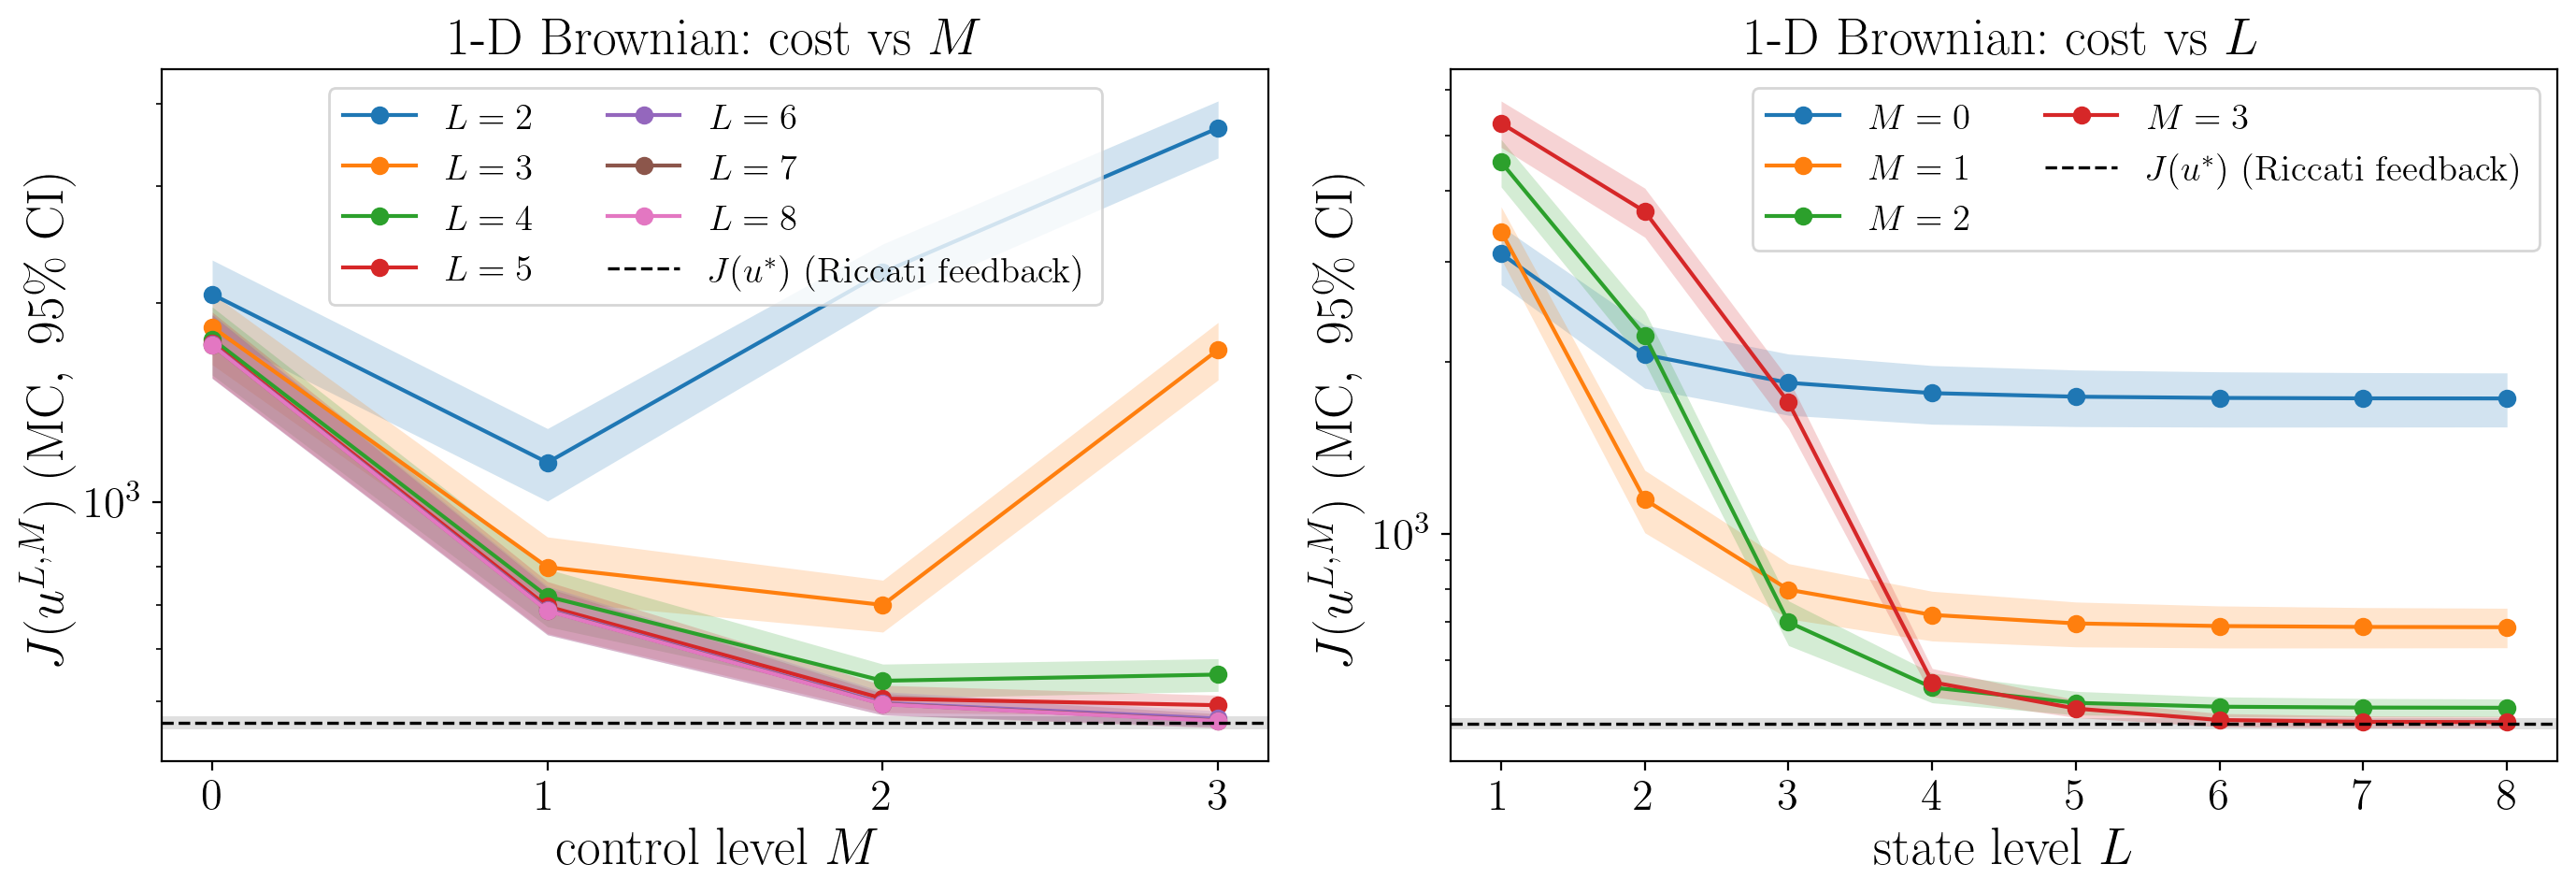

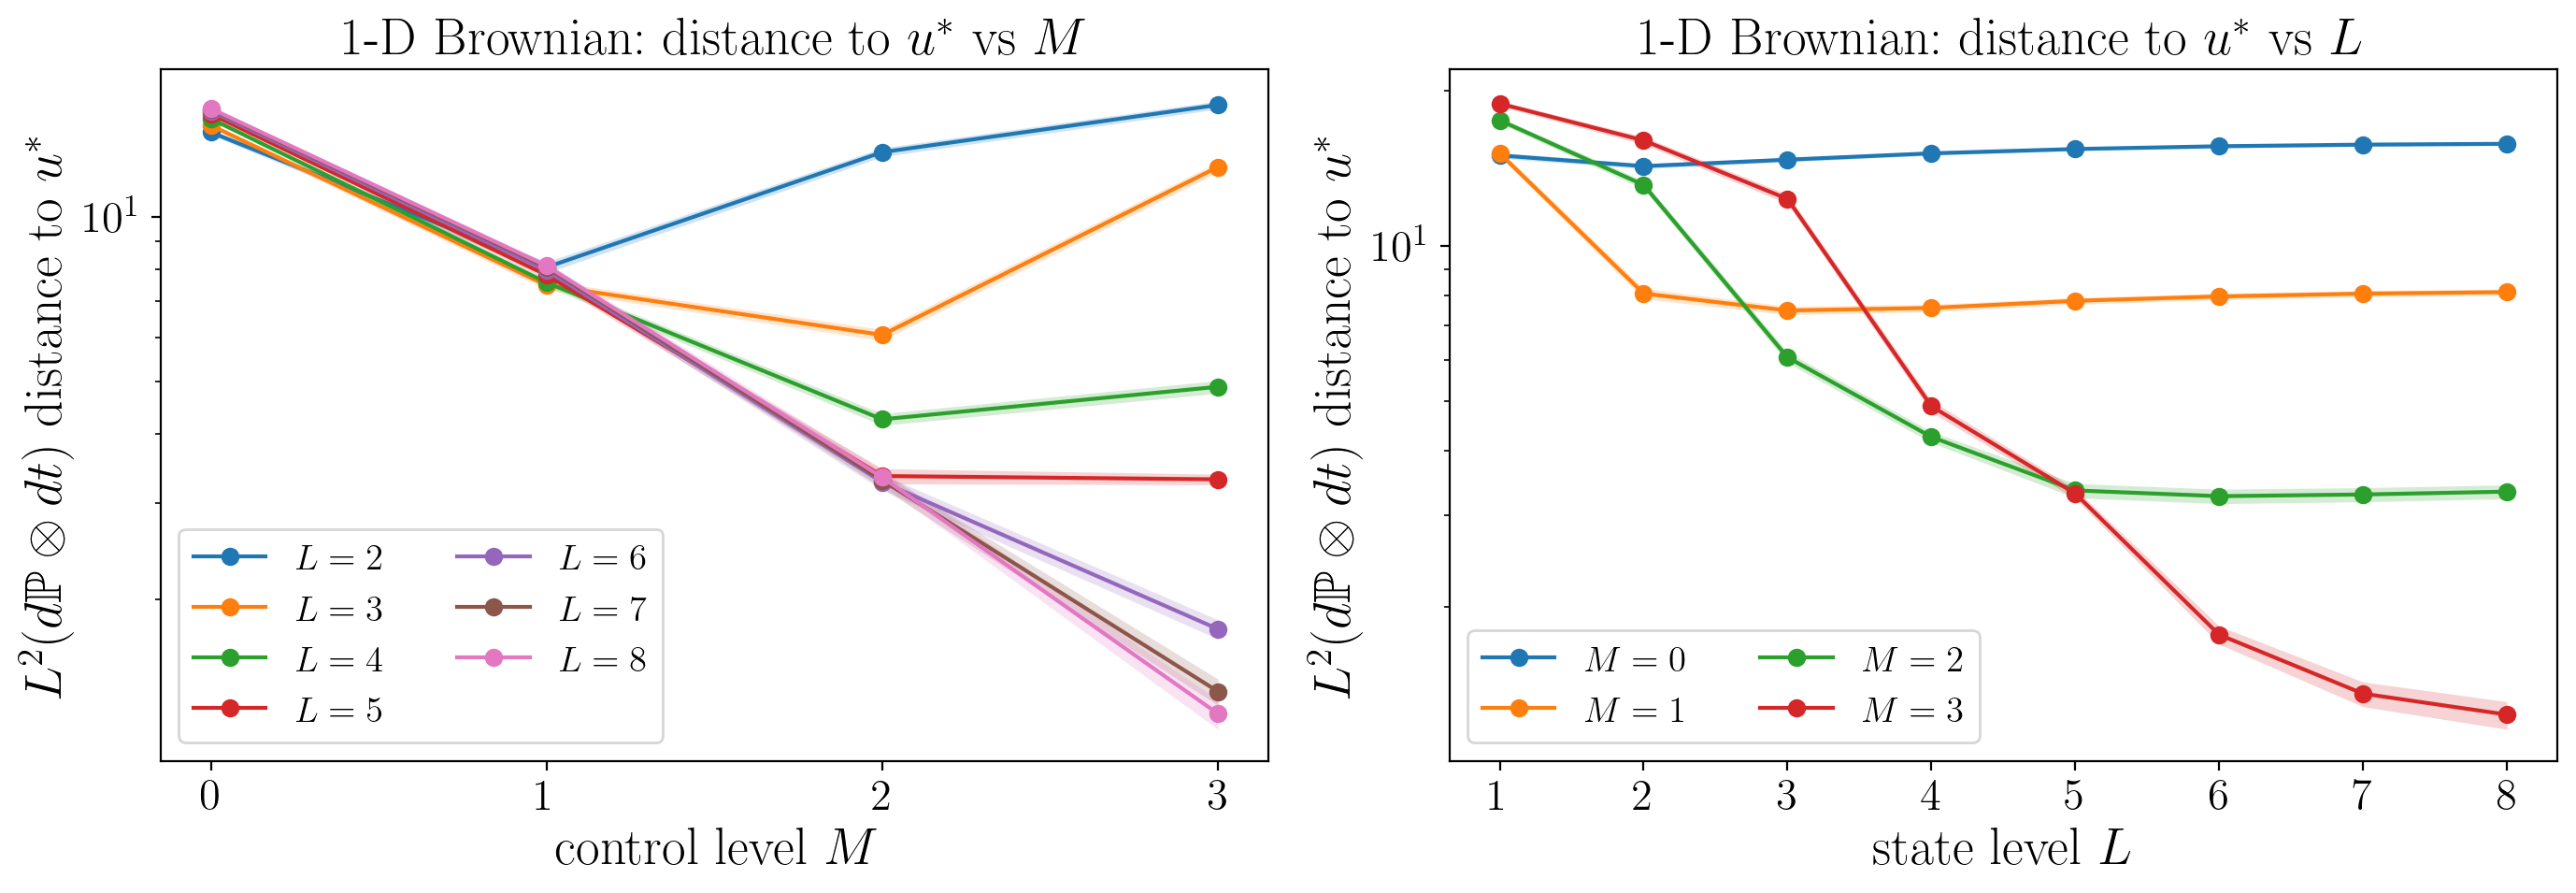

In [14]:
plot_grid(mc1, Ls1, Ms1, c_ref1, r"$J(u^*)\ \mathrm{(Riccati\ feedback)}$", "brownian_1d", r"\mathrm{1\text{-}D\ Brownian}",
          cost_log=True, Ls_vs_M=[L for L in Ls1 if L >= 2])

In [15]:
# Monte Carlo estimate of the optimal feedback's cost, simulated the way a benchmark is simulated in practice
n, steps = 20000, 1000; dt = m1.T / steps
dW = np.random.default_rng(0).normal(scale=np.sqrt(dt), size=(n, steps, m1.D))
ric_grid = riccati_benchmark(m1, n_grid=steps + 1)
fb = lambda i, t, X, sig: -(X @ ric_grid['P'][i].T + ric_grid['r'][i]) @ m1.b1 @ np.linalg.inv(LQModel.poly(m1.B, t)).T
c_opt, _, _ = simulate(m1, dW, dt, fb)
print(f"MC cost of the optimal feedback: {fmt_mc(c_opt, 1)}  [mean ± 95% CI]   (Riccati: {ric1['J']:.2f})")

MC cost of the optimal feedback: 449.5 ± 6.9  [mean ± 95% CI]   (Riccati: 452.30)


### Comparison with the stored result of the repository notebook (reference numbers only)
The repository notebook (`alif-lqproblem-optimising.ipynb`) runs `Optimiser.poly_coef` for $(L,M)=(5,3)$, about 7 hours according to its progress bar, and stores the minimiser `F_flat`.
The fast engine recovers it in a fraction of a second. The remaining differences come from rounding in the repository's finite-difference polarisation.

In [16]:
F_flat_repo = np.array([-38.86268752, 115.80096, -24.25165452, -303.1780068, 17.41773851, 8.83084896, -29.03654183,
                        449.6454885, 13.82861669, 37.37079938, 36.88937532, 38.20537228, 26.21314243, 31.76501943, -5.13906732])
t0 = time.perf_counter(); r53 = solve_signature_lq(m1, 5, 3); t53 = time.perf_counter() - t0
print("θ*(L=5, M=3), fast engine:", r53['theta'])
print(f"max |θ*_fast − F_flat_repo| = {np.abs(r53['theta'] - F_flat_repo).max():.1e}   (fast engine: {t53:.2f}s)")
c53, c53_ref, _ = simulate_many(m1, dW_mc1, dt_mc1, [(F_flat_repo, 3), (r53['theta'], 3)], riccati_feedback(m1, steps_mc1))
print("excess cost over u*  [paired MC on the noise of the table above: mean ± 95% CI]")
print(f"   repo control: {fmt_mc(c53[0] - c53_ref, 3)}\n   θ*_fast:      {fmt_mc(c53[1] - c53_ref, 3)}")

θ*(L=5, M=3), fast engine: [ -38.86269  115.80096  -24.25165 -303.17801   17.41774    8.83085  -29.03654  449.6455    13.82862   37.3708
   36.88938   38.20537   26.21314   31.76502   -5.13907]
max |θ*_fast − F_flat_repo| = 1.1e-05   (fast engine: 0.01s)


excess cost over u*  [paired MC on the noise of the table above: mean ± 95% CI]
   repo control: 29.302 ± 9.141
   θ*_fast:      29.302 ± 9.141


The pattern matches Figure 1 of the paper. For small $L$ the cost first falls and then rises in $M$, because the control is over-fitted against an inaccurate state representation. For fixed $M$ the cost decreases in $L$ to a plateau, and the plateau approaches the optimum as $M$ grows.
The Riccati value here is $J(u^*)\approx 452.30$. The paper quotes $J(u^*)=455$; the Monte Carlo estimate above, with 20,000 paths and 1,000 steps (the paper's set-up), has a half-width of about 7, so 455 is within simulation error of the exact value.

### Sample paths: Brownian 1-D example
All controls below are driven by **the same noise path**. The left panel shows the state and the right panel the control.
The benchmark is drawn in black (and, under fBM, the Markovian Riccati feedback in dashed grey); the signature controls $u^{L,M}$ are in colour.

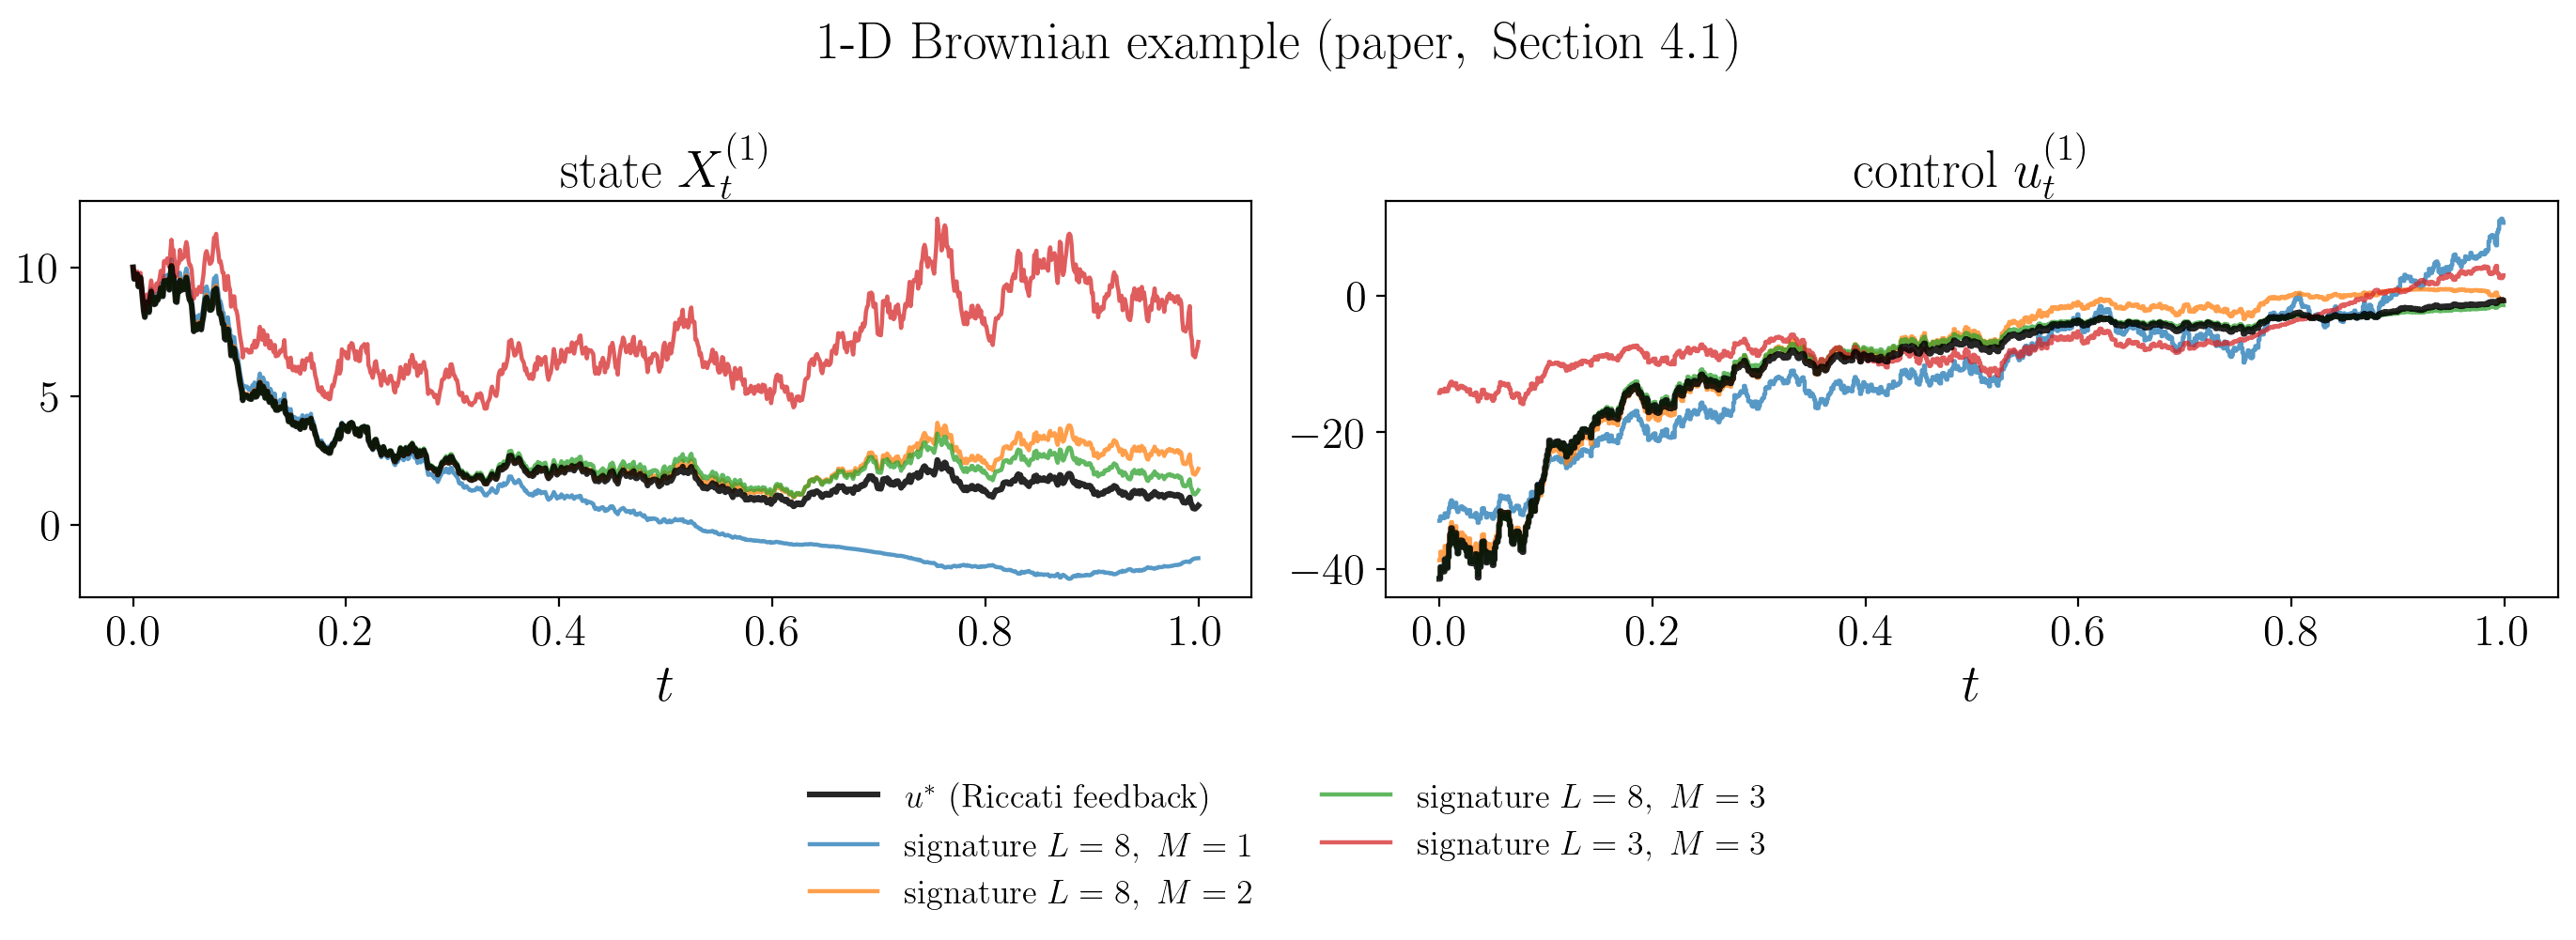

In [17]:
steps_p = 1000; dt_p = m1.T / steps_p
dW_p = np.random.default_rng(41).normal(scale=np.sqrt(dt_p), size=(3, steps_p, m1.D))
F8p = CostFunctionals(m1.D, m1.T, 8, 3, m1.m_max)
ctrls = {r"$u^*\ \mathrm{(Riccati\ feedback)}$": (riccati_feedback(m1, steps_p), 0)}
for (L, M) in [(8, 1), (8, 2), (8, 3), (3, 3)]:
    th = solve_signature_lq(m1, L, M, F=F8p if L == 8 else None)['theta']
    ctrls[rf"$\mathrm{{signature}}\ L={L},\ M={M}$"] = (signature_control(th, m1, M), M)
_ = compare_paths(m1, dW_p, dt_p, ctrls, simulate, title=r"$\mathrm{1\text{-}D\ Brownian\ example\ (paper,\ Section\ 4.1)}$",
                  fname="brownian_1d_sample_paths")
del F8p

## 7. Multi-dimensional example: $N=2$ states, $D=2$ Brownian motions, $K=2$ controls

This uses the model `mm` defined in the checks above, with time-dependent $B(t)=\tfrac12(1+t)I$, cross-coupled drift and noise, and all linear terms on.
The state truncation $L$ runs to 6 (dimension $\dim T^6=1093$ per component) and the control truncation $M$ to 3 ($P=2\times40=80$ parameters).

In [18]:
ricm = riccati_benchmark(mm)
print(f"Riccati optimal cost J(u*) = {ricm['J']:.6f}")
Ls2, Ms2 = [1, 2, 3, 4, 5, 6], [0, 1, 2, 3]
ES2 = expected_signature_bm(mm.D, mm.T, 2 * max(Ls2) + mm.m_max + 1)
trunc2 = np.full((len(Ls2), len(Ms2)), np.nan)
sols2, timing = {}, {}
for i, L in enumerate(Ls2):
    t0 = time.perf_counter(); F = CostFunctionals(mm.D, mm.T, L, max(Ms2), mm.m_max, ES=ES2); tF = time.perf_counter() - t0
    for j, M in enumerate(Ms2):
        t0 = time.perf_counter(); r = solve_signature_lq(mm, L, M, F=F); ts_ = time.perf_counter() - t0
        sols2[(L, M)] = r; timing[(L, M)] = (tF, ts_)
        trunc2[i, j] = r['value']

# Monte Carlo on common noise: every u^{L,M} and the optimal feedback u* (Itô Euler, 10,000 paths, 500 steps)
n_mc2, steps_mc2 = 10000, 500; dt_mc2 = mm.T / steps_mc2
dW_mc2 = np.random.default_rng(1).normal(scale=np.sqrt(dt_mc2), size=(n_mc2, steps_mc2, mm.D))
t0 = time.perf_counter()
cost2, c_ref2, d2_2 = simulate_many(mm, dW_mc2, dt_mc2, [(sols2[k]['theta'], k[1]) for k in sols2],
                                    riccati_feedback(mm, steps_mc2))
mc2 = {k: dict(cost=cost2[c], diff=cost2[c] - c_ref2, d2=d2_2[c]) for c, k in enumerate(sols2)}
print(f"Monte Carlo: {n_mc2} paths, {steps_mc2} steps, {len(mc2) + 1} controls on common noise ({time.perf_counter() - t0:.1f}s)")
print(f"MC cost of u*: {fmt_mc(c_ref2, 5)}   [mean ± 95% CI]")
print()
print_grid(mc2, Ls2, Ms2, 5)
print("\ntruncated objective J^L(θ^{L,M})")
for L, row in zip(Ls2, trunc2): print(f"L={L}: " + "  ".join(f"{v:9.5f}" for v in row))
print("\nrelative excess over u* at L=6:", ["%.2e" % (mc2[(6, M)]['diff'].mean() / c_ref2.mean()) for M in Ms2])
print("time to build cost functionals for L=6: %.2fs; solve for (L,M)=(6,3): %.3fs" % timing[(6, 3)])

Riccati optimal cost J(u*) = 1.347101


Monte Carlo: 10000 paths, 500 steps, 25 controls on common noise (54.2s)
MC cost of u*: 1.36097 ± 0.01013   [mean ± 95% CI]

excess cost J(u^{L,M}) − J(u*)  [paired MC: mean ± 95% CI]     rows: L, cols: M = [0, 1, 2, 3]
L=1:      0.22701 ± 0.00730       0.54085 ± 0.01297       0.76690 ± 0.01594       0.86554 ± 0.01712
L=2:      0.19080 ± 0.00502       0.03939 ± 0.00103       0.39793 ± 0.01008       0.52611 ± 0.01321
L=3:      0.19102 ± 0.00516       0.01292 ± 0.00062       0.05020 ± 0.00082       0.33445 ± 0.00928
L=4:      0.19091 ± 0.00512       0.01261 ± 0.00064       0.00158 ± 0.00013       0.09440 ± 0.00188
L=5:      0.19092 ± 0.00512       0.01260 ± 0.00064       0.00079 ± 0.00010       0.00302 ± 0.00011
L=6:      0.19092 ± 0.00512       0.01260 ± 0.00064       0.00078 ± 0.00010       0.00005 ± 0.00002

L2(dP⊗dt) distance to u*  [± 95% CI]     rows: L, cols: M = [0, 1, 2, 3]
L=1:      0.42108 ± 0.00177       0.54009 ± 0.00297       0.67483 ± 0.00299       0.74011 ± 0.00287
L=2:  

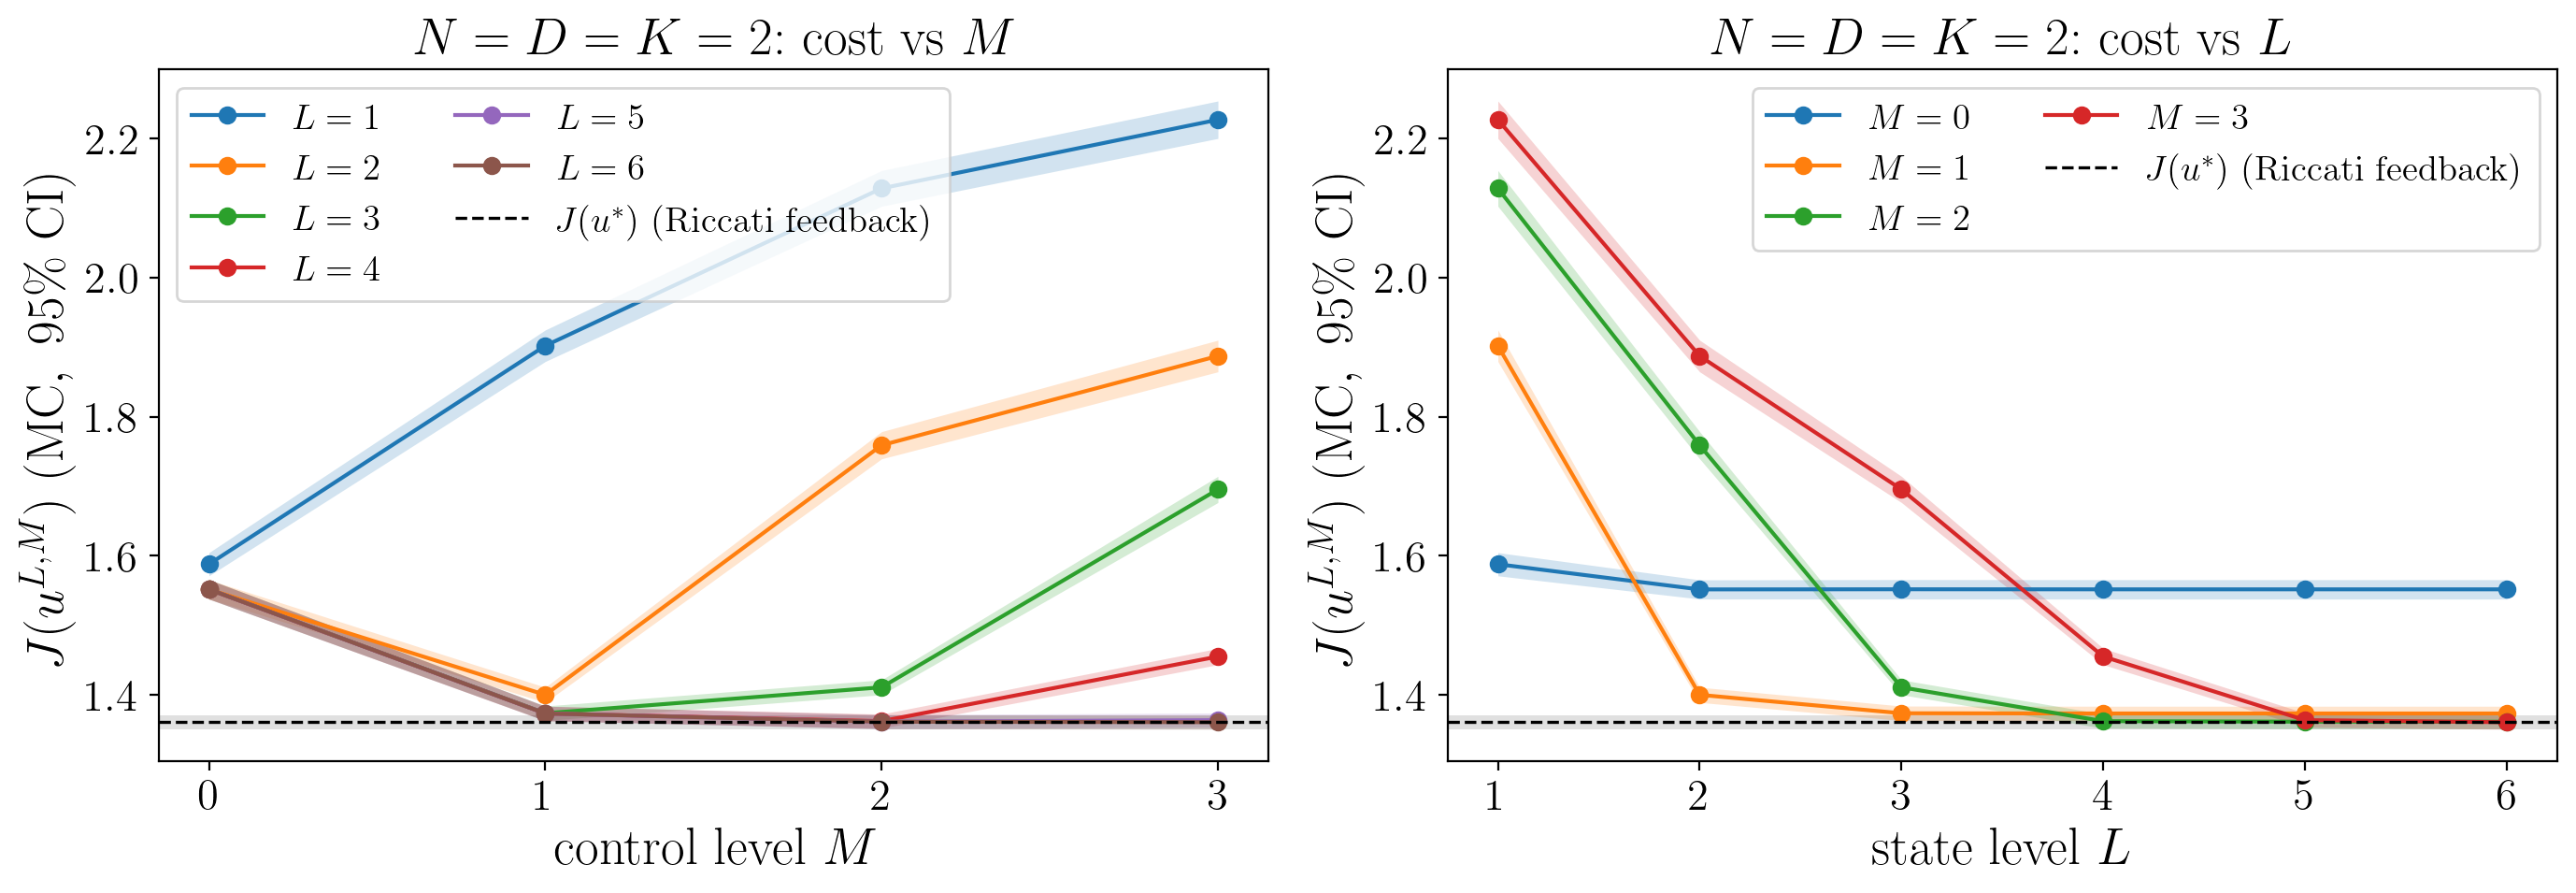

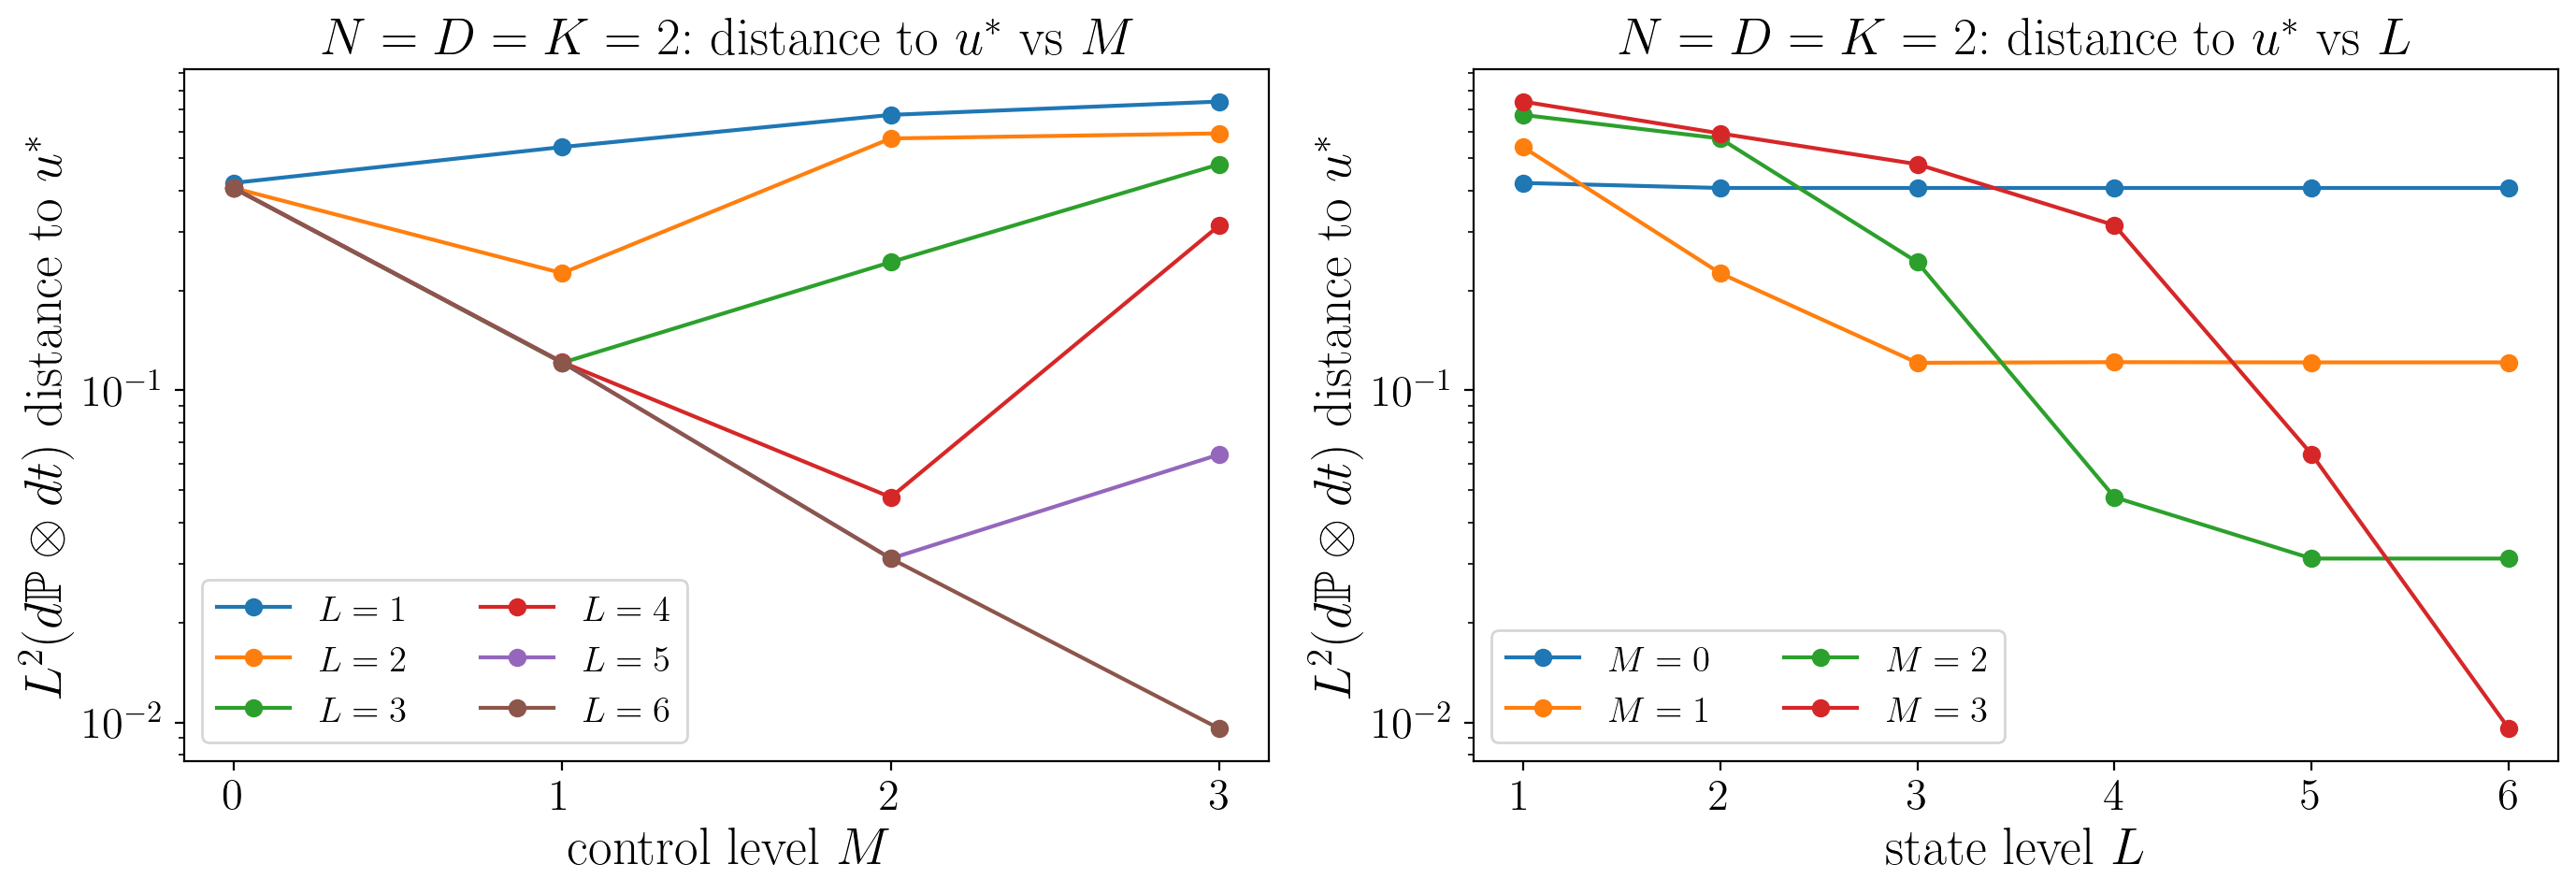

In [19]:
plot_grid(mc2, Ls2, Ms2, c_ref2, r"$J(u^*)\ \mathrm{(Riccati\ feedback)}$", "brownian_2d", r"N=D=K=2")

The same picture appears in the multi-dimensional case: once $L$ is large enough, the excess cost drops by roughly an order of magnitude per control level and the $L^2$ distance to $u^*$ shrinks three- to fourfold. At $(L,M)=(6,3)$ the paired Monte-Carlo excess cost is about $4\times10^{-5}$ of $J(u^*)$. An insufficient state level (e.g. $L=3$, $M=3$) produces an over-fitted control.
The Monte-Carlo cost of $u^*$ sits about 0.014 above the Riccati value. This is the Euler bias at 500 steps; it is common to all controls because they share the same noise, so it cancels in the paired excess costs.
The truncated objective $J^{\rm L}(\theta^{L,M})$ is *not* an upper bound for small $L$, because it can be far below $J(u^*)$. Only the exact or Monte-Carlo cost of the control is a meaningful performance measure.

### Sample paths: Brownian, $N=D=K=2$
All controls below are driven by **the same noise path**. The top row shows the state components and the bottom row the control components.
The benchmark is drawn in black (and, under fBM, the Markovian Riccati feedback in dashed grey); the signature controls $u^{L,M}$ are in colour.

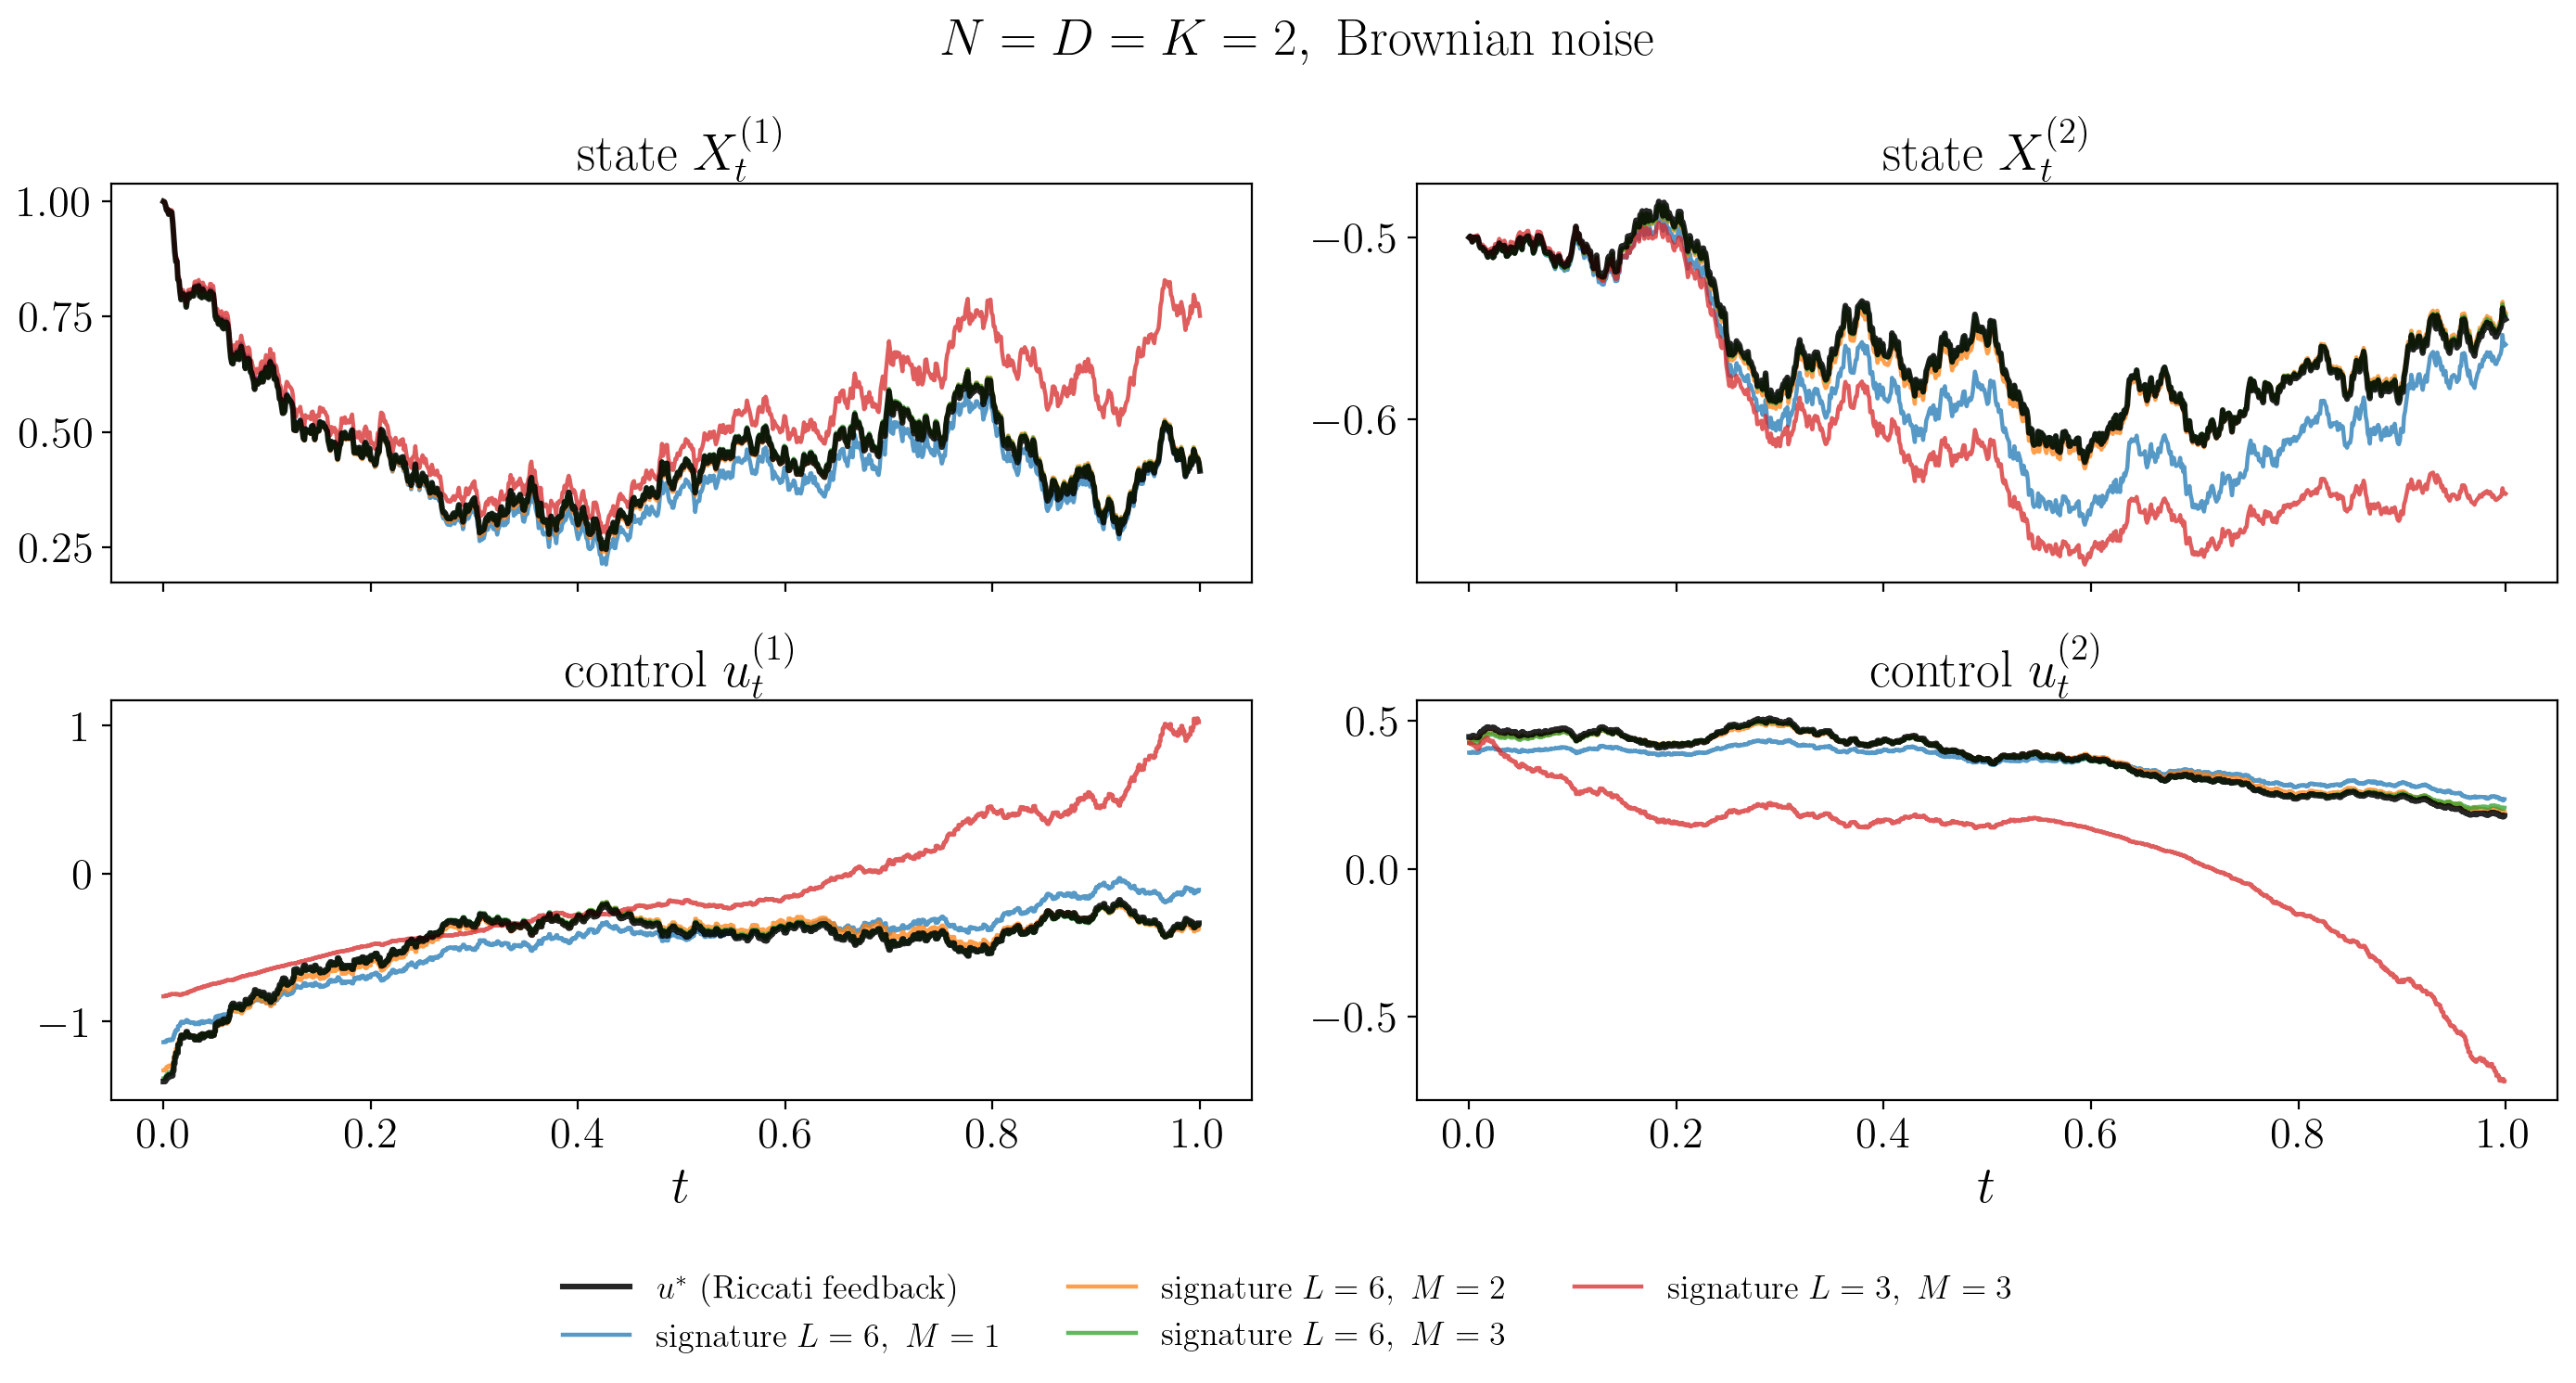

In [20]:
steps_p = 1000; dt_p = mm.T / steps_p
dW_p = np.random.default_rng(7).normal(scale=np.sqrt(dt_p), size=(3, steps_p, mm.D))
ctrls = {r"$u^*\ \mathrm{(Riccati\ feedback)}$": (riccati_feedback(mm, steps_p), 0)}
for (L, M) in [(6, 1), (6, 2), (6, 3), (3, 3)]:
    ctrls[rf"$\mathrm{{signature}}\ L={L},\ M={M}$"] = (signature_control(sols2[(L, M)]['theta'], mm, M), M)
_ = compare_paths(mm, dW_p, dt_p, ctrls, simulate, title=r"$N=D=K=2,\ \mathrm{Brownian\ noise}$",
                  fname="brownian_2d_sample_paths")

## 8. Another shape: $N=3$ states, $D=1$ noise, $K=1$ control, solved with the proposed recursion (A)
A chain $X^{(1)}\to X^{(2)}\to X^{(3)}$ in which only the first component is controlled and the noise is one-dimensional, with multiplicative noise on $X^{(3)}$. This is underactuated, and the noise is lower-dimensional than the state.

In [21]:
m3 = LQModel(T=1.0, X0=[0.5, 1.0, -1.0], b0=[0.0, 0.1, 0.0],
             b1=[[1.0], [0.0], [0.0]],
             b2=[[0.0, 0.0, 0.0], [0.5, -0.2, 0.0], [0.0, 0.5, -0.2]],
             sigma0=[[0.2], [0.1], [0.0]],
             sigma2=np.array([[[0.0, 0.0, 0.0]], [[0.0, 0.0, 0.0]], [[0.0, 0.0, 0.3]]]),
             A=[np.diag([0.2, 0.5, 1.0])], B=[[[0.3]]], C=[[0.0, 0.0, 0.0]], Dlin=[[0.0]],
             E=np.diag([0.0, 0.5, 2.0]), G=[0.0, 0.0, 0.0])
ric3 = riccati_benchmark(m3)
print(f"Riccati J(u*) = {ric3['J']:.6f}")
Ls3, Ms3 = [3, 5, 7, 9], [0, 1, 2, 3]
th3 = {}
for L in Ls3:
    F = CostFunctionals(m3.D, m3.T, L, max(Ms3), m3.m_max)
    for M in Ms3:
        th3[(L, M)] = solve_signature_lq(m3, L, M, solver='picard', F=F)['theta']

# Monte Carlo on common noise (Itô Euler, 10,000 paths, 500 steps), paired with the optimal feedback u*
n_mc3, steps_mc3 = 10000, 500; dt_mc3 = m3.T / steps_mc3
dW_mc3 = np.random.default_rng(3).normal(scale=np.sqrt(dt_mc3), size=(n_mc3, steps_mc3, m3.D))
cost3, c_ref3, d2_3 = simulate_many(m3, dW_mc3, dt_mc3, [(th3[k], k[1]) for k in th3], riccati_feedback(m3, steps_mc3))
mc3 = {k: dict(cost=cost3[c], diff=cost3[c] - c_ref3, d2=d2_3[c]) for c, k in enumerate(th3)}
print(f"MC cost of u*: {fmt_mc(c_ref3, 5)}   [mean ± 95% CI]\n")
print_grid(mc3, Ls3, Ms3, 5)

Riccati J(u*) = 1.997198


MC cost of u*: 1.99454 ± 0.01382   [mean ± 95% CI]

excess cost J(u^{L,M}) − J(u*)  [paired MC: mean ± 95% CI]     rows: L, cols: M = [0, 1, 2, 3]
L=3:      0.02365 ± 0.00007       0.00583 ± 0.00006       0.25277 ± 0.00046       0.17222 ± 0.00055
L=5:      0.02364 ± 0.00007       0.00018 ± 0.00001       0.00006 ± 0.00000       0.04886 ± 0.00030
L=7:      0.02364 ± 0.00007       0.00018 ± 0.00001       0.00002 ± 0.00000       0.00000 ± 0.00000
L=9:      0.02364 ± 0.00007       0.00018 ± 0.00001       0.00002 ± 0.00000       0.00000 ± 0.00000

L2(dP⊗dt) distance to u*  [± 95% CI]     rows: L, cols: M = [0, 1, 2, 3]
L=3:      0.26962 ± 0.00024       0.13397 ± 0.00043       0.90147 ± 0.00086       0.74574 ± 0.00118
L=5:      0.27030 ± 0.00025       0.02355 ± 0.00026       0.01437 ± 0.00008       0.40065 ± 0.00126
L=7:      0.27031 ± 0.00025       0.02351 ± 0.00026       0.00677 ± 0.00008       0.00317 ± 0.00003
L=9:      0.27031 ± 0.00025       0.02351 ± 0.00026       0.00677 ± 0.00008    

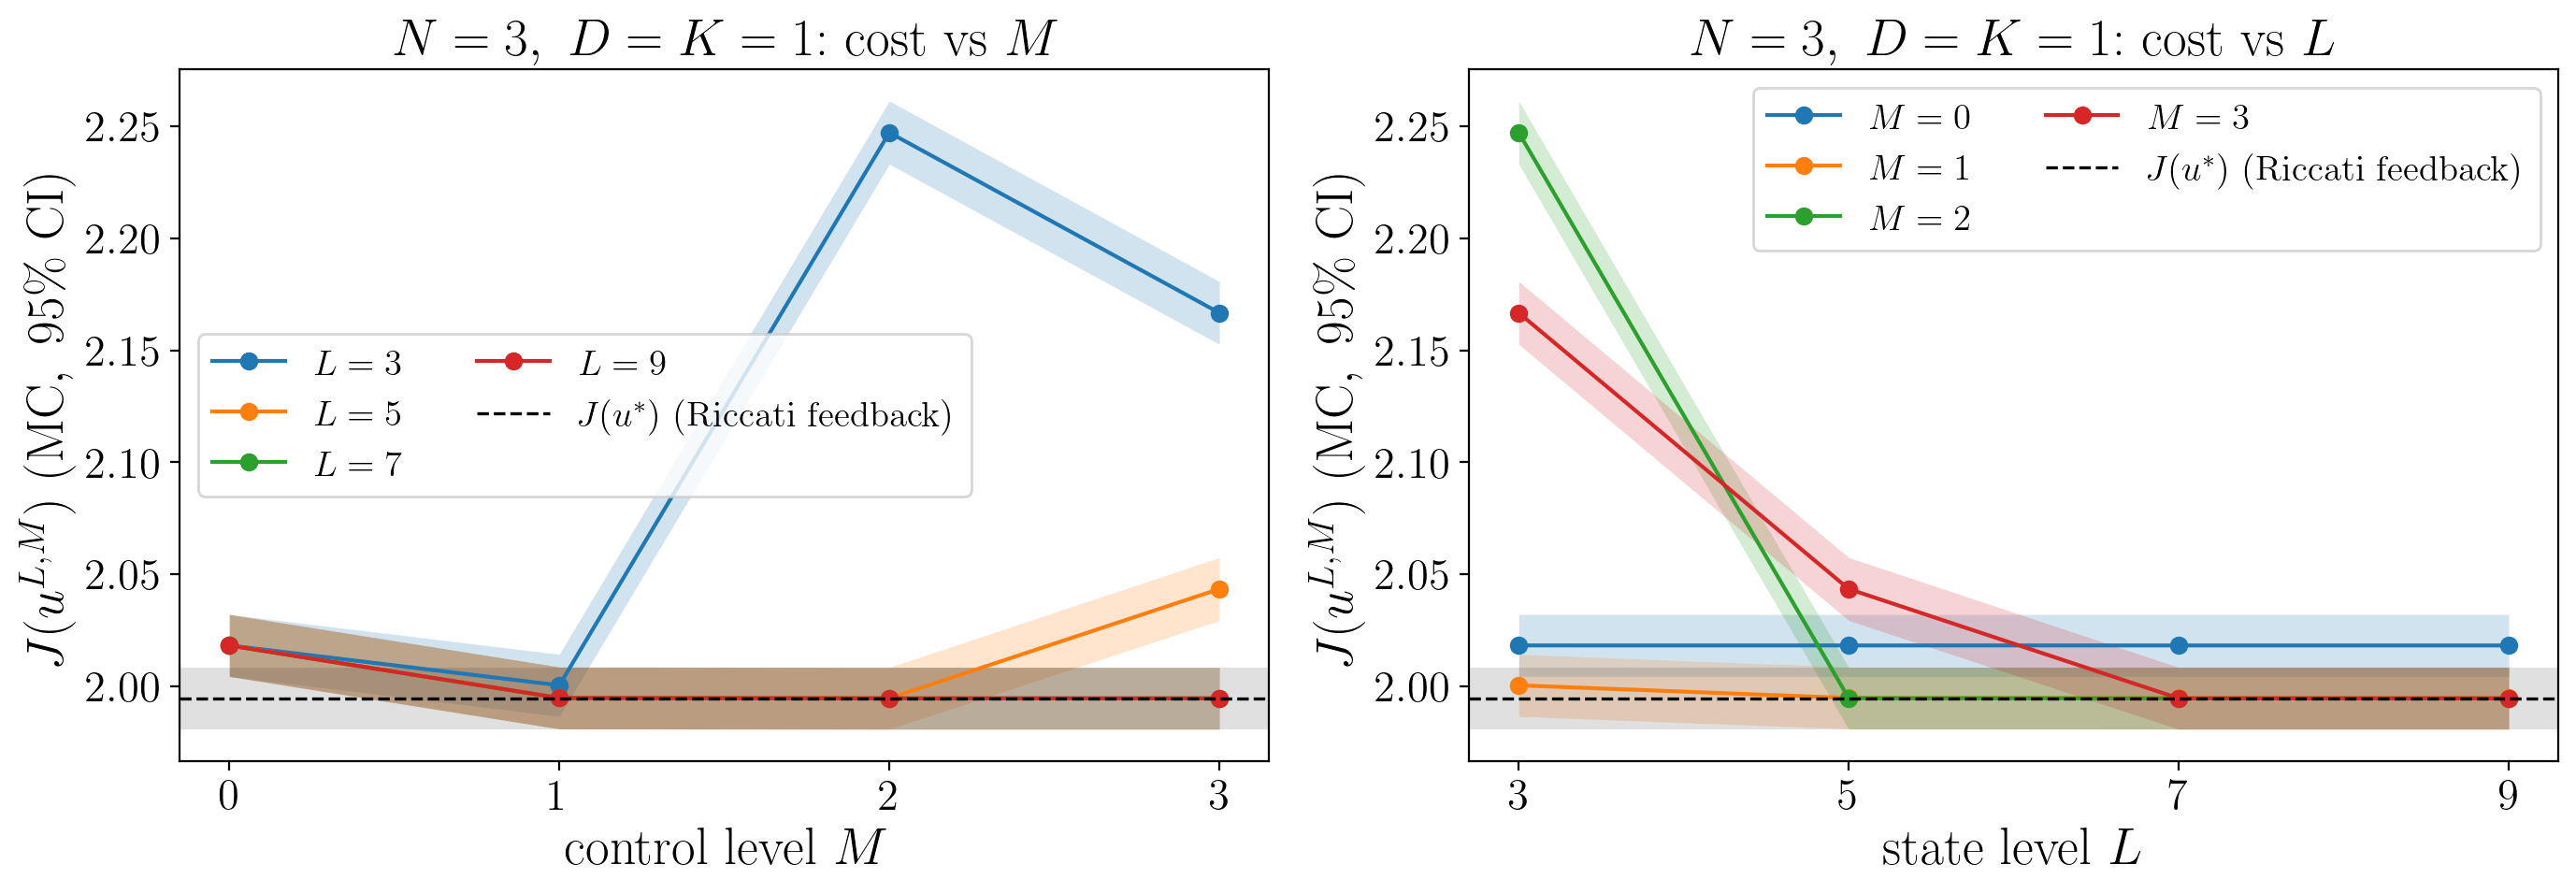

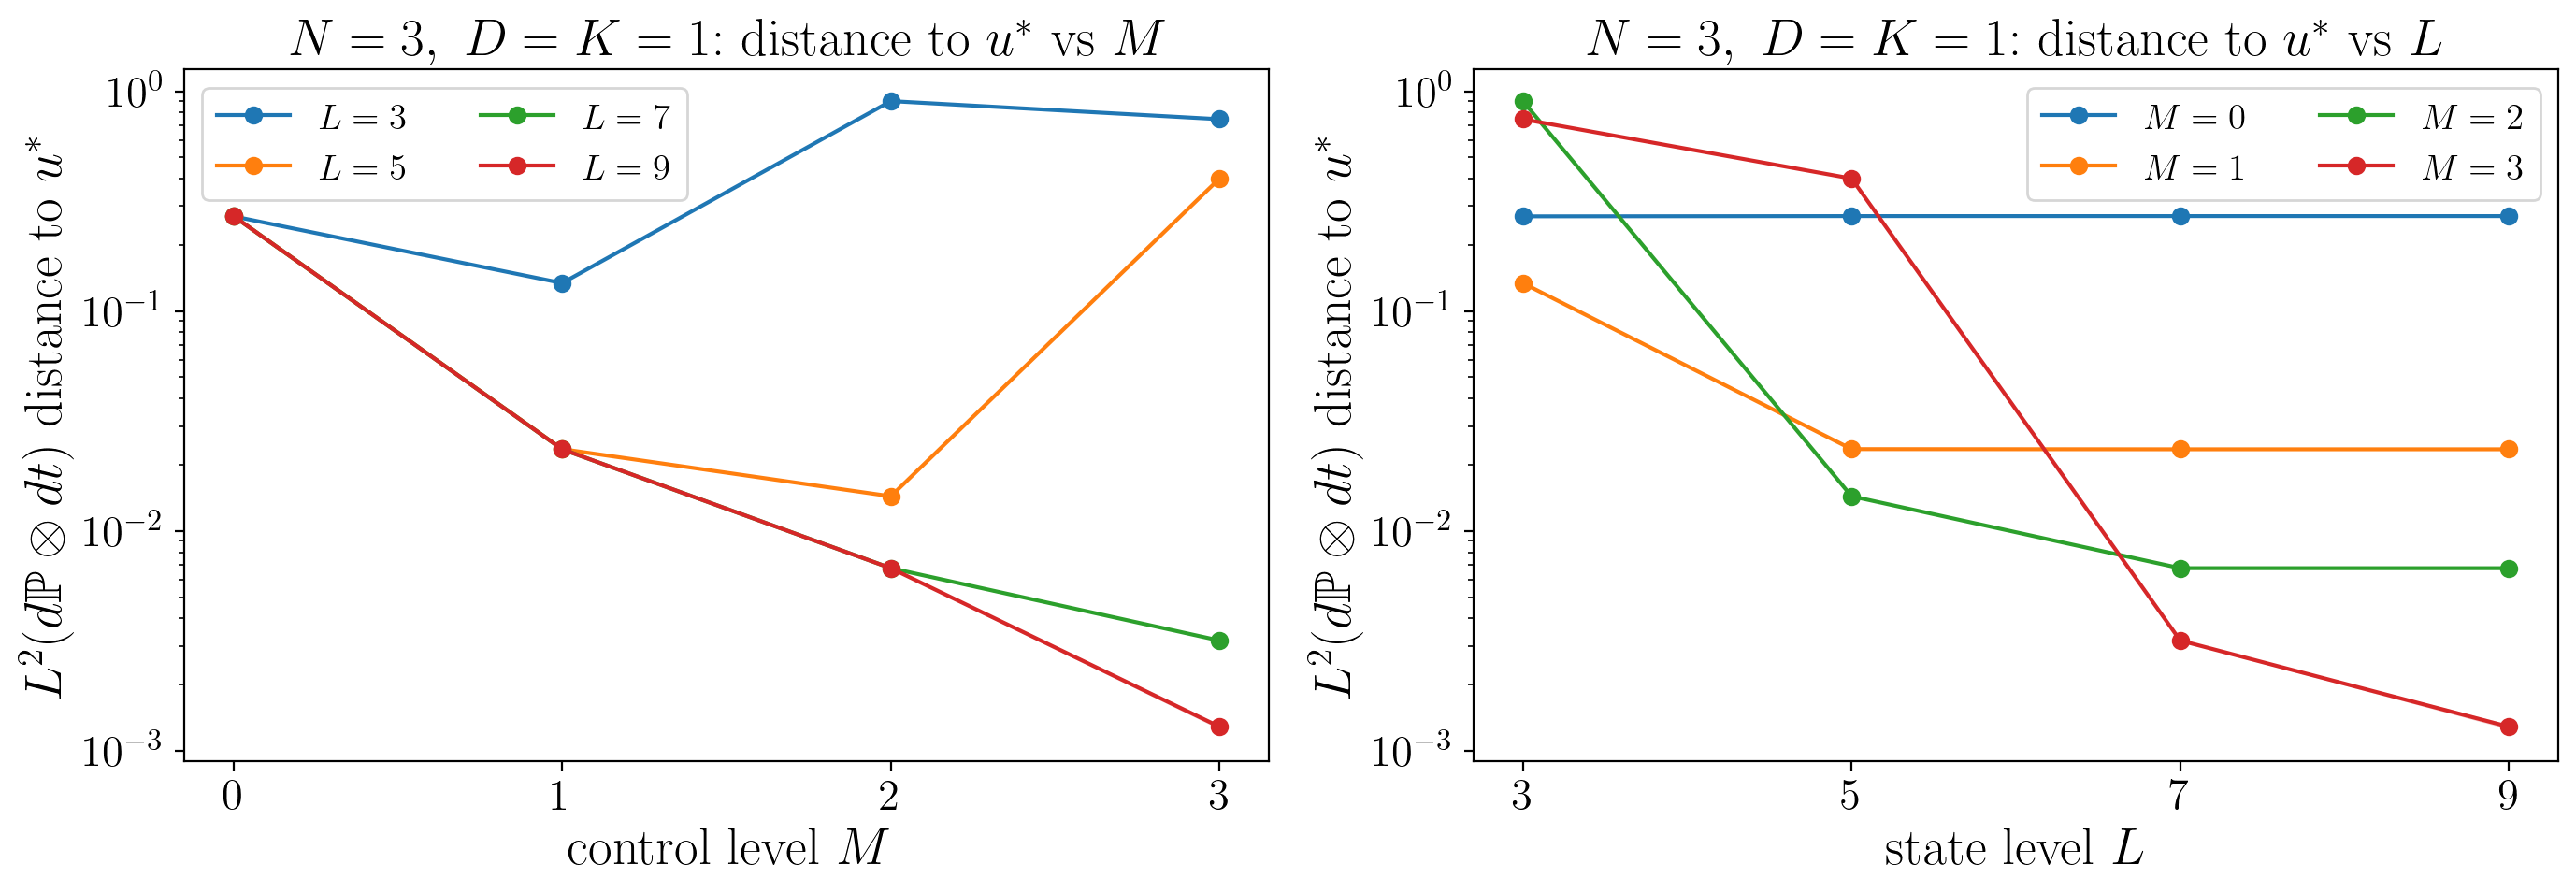

In [22]:
plot_grid(mc3, Ls3, Ms3, c_ref3, r"$J(u^*)\ \mathrm{(Riccati\ feedback)}$", "brownian_N3", r"N=3,\ D=K=1")

### Sample paths: Brownian, $N=3$, $D=K=1$
All controls below are driven by **the same noise path**. The top row shows the state components and the bottom row the control components.
The benchmark is drawn in black (and, under fBM, the Markovian Riccati feedback in dashed grey); the signature controls $u^{L,M}$ are in colour.

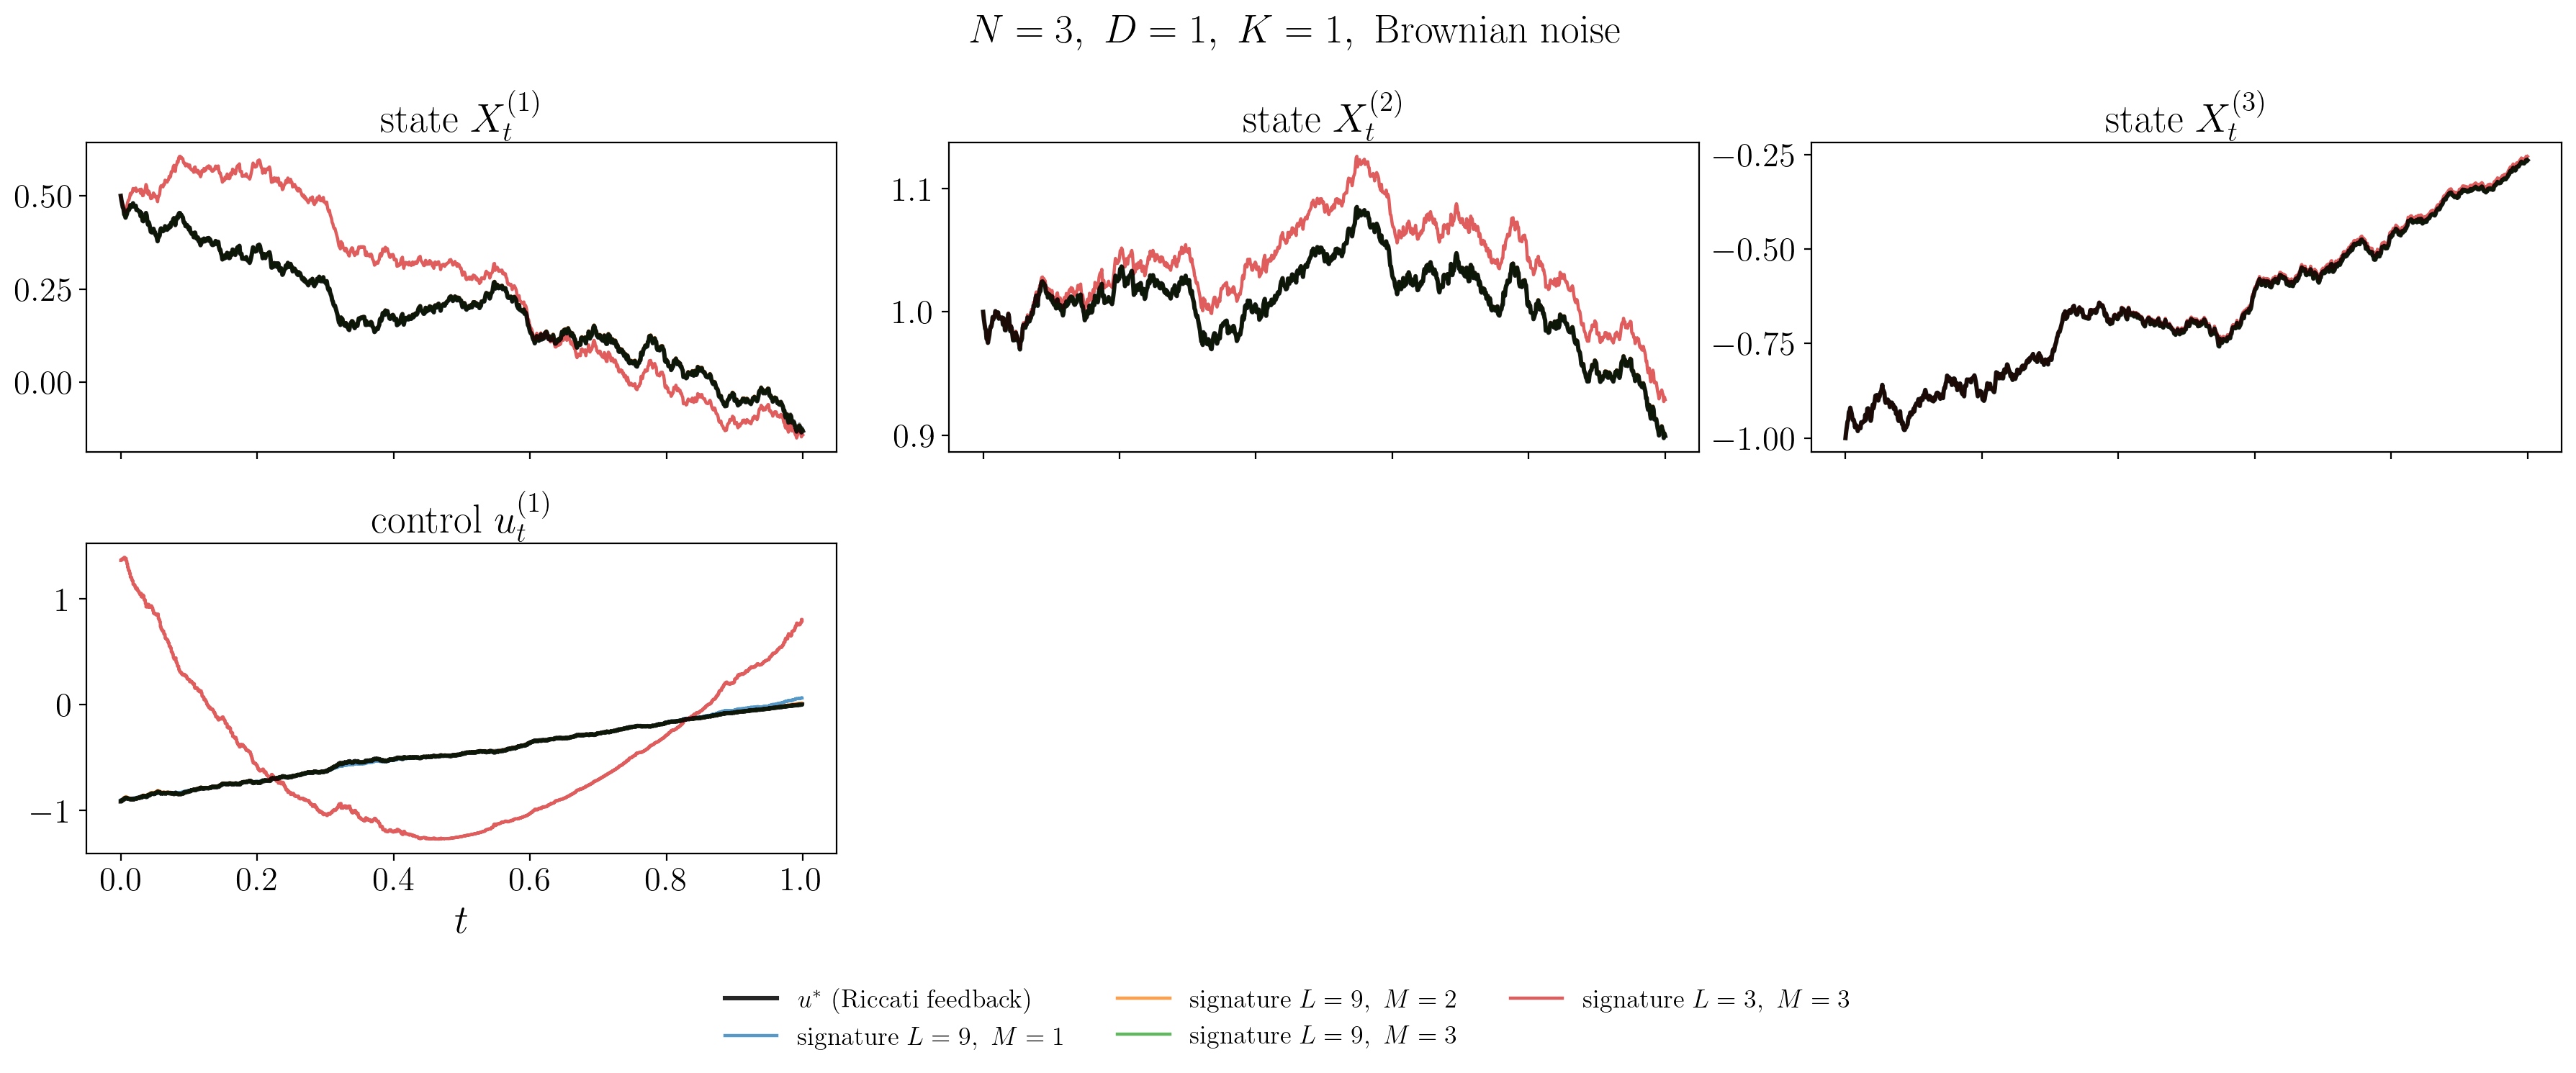

In [23]:
steps_p = 1000; dt_p = m3.T / steps_p
dW_p = np.random.default_rng(8).normal(scale=np.sqrt(dt_p), size=(3, steps_p, m3.D))
F9p = CostFunctionals(m3.D, m3.T, 9, 3, m3.m_max)
ctrls = {r"$u^*\ \mathrm{(Riccati\ feedback)}$": (riccati_feedback(m3, steps_p), 0)}
for (L, M) in [(9, 1), (9, 2), (9, 3), (3, 3)]:
    th = solve_signature_lq(m3, L, M, solver='picard', F=F9p if L == 9 else None)['theta']
    ctrls[rf"$\mathrm{{signature}}\ L={L},\ M={M}$"] = (signature_control(th, m3, M), M)
_ = compare_paths(m3, dW_p, dt_p, ctrls, simulate, title=r"$N=3,\ D=1,\ K=1,\ \mathrm{Brownian\ noise}$",
                  fname="brownian_N3_sample_paths")
del F9p

## 9. Numerical optimisation of $\theta$: SGD and Adam (optional)

So far $\theta^{L,M}$ was obtained in closed form from $H\theta=-h$. The same minimiser can be found with first-order methods, selected through
`fit_signature_control(model, L, M, method='adam' | 'sgd', mode=...)`. `method='closed_form'` remains the default. Three gradient sources are available:

| `mode` | objective | gradient | needs $\mathbb E[\widehat{\mathbb W}_T]$? |
|---|---|---|---|
| `'exact'` | $J^{\rm L}(\theta)$ | deterministic, $\nabla J^{\rm L}=2(H\theta+h)$ | yes |
| `'mc_tensor'` | $J^{\rm L}(\theta)$ (unbiased up to the time grid) | minibatch, with $X^{L}_t=\langle\mathtt X^{L}(\theta),\widehat{\mathbb W}_t\rangle$ on simulated signatures | **no** |
| `'mc_sde'` | $J(\theta)$ itself (no state truncation) | minibatch, with $X_t$ from Euler–Maruyama of the true SDE | no |

**Why the gradients are exact.** In both Monte-Carlo modes the simulated state is affine in $\theta$, path by path. In `mc_tensor` this follows from the affine lift $\mathtt X(\theta)=\mathtt X_0+\sum_i\theta_i\mathtt X_i$. In `mc_sde` it holds because $X(\theta)=Z_0+Z\theta$, where the sensitivities $Z_i=\partial X/\partial\theta_i$ solve the same linear SDE driven by $b_1^{(\cdot,k)}\widehat{\mathbb W}^{\mathbf v}_t$.
`mc_feature_pool` therefore stores the "features" $(F_t,S_t)$ once, and the pathwise cost of each minibatch is an explicit quadratic in $\theta$. Its gradient (`mc_loss_grad`) is exact, with no automatic differentiation or finite differences.

**Options.**
* `lr`, `lr_decay` (a function $k\mapsto$ multiplier).
* `momentum` for SGD; `betas` for Adam.
* `batch_size`, `n_pool`, and `refresh_every` (redraw the path pool), plus the time grid `n_steps` / `record_every`.
* `average_tail` (Polyak–Ruppert averaging of the last iterates, which is useful with stochastic gradients).
* `grad_clip`.
* `precondition='diag'`: rescale each coordinate to unit curvature, using exact or pool-estimated $\operatorname{diag}H$.
* `increments`: supply driver increments (e.g. fBM) in `mc_tensor` mode.

**Conditioning.** Signature coordinates are strongly correlated (for example $t$, $t^2/2$ and $\int W\,dt$), so $H$ is badly conditioned; in the $N=D=K=2$, $L=6$, $M=3$ case, $\operatorname{cond}(H)\approx6\times10^5$.
First-order methods therefore reach near-optimal **cost** quickly but converge slowly in the **coefficients**. Many coefficient vectors generate almost the same control. The cost (estimated by Monte Carlo, or $J^{\rm L}$) is the meaningful convergence measure here. Below, every 100th iterate is evaluated by Monte Carlo on common noise (5,000 paths, 250 Itô Euler steps), paired with the optimal feedback $u^*$.

In [24]:
def _time_weights(n_rec, dt_rec):
    w = np.full(n_rec, dt_rec); w[0] *= 0.5; w[-1] *= 0.5          # trapezoid on the recorded grid
    return w

def mc_feature_pool(model, L, M, n_paths, n_steps=100, record_every=2, mode='tensor', rng=None,
                    increments=None, Xall=None, driver='bm'):
    """Monte-Carlo 'features' that make the pathwise cost an explicit quadratic in θ:
         X_t(θ) = F_t[..., 0] + F_t[..., 1:] @ θ ,   u^(k)_t(θ) = <θ_k, Ŵ_t^{≤M}> = θ_k · S_t .
    mode='tensor': X_t = <𝚇^L(θ), Ŵ_t>  (truncated state tensor paired with the path signature);
                   the sample mean of the pathwise cost is an unbiased estimate of J^L(θ) (up to the time grid).
                   Works for any driver: pass `increments` (n_paths, n_steps, D) of e.g. fBM instead of BM.
    mode='sde':    X_t from a time-stepping of the true dynamics (no L truncation): targets J(θ) itself.
                   X(θ) = Z0 + Z θ exactly, where the sensitivities Z solve the same linear SDE.
                   driver='bm': Itô Euler–Maruyama (Brownian increments).  driver='general' (any increments, e.g. fBM;
                   Stratonovich / Wong–Zakai sense): Euler if sigma2 = 0, else the exact piecewise-linear step."""
    rng = np.random.default_rng() if rng is None else rng
    N, K, D, d = model.N, model.K, model.D, model.d
    dt = model.T / n_steps; tM = TensorSpace(d, M); dimM = tM.dim; P = K * dimM
    dW = rng.normal(scale=np.sqrt(dt), size=(n_paths, n_steps, D)) if increments is None else increments
    rec = list(range(0, n_steps + 1, record_every))
    if rec[-1] != n_steps: rec.append(n_steps)
    F, S = [], []
    if mode == 'tensor':
        ts = TensorSpace(d, L)
        Xall = state_affine(model, L, M) if Xall is None else Xall                   # (1+P, N, dim_L)
        Xmat = Xall.reshape(-1, ts.dim).T                                            # (dim_L, (1+P) N)
        for i, sig in enumerate(signature_stream(dW, dt, max(L, M))):
            if i in rec:
                F.append((sig[:, :ts.dim] @ Xmat).reshape(n_paths, 1 + P, N).transpose(0, 2, 1))
                S.append(sig[:, :dimM].copy())
    elif mode == 'sde' and driver == 'general' and np.any(model.sigma2):
        Z = np.zeros((n_paths, N, 1 + P)); Z[:, :, 0] = model.X0
        stream = signature_stream(dW, dt, M)
        for i in range(n_steps + 1):
            sig = next(stream)
            if i in rec: F.append(Z.copy()); S.append(sig[:, :dimM].copy())
            if i == n_steps: break
            beta = dW[:, i] / dt
            Em, Ph = _wz_step_matrices(model, beta, dt)
            force = np.zeros((n_paths, N, 1 + P)); force[:, :, 0] = model.b0 + beta @ model.sigma0.T
            force[:, :, 1:] = np.einsum('nk,bv->bnkv', model.b1, sig[:, :dimM]).reshape(n_paths, N, P)
            Z = np.einsum('pnm,pmq->pnq', Em, Z) + np.einsum('pnm,pmq->pnq', Ph, force)
    elif mode == 'sde':
        if driver == 'general': assert not np.any(model.sigma2)
        a, Ab, c, Cm = ito_coefficients(model)     # = (b0, b2, σ0, 0) when sigma2 = 0: Euler valid for any driver
        Z = np.zeros((n_paths, N, 1 + P)); Z[:, :, 0] = model.X0
        stream = signature_stream(dW, dt, M)
        for i in range(n_steps + 1):
            sig = next(stream)
            if i in rec: F.append(Z.copy()); S.append(sig[:, :dimM].copy())
            if i == n_steps: break
            drift = np.einsum('nm,bmp->bnp', Ab, Z); drift[:, :, 0] += a
            drift[:, :, 1:] += np.einsum('nk,bv->bnkv', model.b1, sig[:, :dimM]).reshape(n_paths, N, P)
            dZ = drift * dt
            for dd in range(D):
                vol = np.einsum('nm,bmp->bnp', Cm[dd], Z); vol[:, :, 0] += c[dd]
                dZ += vol * dW[:, i, dd][:, None, None]
            Z = Z + dZ
    else:
        raise ValueError(mode)
    tg = np.array(rec) * dt
    return dict(F=np.stack(F, 1), S=np.stack(S, 1), t=tg, w=_time_weights(len(tg), dt * record_every)
                if len(set(np.diff(rec))) == 1 else np.gradient(tg), mode=mode)

def _cost_weights(model, t):
    return dict(At=np.stack([LQModel.poly(model.A, s) for s in t]), Bt=np.stack([LQModel.poly(model.B, s) for s in t]),
                Ct=np.stack([LQModel.poly(model.C, s) for s in t]), Dt=np.stack([LQModel.poly(model.Dlin, s) for s in t]))

def mc_loss_grad(model, theta, F, S, t, w, cw=None):
    """Sample-mean pathwise cost and its exact θ-gradient for a minibatch (F: (b,R,N,1+P), S: (b,R,dim_M)).
    Pathwise cost  Σ_r w_r [X'AX + u'Bu + 2C'X + 2D'u](t_r) + X_T'E X_T + 2G'X_T  with
    X_t = F_t[...,0] + F_t[...,1:] θ  and  u_t = Θ S_t."""
    cw = _cost_weights(model, t) if cw is None else cw
    b, R, N, P1 = F.shape; K = model.K; dimM = S.shape[-1]; Th = theta.reshape(K, dimM)
    F1 = F[..., 1:]
    X = F[..., 0] + F1 @ theta                                           # (b, R, N)
    u = S @ Th.T                                                         # (b, R, K)
    AX = np.einsum('rnm,brm->brn', cw['At'], X) + cw['Ct']               # A X + C
    BU = np.einsum('rkj,brj->brk', cw['Bt'], u) + cw['Dt']               # B u + D
    run = np.einsum('brn,brn->br', X, AX + cw['Ct']) + np.einsum('brk,brk->br', u, BU + cw['Dt'])
    XT = X[:, -1]; EX = XT @ model.E.T + model.G
    loss = (run @ w + np.einsum('bn,bn->b', XT, EX + model.G)).mean()
    wAX = AX * w[None, :, None]; wAX[:, -1] += EX                       # terminal term folded into last time point
    gX = 2 * (wAX.reshape(1, -1) @ F1.reshape(-1, P1 - 1))[0]
    gU = 2 * ((BU * w[None, :, None]).reshape(-1, K).T @ S.reshape(-1, dimM)).ravel()
    return loss, (gX + gU) / b

def mc_diag_curvature(model, pool):
    """Pool estimate of diag H, the curvature of the sample cost in each θ-coordinate."""
    F, S, t, w = pool['F'][..., 1:], pool['S'], pool['t'], pool['w']
    K, dimM = model.K, S.shape[-1]
    At = np.stack([LQModel.poly(model.A, s) for s in t]); Bt = np.stack([LQModel.poly(model.B, s) for s in t])
    dX = np.einsum('r,brnp,rnm,brmp->p', w, F, At, F) + np.einsum('bnp,nm,bmp->p', F[:, -1], model.E, F[:, -1])
    dU = np.einsum('r,rkk,brv->kv', w, Bt, S ** 2).ravel()
    return (dX + dU) / F.shape[0]

def optimise_theta(model, L, M, method='adam', mode='mc_tensor', n_iter=2000, lr=0.05, batch_size=256,
                   n_pool=2048, refresh_every=None, n_steps=100, record_every=2, momentum=0.9,
                   betas=(0.9, 0.999), eps=1e-8, lr_decay=None, average_tail=0.25, grad_clip=None,
                   precondition=None, theta0=None, seed=0, eval_every=100, F=None, increments=None,
                   increments_fn=None, verbose=False):
    """First-order minimisation of the signature-control objective.
    method: 'sgd' (with momentum; Nesterov-free heavy ball) or 'adam'.
    mode:   'exact'     – deterministic full gradient 2(Hθ+h) of J^L (needs the cost functionals),
            'mc_tensor' – minibatch gradients of the pathwise cost with X^L_t = <𝚇^L(θ), Ŵ_t>  (unbiased for J^L),
            'mc_sde'    – minibatch gradients with the Euler-simulated state (targets J itself, no L).
    lr_decay: None or a function k -> multiplier (e.g. lambda k: 1/(1+k/500)).
    average_tail: Polyak–Ruppert averaging over the last fraction of iterations (0 = off).
    refresh_every: regenerate the path pool every this many iterations (None = fixed pool).
    increments_fn: rng -> driver increments (n_pool, n_steps, D), e.g. fBM; used for every (re)generated pool.
                   With a non-Brownian driver, pass F (e.g. EmpiricalCostFunctionals) for mode 'exact' / monitoring.
    precondition: None or 'diag' – optimise φ with θ = φ / sqrt(diag H), where diag H is the exact
                  (mode 'exact') or pool-estimated (MC modes) curvature of each coordinate.  This rescales
                  signature coordinates of different levels to unit curvature (helps plain SGD the most)."""
    rng = np.random.default_rng(seed); P = model.K * TensorSpace(model.d, M).dim
    theta = np.zeros(P) if theta0 is None else np.array(theta0, float)
    quad = None
    if mode == 'exact' or eval_every:
        Fc = CostFunctionals(model.D, model.T, L, M, model.m_max) if F is None else F
        quad = solve_signature_lq(model, L, M, F=Fc)
    if mode == 'exact':
        c0, h, H = quad['c0'], quad['h'], quad['H']
        loss_grad = lambda th: (c0 + 2 * h @ th + th @ H @ th, 2 * (H @ th + h))
    else:
        kind = {'mc_tensor': 'tensor', 'mc_sde': 'sde'}[mode]
        Xall = state_affine(model, L, M) if kind == 'tensor' else None
        drv = 'general' if (increments_fn is not None or increments is not None) else 'bm'
        make_pool = lambda: mc_feature_pool(model, L, M, n_pool, n_steps, record_every, kind, rng,
                                            increments=increments_fn(rng) if increments_fn else increments,
                                            Xall=Xall, driver=drv)
        pool = make_pool(); cw = _cost_weights(model, pool['t']); bs = min(batch_size, n_pool)
        def loss_grad(th):
            s0 = rng.integers(0, n_pool - bs + 1)       # paths are i.i.d., so a random contiguous block is a
            sl = slice(s0, s0 + bs)                     # valid minibatch and avoids copying the pool
            return mc_loss_grad(model, th, pool['F'][sl], pool['S'][sl], pool['t'], pool['w'], cw)
    if precondition == 'diag':
        diagH = np.diag(quad['H']).copy() if mode == 'exact' else mc_diag_curvature(model, pool)
        scale = 1.0 / np.sqrt(np.maximum(diagH, 1e-12 * diagH.max()))
    elif precondition is None:
        scale = np.ones(P)
    else:
        raise ValueError(precondition)
    theta = theta / scale                                                # optimise φ = θ / scale
    _lg = loss_grad
    loss_grad = lambda phi: (lambda lg: (lg[0], lg[1] * scale))(_lg(phi * scale))
    m1, m2, vel = np.zeros(P), np.zeros(P), np.zeros(P)
    avg, n_avg, start_avg = np.zeros(P), 0, int((1 - average_tail) * n_iter)
    hist = dict(it=[], loss=[], JL=[], dist=[], theta=[])
    t0 = time.perf_counter()
    for k in range(1, n_iter + 1):
        if mode != 'exact' and refresh_every and k % refresh_every == 0: pool = make_pool()
        loss, g = loss_grad(theta)
        if grad_clip is not None:
            gn = np.linalg.norm(g); g = g * min(1.0, grad_clip / (gn + 1e-300))
        step = lr * (lr_decay(k) if lr_decay else 1.0)
        if method == 'adam':
            m1 = betas[0] * m1 + (1 - betas[0]) * g; m2 = betas[1] * m2 + (1 - betas[1]) * g * g
            mh, vh = m1 / (1 - betas[0] ** k), m2 / (1 - betas[1] ** k)
            theta = theta - step * mh / (np.sqrt(vh) + eps)
        elif method == 'sgd':
            vel = momentum * vel - step * g; theta = theta + vel
        else:
            raise ValueError(method)
        if k > start_avg:
            n_avg += 1; avg += (theta - avg) / n_avg
        if eval_every and (k % eval_every == 0 or k == n_iter):
            th_rep = (avg if n_avg else theta) * scale
            JL = quad['c0'] + 2 * quad['h'] @ th_rep + th_rep @ quad['H'] @ th_rep
            hist['it'].append(k); hist['loss'].append(loss); hist['JL'].append(JL); hist['theta'].append(th_rep.copy())
            hist['dist'].append(np.linalg.norm(th_rep - quad['theta']) / max(np.linalg.norm(quad['theta']), 1e-300))
            if verbose: print(f"it {k:6d}  minibatch loss {loss:.6g}  J^L(θ) {JL:.6g}  rel.dist to θ* {hist['dist'][-1]:.3e}")
    theta_out = (avg if n_avg else theta) * scale
    out = dict(theta=theta_out, theta_last=theta * scale, history={k: np.array(v) for k, v in hist.items()},
               time=time.perf_counter() - t0, method=method, mode=mode, L=L, M=M)
    if quad is not None:
        out['value'] = quad['c0'] + 2 * quad['h'] @ theta_out + theta_out @ quad['H'] @ theta_out
        out['theta_closed_form'] = quad['theta']; out['value_closed_form'] = quad['value']
    return out

def fit_signature_control(model, L, M, method='closed_form', **kwargs):
    """Single entry point.  method = 'closed_form' (θ* = -H^{-1}h), 'adam' or 'sgd'.
    For 'adam'/'sgd' pass mode='exact' | 'mc_tensor' | 'mc_sde' and any optimise_theta keyword."""
    if method == 'closed_form':
        return solve_signature_lq(model, L, M, solver=kwargs.get('solver', 'levelwise'), F=kwargs.get('F'))
    return optimise_theta(model, L, M, method=method, **kwargs)

closed form: J^L(θ*) = 1.347175,  cond(H) = 6.39e+05


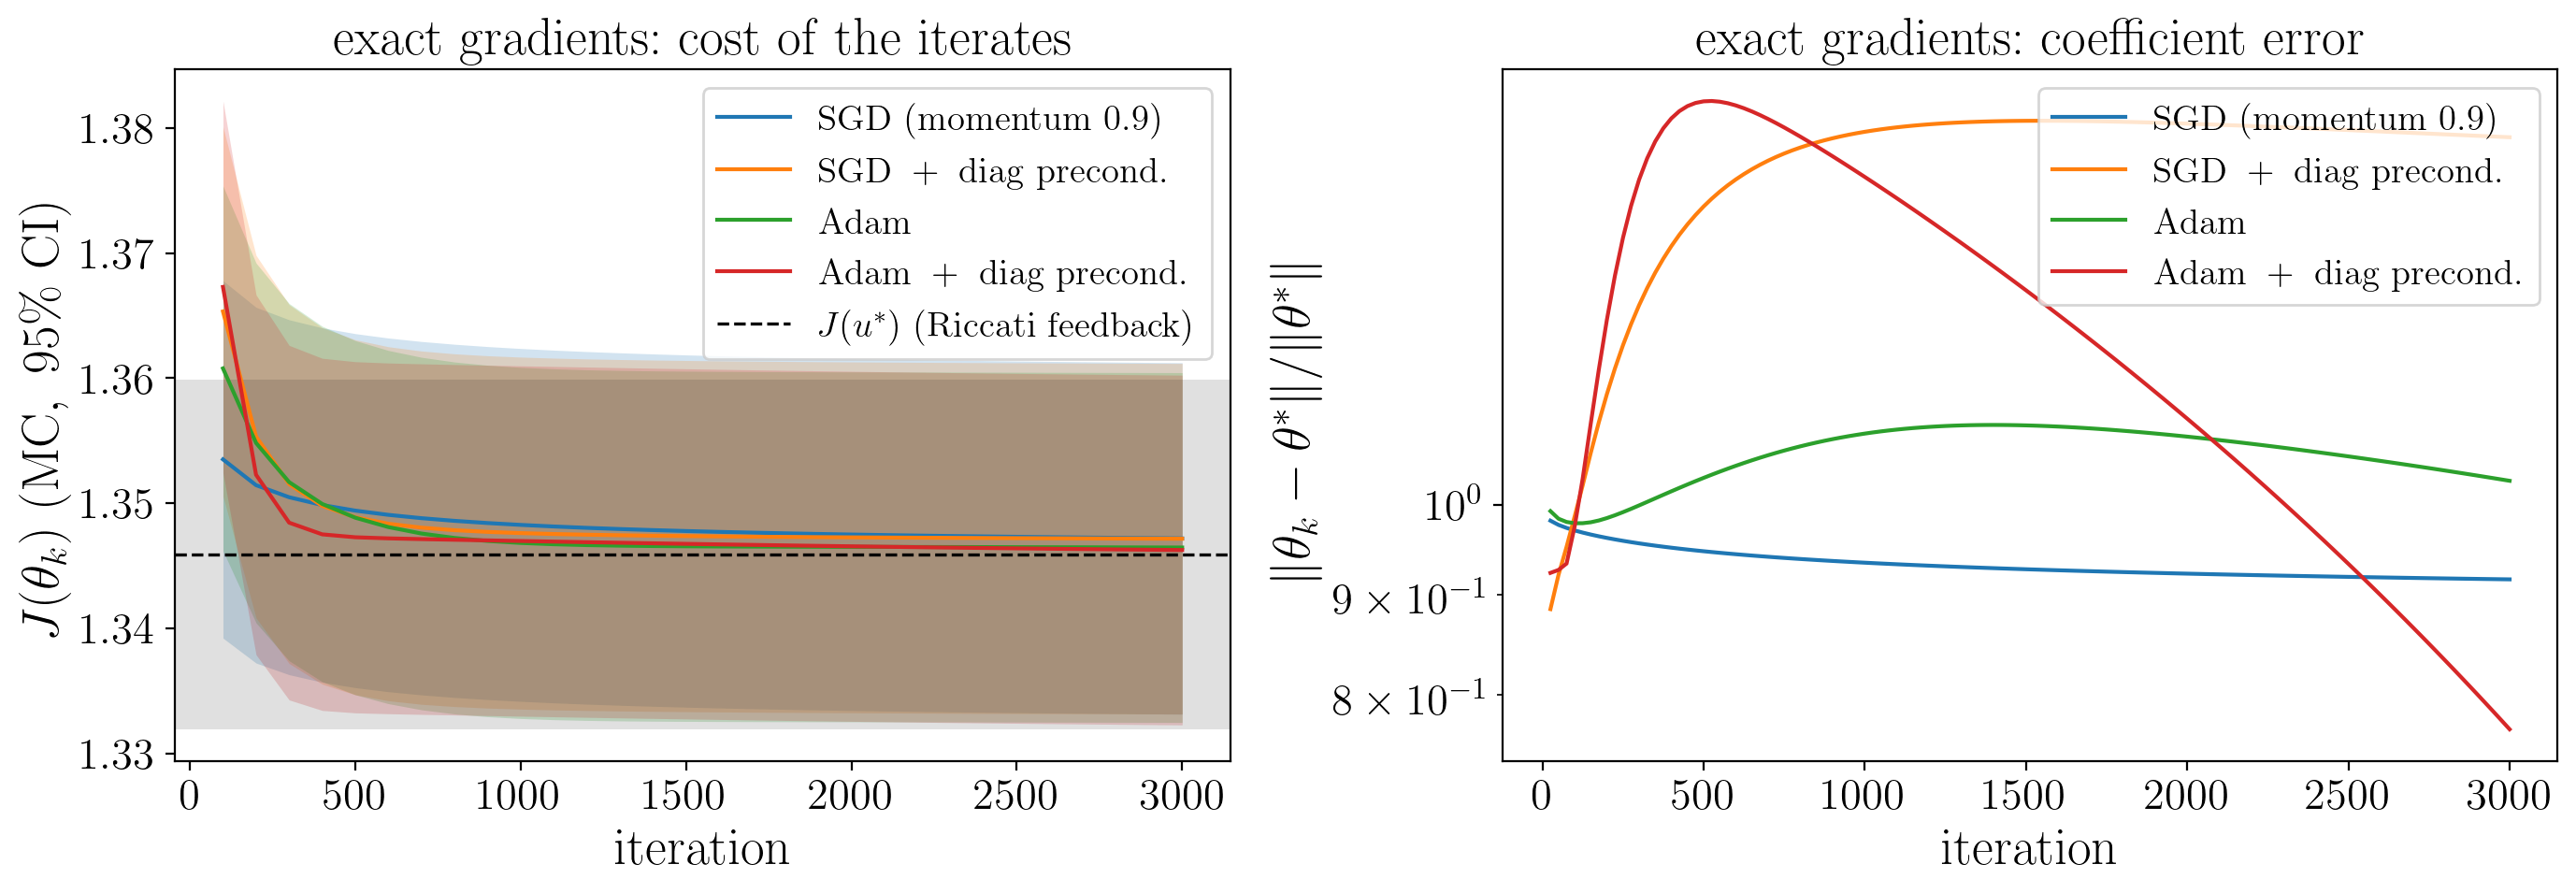

excess cost over u*  [paired MC, 5000 paths, 250 steps: mean ± 95% CI]
             closed form: J^L = 1.347175   excess = 0.000060 ± 0.000040
      SGD (momentum 0.9): J^L = 1.348404   excess = 0.001301 ± 0.000205   (0.1s)
     SGD + diag precond.: J^L = 1.348255   excess = 0.001277 ± 0.000137   (0.1s)
                    Adam: J^L = 1.347606   excess = 0.000575 ± 0.000081   (0.1s)
    Adam + diag precond.: J^L = 1.347421   excess = 0.000375 ± 0.000070   (0.2s)


In [25]:
# Deterministic gradient (mode='exact'): SGD vs Adam, with and without diagonal preconditioning
L, M = 6, 3
F63 = CostFunctionals(mm.D, mm.T, L, M, mm.m_max)
ref = fit_signature_control(mm, L, M, method='closed_form', F=F63)
print(f"closed form: J^L(θ*) = {ref['value']:.6f},  cond(H) = {np.linalg.cond(ref['H']):.2e}")
runs_exact = {
    "SGD (momentum 0.9)":        dict(method='sgd',  lr=0.05),
    "SGD + diag precond.":       dict(method='sgd',  lr=0.02, precondition='diag'),
    "Adam":                      dict(method='adam', lr=0.05),
    "Adam + diag precond.":      dict(method='adam', lr=0.05, precondition='diag'),
}
decay = lambda k: 1.0 / (1.0 + k / 1000)     # without decay, constant-step Adam shows spikes near the optimum
res_exact = {name: fit_signature_control(mm, L, M, mode='exact', n_iter=3000, eval_every=25, average_tail=0, F=F63,
                                         lr_decay=decay, **kw)
             for name, kw in runs_exact.items()}

# Monte Carlo cost of the iterates: one joint simulation on common noise (Itô Euler, 5,000 paths, 250 steps)
n_mc9, steps_mc9 = 5000, 250; dt_mc9 = mm.T / steps_mc9
dW_mc9 = np.random.default_rng(9).normal(scale=np.sqrt(dt_mc9), size=(n_mc9, steps_mc9, mm.D))
fb9 = riccati_feedback(mm, steps_mc9)
def mc_iterates(runs, every=100):
    """Per-path MC costs of the closed form, of the recorded iterates (every `every` iterations) and of the final θ
    of each run, from one joint simulation.  Returns ({key: per-path costs}, per-path costs of u*);
    keys are ('closed form', 'final'), (run, iteration) and (run, 'final')."""
    items = [(('closed form', 'final'), ref['theta'])]
    for name, o in runs.items():
        hst = o['history']
        items += [((name, int(k)), th) for k, th in zip(hst['it'], hst['theta']) if k % every == 0 or k == hst['it'][-1]]
        items.append(((name, 'final'), o['theta']))
    cost, c_ref, _ = simulate_many(mm, dW_mc9, dt_mc9, [(th, M) for _, th in items], fb9)
    return {key: cost[c] for c, (key, _) in enumerate(items)}, c_ref

def plot_iterates(ax, runs, mc):
    for name in runs:
        its = [k for (nm, k) in mc if nm == name and k != 'final']
        plot_mc(ax, its, [mc[(name, k)] for k in its], label=tex_text(name), fmt='-')

mc9, c_ref9 = mc_iterates(res_exact)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
plot_iterates(ax[0], res_exact, mc9)
for name, o in res_exact.items():
    ax[1].semilogy(o['history']['it'], o['history']['dist'], label=tex_text(name))
plot_mc_hline(ax[0], c_ref9, r"$J(u^*)\ \mathrm{(Riccati\ feedback)}$", color='k', ls='--', lw=1.2)
ax[0].set_ylabel(r"$J(\theta_k)\ \mathrm{(MC,\ 95\%\ CI)}$")
ax[1].set_ylabel(r"$\|\theta_k-\theta^*\|/\|\theta^*\|$")
for a in ax: a.set_xlabel(tex_text("iteration")); a.legend()
ax[0].set_title(tex_text("exact gradients: cost of the iterates")); ax[1].set_title(tex_text("exact gradients: coefficient error"))
plt.tight_layout(); save_figure(fig, "exact_gradients_convergence"); plt.show()
print(f"excess cost over u*  [paired MC, {n_mc9} paths, {steps_mc9} steps: mean ± 95% CI]")
print(f"{'closed form':>24}: J^L = {ref['value']:.6f}   excess = {fmt_mc(mc9[('closed form', 'final')] - c_ref9, 6)}")
for name, o in res_exact.items():
    print(f"{name:>24}: J^L = {o['value']:.6f}   excess = {fmt_mc(mc9[(name, 'final')] - c_ref9, 6)}   ({o['time']:.1f}s)")

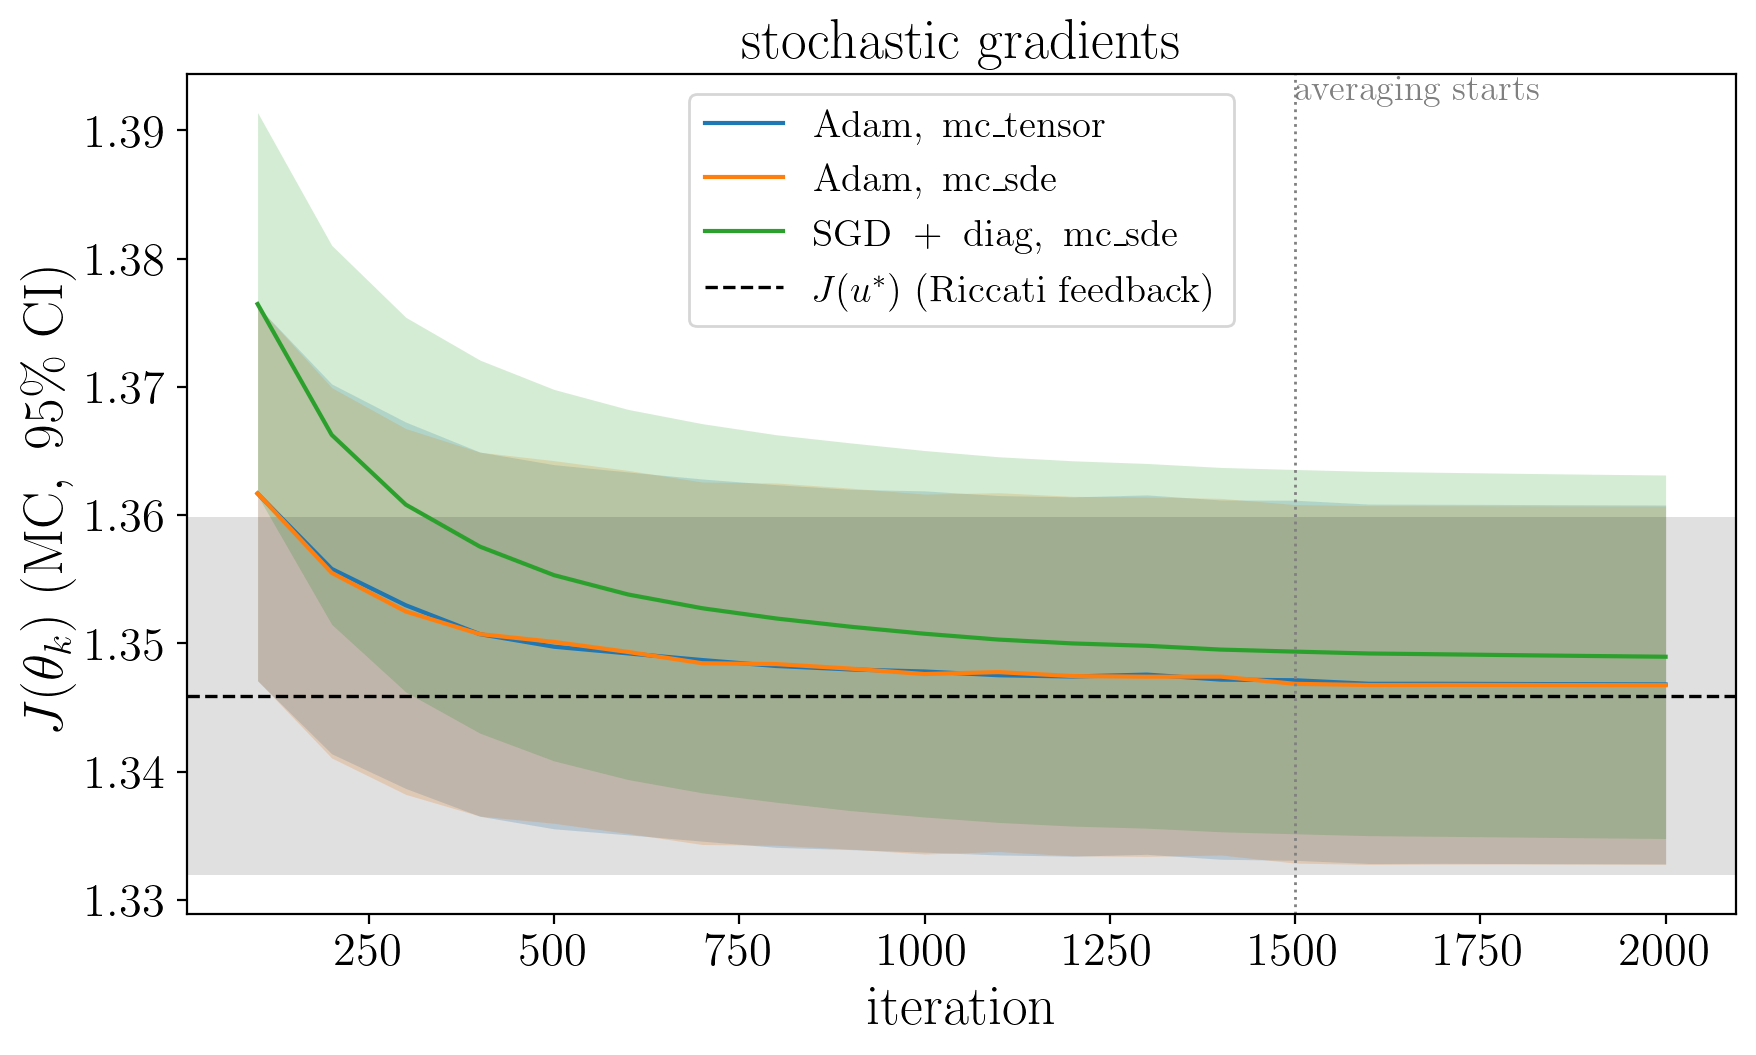

excess cost over u*  [paired MC, 5000 paths, 250 steps: mean ± 95% CI]
                method |    J^L(θ) |                     excess over u* | time
           closed form |  1.347175 |                0.000060 ± 0.000040 |
       Adam, mc_tensor |  1.348012 |                0.000925 ± 0.000148 | 18.2s
          Adam, mc_sde |  1.347967 |                0.000866 ± 0.000134 | 18.0s
    SGD + diag, mc_sde |  1.350239 |                0.003083 ± 0.000327 | 16.2s


96896

In [26]:
# Stochastic gradients (Monte Carlo) – no expected signature needed
lr_sched = lambda k: 1.0 / (1.0 + k / 500)
runs_mc = {
    "Adam, mc_tensor":          dict(method='adam', mode='mc_tensor', lr=0.05, n_pool=2048, record_every=4),
    "Adam, mc_sde":             dict(method='adam', mode='mc_sde',    lr=0.05, n_pool=4096, record_every=2),
    "SGD + diag, mc_sde":       dict(method='sgd',  mode='mc_sde',    lr=0.01, n_pool=4096, record_every=2,
                                     precondition='diag'),
}
res_mc = {name: fit_signature_control(mm, L, M, n_iter=2000, batch_size=256, n_steps=100, lr_decay=lr_sched,
                                      average_tail=0.25, eval_every=50, seed=3, F=F63, **kw)
          for name, kw in runs_mc.items()}
mc9s, c_ref9s = mc_iterates(res_mc)
fig, ax = plt.subplots(figsize=(9, 5.5))
plot_iterates(ax, res_mc, mc9s)
plot_mc_hline(ax, c_ref9s, r"$J(u^*)\ \mathrm{(Riccati\ feedback)}$", color='k', ls='--', lw=1.2)
ax.axvline(0.75 * 2000, color='grey', ls=':', lw=1)
ax.text(0.75 * 2000, ax.get_ylim()[1], tex_text(" averaging starts"), va='top', fontsize=13, color='grey')
ax.set_xlabel(tex_text("iteration")); ax.set_ylabel(r"$J(\theta_k)\ \mathrm{(MC,\ 95\%\ CI)}$")
ax.set_title(tex_text("stochastic gradients")); ax.legend()
plt.tight_layout(); save_figure(fig, "stochastic_gradients_convergence"); plt.show()
print(f"excess cost over u*  [paired MC, {n_mc9} paths, {steps_mc9} steps: mean ± 95% CI]")
print(f"{'method':>22} | {'J^L(θ)':>9} | {'excess over u*':>34} | time")
print(f"{'closed form':>22} | {ref['value']:9.6f} | {fmt_mc(mc9s[('closed form', 'final')] - c_ref9s, 6):>34} |")
for name, o in res_mc.items():
    print(f"{name:>22} | {o['value']:9.6f} | {fmt_mc(mc9s[(name, 'final')] - c_ref9s, 6):>34} | {o['time']:.1f}s")
del F63, F; import gc; gc.collect()          # free the L=6 functionals before the fBM section

With exact gradients and a decaying step, Adam with diagonal preconditioning ends within about $2\times10^{-4}$ (relative) of $J^{\rm L}(\theta^*)$ after 3,000 iterations, which take a fraction of a second. Plain Adam and momentum-SGD are somewhat slower. Note how slowly the coefficients themselves converge, even though the objective gap is small.
With stochastic gradients, 2,000 Adam iterations reach a paired Monte-Carlo excess cost of about $6$–$7\times10^{-4}$ of $J(u^*)$. That is on the level of the closed-form $M=2$ control ($5.7\times10^{-4}$ in §7), not yet of the closed-form $M=3$ control ($4\times10^{-5}$).
In the cost plots the 95% bands of $J(\theta_k)$ are much wider than the differences between methods: each band is the CI of an absolute cost, whose per-path spread is large. The paired excess costs in the tables, computed on the same paths, resolve the differences.
The remainder comes from the ill-conditioning described above and from Monte-Carlo noise; more iterations, larger batches, or a longer averaging window reduce it. Plain SGD converges more slowly than Adam on this problem, even with preconditioning.

Two differences between the modes matter in practice:
* `mc_sde` optimises the *true* cost $J(\theta)$, so it is not affected by state truncation. It is the natural choice when $L$ would have to be large, for example with large $X_0$ as in the 1-D example.
* `mc_tensor` and `mc_sde` never use the expected signature, so they apply unchanged to drivers without a Fawcett-type formula (Section 3.5). With `mc_tensor`, pass the driver's increments via `increments=`.

The closed form remains the method of choice whenever $H$ is available and $P$ is moderate. Numerical optimisation pays off when $P=K\dim T^M$ is large, the expected signature is unknown, or the cost is not quadratic, for instance after adding constraints or penalties to `mc_loss_grad`.

## 10. Fractional Brownian motion

This section replaces $W$ by a $D$-dimensional fractional Brownian motion $B^H$ with independent components (Section 3.5 of the paper).
The tensors $\mathtt X^{(n)}$ from (3.2) and the algebraic form of $\mathtt J^{\rm L}(\mathtt u)$ **do not depend on the driver**, so the state solvers (A)/(B)/(C) and the quadratic assembly are reused unchanged. Three things change.

**1. The expected signature.** $\mathbb E[\widehat{\mathbb B}^H_T]$ has no Fawcett-type formula, so it is replaced by the empirical measure of simulated paths, as in the paper.
Shuffle identities hold path by path, which gives
$\langle(\mathbf 1^{\otimes m}⧢\mathbf v⧢\mathbf w)\otimes\mathbf 1,\hat{\mathbb E}[\widehat{\mathbb B}_T]\rangle=\hat{\mathbb E}\int_0^T\frac{t^m}{m!}\widehat{\mathbb B}^{\mathbf v}_t\widehat{\mathbb B}^{\mathbf w}_t\,dt$.
`EmpiricalCostFunctionals` therefore builds the pairing matrices directly from signatures up to level $\max(L,M)$, rather than estimating $\hat{\mathbb E}[\widehat{\mathbb B}_T]$ up to level $2L+m_{\max}+1$. It is a drop-in replacement for `CostFunctionals`, and `.restrict(L, M)` returns the functionals for any smaller truncation from the same paths at no cost.

**2. Meaning and simulation of the SDE.** The equation is read in the rough-path (Wong–Zakai) sense: the limit of ODEs driven by the piecewise-linear interpolation of $B^H$. This is the interpretation under which $X_t=\langle\mathtt X,\widehat{\mathbb B}_t\rangle$, with $\widehat{\mathbb B}$ the signature of the interpolated path.
* For $\sigma_2=0$ (additive noise) all interpretations agree, and Euler is used.
* For $\sigma_2\neq0$, `simulate_driver` / `mc_feature_pool(..., driver='general')` solve the piecewise-linear ODE exactly on each step via a matrix exponential.

A caveat on roughness: for $D\ge2$ and $H\le\frac14$, the Lévy areas of the interpolations do not converge. We therefore use $D=1$ at $H=\frac14$, as the paper does, and $H=0.35$ for the 2-D example.

**3. Benchmark: Duncan & Pasik-Duncan (SICON 51(6), 2013), Thm 3.3 / Cor. 3.4.** For $\sigma_2=0$, i.e. $dX=(b_0+b_2X+b_1u)\,dt+\sigma_0\,dB^H$, the optimal adapted control is
$$u^*_t=-B(t)^{-1}\Big(D(t)+b_1^\top\big(P_tX_t+r_t+V_t\big)\Big),\qquad V_t=\mathbb E\Big[\int_t^T\Phi_P(s,t)P(s)\sigma_0\,dB^H_s\,\Big|\,\mathcal F_t\Big],$$
$$\partial_t\Phi_P(s,t)=-\big(b_2-b_1B^{-1}b_1^\top P\big)(t)^\top\,\Phi_P(s,t),\qquad \Phi_P(s,s)=I.$$
$P$ and $r$ are the deterministic Riccati and affine terms from §5. $V$ is the minimum mean-square prediction of the closed-loop response to the *future* noise. It vanishes for $H=\frac12$, and its presence makes the optimal control non-Markovian in $X$.
The paper writes the conditional expectation with fractional integrals (their Prop. 2.2). On the simulation grid we compute it **exactly by Gaussian conditioning**: with $\Delta B=\mathrm{chol}\,\xi$, $\mathbb E[\Delta B_j\,|\,\Delta B_0,\dots,\Delta B_{i-1}]=\sum_{k<i}\mathrm{chol}_{jk}\xi_k$, so $V_i=\sum_{k<i}K_{ik}\xi_k$ with a deterministic kernel $K$, built by the backward recursion $\varphi_i=P_i\sigma_0\Delta B_i+\Phi_P(t_{i+1},t_i)\varphi_{i+1}$.
Under this feedback $X$ is Gaussian and linear in $\xi$, so the **expected cost of the benchmark is computed exactly**, by propagating the mean and the $\xi$-loadings, with no Monte Carlo (`exact_cost`).

**Evaluation.** All controls are evaluated **out of sample** on fresh paths with common random numbers. We report paired cost differences to the benchmark with 95% confidence intervals, and the $L^2(d\mathbb P\otimes dt)$ distance to $u^*$, as in the paper's Figure 2.

In [27]:
def fbm_cholesky(H, n_steps, T):
    """Lower Cholesky factor of the covariance of the fBM increments on a uniform grid."""
    from scipy.linalg import toeplitz
    k = np.arange(n_steps, dtype=float); h = T / n_steps
    g = 0.5 * (np.abs(k + 1) ** (2 * H) + np.abs(k - 1) ** (2 * H) - 2 * k ** (2 * H)) * h ** (2 * H)
    return np.linalg.cholesky(toeplitz(g))

def fbm_increments(H, n_paths, n_steps, D, T, rng, chol=None, return_xi=False):
    """D independent fBMs: ΔB = chol @ ξ, ξ i.i.d. N(0,1).  Returns (n_paths, n_steps, D) [and ξ, same shape]."""
    chol = fbm_cholesky(H, n_steps, T) if chol is None else chol
    xi = rng.standard_normal((n_steps, n_paths * D))
    dB = (chol @ xi).reshape(n_steps, n_paths, D).transpose(1, 0, 2)
    return (dB, xi.reshape(n_steps, n_paths, D).transpose(1, 0, 2)) if return_xi else dB

def dpd_benchmark(model, H, n_steps, chol=None):
    """Duncan & Pasik-Duncan (SICON 2013, Thm 3.3 / Cor. 3.4), discretised on the simulation grid.
    For σ2 = 0 (additive noise σ0 dB^H, B^H a D-dim fBM) the optimal adapted control is
        u*_t = -B(t)^{-1} ( D(t) + b1' (P_t X_t + r_t + V_t) ),   V_t = E[ φ_t | F_t ],
        φ_t = ∫_t^T Φ_P(s,t) P(s) σ0 dB^H_s,   ∂_t Φ_P(s,t) = -(b2 - b1 B^{-1} b1' P)(t)' Φ_P(s,t),  Φ_P(s,s) = I,
    with the deterministic Riccati P and the affine term r (Section 5).  On the grid, φ_i = P_i σ0 ΔB_i + Γ_i φ_{i+1},
    and with ΔB = chol ξ the prediction is exact Gaussian conditioning:  E[ΔB_j | ΔB_0..ΔB_{i-1}] = Σ_{k<i} chol_{jk} ξ_k,
    hence V_i = Σ_{k<i} K[i,k] ξ_k with a deterministic kernel K."""
    from scipy.linalg import expm
    assert not np.any(model.sigma2), "the Duncan–Pasik-Duncan benchmark requires sigma2 = 0 (additive noise)"
    N, D, T = model.N, model.D, model.T; n = n_steps; dt = T / n
    chol = fbm_cholesky(H, n, T) if chol is None else chol
    ric = riccati_benchmark(model, n_grid=n + 1); P, r, t = ric['P'], ric['r'], ric['t']
    Binv = np.stack([np.linalg.inv(LQModel.poly(model.B, s)) for s in t])
    Acl = np.stack([model.b2 - model.b1 @ Binv[i] @ model.b1.T @ P[i] for i in range(n + 1)])
    K = np.zeros((n + 1, n, N, D))
    for i in range(n - 1, -1, -1):
        Gam = expm(0.5 * (Acl[i] + Acl[i + 1]).T * dt)                  # Φ_P(t_{i+1}, t_i)
        K[i] = np.einsum('nd,k->knd', P[i] @ model.sigma0, chol[i]) + np.einsum('nm,kmd->knd', Gam, K[i + 1])
    K = K[:n] * (np.arange(n)[None, :] < np.arange(n)[:, None])[:, :, None, None]     # keep k < i only
    Kmat = K.transpose(0, 2, 1, 3).reshape(n * N, n * D)
    def V_of(xi):            # xi: (paths, n, D) -> V: (paths, n, N)
        return (xi.reshape(xi.shape[0], n * D) @ Kmat.T).reshape(xi.shape[0], n, N)
    def control_factory(V, scale=1.0):
        def ctrl(i, s, X, sig):
            return -(LQModel.poly(model.Dlin, s) + (X @ P[i].T + r[i] + scale * V[:, i]) @ model.b1) @ Binv[i].T
        return ctrl
    def exact_cost(scale=1.0):
        """Exact expected cost of the discretised feedback (Euler, left-point running cost): X is Gaussian
        and linear in ξ, so we propagate its mean and its loading on ξ (no Monte Carlo)."""
        a = model.b0; m = model.X0.astype(float).copy(); Lam = np.zeros((N, n * D)); J = 0.0
        for i in range(n):
            s = t[i]; At, Bt = LQModel.poly(model.A, s), LQModel.poly(model.B, s)
            Ct, Dt = LQModel.poly(model.C, s), LQModel.poly(model.Dlin, s)
            kap = scale * K[i].transpose(1, 0, 2).reshape(N, n * D)
            um = -Binv[i] @ (Dt + model.b1.T @ (P[i] @ m + r[i])); U = -Binv[i] @ model.b1.T @ (P[i] @ Lam + kap)
            J += dt * (m @ At @ m + np.sum(Lam * (At @ Lam)) + um @ Bt @ um + np.sum(U * (Bt @ U)) + 2 * Ct @ m + 2 * Dt @ um)
            ell = np.zeros((D, n * D))
            for dd in range(D): ell[dd, dd::D] = chol[i]
            m = m + (a + model.b2 @ m + model.b1 @ um) * dt
            Lam = Lam + (model.b2 @ Lam + model.b1 @ U) * dt + model.sigma0 @ ell
        return J + m @ model.E @ m + np.sum(Lam * (model.E @ Lam)) + 2 * model.G @ m
    return dict(P=P, r=r, t=t, K=K, chol=chol, V_of=V_of, control=control_factory, exact_cost=exact_cost, H=H)

def _wz_step_matrices(model, beta, dt):
    """Exact step of the linear ODE obtained by freezing the piecewise-linear driver slope β on one step:
    dX/ds = (b2 + Σ_d σ2_d β_d) X + const  ->  X' = E X + Φ·const,  E = e^{Mh}, Φ = ∫_0^h e^{sM} ds."""
    from scipy.linalg import expm
    N = model.N; n = beta.shape[0]
    M = model.b2[None] + np.einsum('pd,ndm->pnm', beta, model.sigma2)
    Aug = np.zeros((n, 2 * N, 2 * N)); Aug[:, :N, :N] = M * dt; Aug[:, :N, N:] = np.eye(N) * dt
    Ex = expm(Aug)
    return Ex[:, :N, :N], Ex[:, :N, N:]

def simulate_driver(model, dB, dt, control, sig_level=0, scheme='auto'):
    """State simulation for a general driver (e.g. fBM), SDE understood in the Stratonovich / rough-path
    (Wong–Zakai) sense, i.e. as the limit of ODEs driven by the piecewise-linear interpolation of the driver.
    scheme='euler' (valid only for sigma2 = 0, where all interpretations agree) or
    'wz' (exact solution of the piecewise-linear ODE on each step; control frozen at the left point).
    Cost: left-point Riemann sum.  control(i, t, X, sig) -> (n, K)."""
    if scheme == 'auto': scheme = 'euler' if not np.any(model.sigma2) else 'wz'
    if scheme == 'euler': assert not np.any(model.sigma2), "Euler is only consistent for sigma2 = 0"
    n, steps, D = dB.shape
    X = np.tile(model.X0.astype(float), (n, 1)); cost = np.zeros(n); Xs = [X.copy()]; Us = []
    stream = signature_stream(dB, dt, sig_level) if sig_level > 0 else None
    for i in range(steps):
        t = i * dt; sig = next(stream) if stream is not None else None
        u = control(i, t, X, sig); Us.append(u)
        At, Bt, Ct, Dt = (LQModel.poly(model.A, t), LQModel.poly(model.B, t), LQModel.poly(model.C, t), LQModel.poly(model.Dlin, t))
        cost += dt * (np.einsum('pi,ij,pj->p', X, At, X) + np.einsum('pi,ij,pj->p', u, Bt, u) + 2 * X @ Ct + 2 * u @ Dt)
        if scheme == 'euler':
            X = X + (model.b0 + X @ model.b2.T + u @ model.b1.T) * dt + dB[:, i] @ model.sigma0.T
        else:
            beta = dB[:, i] / dt
            Em, Ph = _wz_step_matrices(model, beta, dt)
            c = model.b0 + u @ model.b1.T + beta @ model.sigma0.T
            X = np.einsum('pnm,pm->pn', Em, X) + np.einsum('pnm,pm->pn', Ph, c)
        Xs.append(X.copy())
    cost += np.einsum('pi,ij,pj->p', X, model.E, X) + 2 * X @ model.G
    return cost, np.array(Xs), np.array(Us)

class EmpiricalCostFunctionals:
    """Drop-in replacement for CostFunctionals when E[Ŵ_T] has no closed form (Section 3.5):
    the expected signature is replaced by the empirical measure of simulated driver paths.  Because shuffle
    identities hold pathwise,  <(1^{⊗m} ш v ш w)⊗1, Ê[Ŵ_T]> = Ê ∫ t^m/m! Ŵ^v_t Ŵ^w_t dt,  so only signatures up to
    level max(L, M) are needed (instead of level 2L+m+1); the dt-integral uses the trapezoid rule on the recorded grid."""
    def __init__(self, model, L, M, dB, dt, record_every=1, chunk=2000):
        d = model.d; Lb = max(L, M); tb = TensorSpace(d, Lb); self.L, self.M, self.d = L, M, d
        n_paths, n_steps, _ = dB.shape
        rec = list(range(0, n_steps + 1, record_every))
        if rec[-1] != n_steps: rec.append(n_steps)
        tg = np.array(rec) * dt; w = np.zeros(len(rec)); w[1:] += 0.5 * np.diff(tg); w[:-1] += 0.5 * np.diff(tg)
        recpos = {i: j for j, i in enumerate(rec)}; mm = model.m_max
        G = [np.zeros((tb.dim, tb.dim)) for _ in range(mm + 1)]; l = [np.zeros(tb.dim) for _ in range(mm + 1)]
        GT, lT = np.zeros((tb.dim, tb.dim)), np.zeros(tb.dim)
        for c0 in range(0, n_paths, chunk):
            for i, sig in enumerate(signature_stream(dB[c0:c0 + chunk], dt, Lb)):
                if i not in recpos: continue
                j = recpos[i]; SS = sig.T @ sig; s1 = sig.sum(0)
                for m in range(mm + 1):
                    c = w[j] * tg[j] ** m / factorial(m); G[m] += c * SS; l[m] += c * s1
                if i == n_steps: GT += SS; lT += s1
        dL, dM = TensorSpace(d, L).dim, TensorSpace(d, M).dim
        self.Grun = [g[:dL, :dL] / n_paths for g in G]; self.GrunU = [g[:dM, :dM] / n_paths for g in G]
        self.lrun = [v[:dL] / n_paths for v in l]; self.lrunU = [v[:dM] / n_paths for v in l]
        self.Gterm = GT[:dL, :dL] / n_paths; self.lterm = lT[:dL] / n_paths
        self._full = (G, l, GT, lT, n_paths)

    def restrict(self, L, M):
        """Functionals for smaller (L, M) from the same paths: just sub-blocks (no recomputation)."""
        assert L <= self.L or M <= self.M
        G, l, GT, lT, n = self._full
        out = EmpiricalCostFunctionals.__new__(EmpiricalCostFunctionals)
        dL, dM = TensorSpace(self.d, L).dim, TensorSpace(self.d, M).dim
        assert dL <= G[0].shape[0] and dM <= G[0].shape[0]
        out.L, out.M, out.d, out._full = L, M, self.d, self._full
        out.Grun = [g[:dL, :dL] / n for g in G]; out.GrunU = [g[:dM, :dM] / n for g in G]
        out.lrun = [v[:dL] / n for v in l]; out.lrunU = [v[:dM] / n for v in l]
        out.Gterm = GT[:dL, :dL] / n; out.lterm = lT[:dL] / n
        return out

def pad_theta(theta, model, M_from, M_to):
    """Embed θ ∈ (T^{M_from})^K into (T^{M_to})^K (flat prefix per control component)."""
    d1, d2 = TensorSpace(model.d, M_from).dim, TensorSpace(model.d, M_to).dim
    return np.pad(theta.reshape(model.K, d1), ((0, 0), (0, d2 - d1))).ravel()

def pathwise_cost(model, theta, F, S, t, w):
    """Per-path cost of u = <θ, Ŵ> from features (F, S) of mc_feature_pool (θ padded to the pool's M).
    w: quadrature weights on the recorded grid t (e.g. left Riemann for consistency with simulate_driver)."""
    K = model.K; dimM = S.shape[-1]; th = np.pad(theta.reshape(K, -1), ((0, 0), (0, dimM - theta.size // K)))
    X = F[..., 0] + F[..., 1:] @ th.ravel(); u = S @ th.T
    cw = _cost_weights(model, t)
    run = (np.einsum('brn,rnm,brm->br', X, cw['At'], X) + np.einsum('brk,rkj,brj->br', u, cw['Bt'], u)
           + 2 * np.einsum('brn,rn->br', X, cw['Ct']) + 2 * np.einsum('brk,rk->br', u, cw['Dt']))
    XT = X[:, -1]
    return run @ w + np.einsum('bn,nm,bm->b', XT, model.E, XT) + 2 * XT @ model.G


def evaluate_controls(model, controls, dB, dt, reference=None):
    """Out-of-sample Monte Carlo with common random numbers.
    controls: name -> (callable, sig_level).  Returns name -> dict(cost=per-path costs, U=control paths),
    and, if `reference` names one of the controls, paired cost differences and L2(dP⊗dt) distances to it."""
    out = {}; names = list(controls)
    if reference is not None: names = [reference] + [k for k in names if k != reference]
    Uref = None
    for name in names:
        ctrl, lev = controls[name]
        c, _, U = simulate_driver(model, dB, dt, ctrl, sig_level=lev)
        out[name] = dict(cost=c)
        if reference is not None:
            if name == reference: Uref, cref = U, c
            out[name]['diff'] = c - cref
            out[name]['d2'] = np.sum(dt * np.sum((U - Uref) ** 2, axis=2), axis=0)     # per path: ∫|u - u_ref|² dt
            out[name]['L2'] = np.sqrt(out[name]['d2'].mean())
        del U                                  # control paths are not kept (memory)
    return {k: out[k] for k in controls}


def evaluate_thetas(model, thetas, pool, dt, ref=None):
    """Instant out-of-sample evaluation of many signature controls on one feature pool
    (mc_feature_pool(..., mode='sde', record_every=1)), left-Riemann cost as in simulate_driver.
    thetas: name -> (θ, M).  ref: dict(cost=..., U=...) of a benchmark simulated on the same paths."""
    n_rec = pool['t'].size; w = np.full(n_rec, dt); w[-1] = 0.0
    out = {}
    for name, (th, M) in thetas.items():
        c = pathwise_cost(model, th, pool['F'], pool['S'], pool['t'], w)
        Th = np.pad(th.reshape(model.K, -1), ((0, 0), (0, pool['S'].shape[-1] - th.size // model.K)))
        o = dict(cost=c)
        if ref is not None:
            U = np.einsum('brv,kv->rbk', pool['S'][:, :-1], Th)
            o['diff'] = c - ref['cost']
            o['d2'] = np.sum(dt * np.sum((U - ref['U']) ** 2, axis=2), axis=0)               # per path: ∫|u - u_ref|² dt
            o['L2'] = np.sqrt(o['d2'].mean())
            del U
        out[name] = o
    return out


### Checks of the benchmark
1. At $H=\tfrac12$ the discretised Duncan–Pasik-Duncan cost converges to the Riccati value.
2. Scaling the prediction term $V$ in either direction, or dropping it ($V=0$, the Markovian Riccati feedback), increases the exact cost.
3. Monte Carlo agrees with the exact Gaussian cost.

In [28]:
m1f = LQModel(T=1.0, X0=[1.], b0=[0.], b1=[[1.]], b2=[[1.]], sigma0=[[1.]], sigma2=[[[0.]]],
              A=[[[1.]]], B=[[[1.]]], C=[[0.]], Dlin=[[0.]], E=[[1.]], G=[0.])
print(f"Brownian Riccati J* = {riccati_benchmark(m1f)['J']:.5f}")
for n in [200, 400, 800]:
    print(f"  H = 1/2, n = {n:4d}: discretised Duncan–Pasik-Duncan cost = {dpd_benchmark(m1f, 0.5, n)['exact_cost']():.5f}")
nF = 400
print("\n   H  | J(u*) [DPD] | V scaled 0.8 | V scaled 1.2 | V = 0 (Markov Riccati)")
for H in [0.25, 0.35, 0.5, 0.65, 0.75]:
    b = dpd_benchmark(m1f, H, nF)
    print(f" {H:4.2f} | {b['exact_cost']():11.5f} | {b['exact_cost'](0.8):12.5f} | {b['exact_cost'](1.2):12.5f} | {b['exact_cost'](0.0):10.5f}")
H = 0.25; chol1 = fbm_cholesky(H, nF, m1f.T); bench1 = dpd_benchmark(m1f, H, nF, chol=chol1)
dB, xi = fbm_increments(H, 20000, nF, 1, m1f.T, np.random.default_rng(1), chol=chol1, return_xi=True)
c, _, _ = simulate_driver(m1f, dB, m1f.T / nF, bench1['control'](bench1['V_of'](xi)))
print(f"\nH = 1/4: Monte Carlo cost of u* = {fmt_mc(c, 4)}  [mean ± 95% CI],  exact = {bench1['exact_cost']():.4f}")

Brownian Riccati J* = 4.03486
  H = 1/2, n =  200: discretised Duncan–Pasik-Duncan cost = 4.04042
  H = 1/2, n =  400: discretised Duncan–Pasik-Duncan cost = 4.03762


  H = 1/2, n =  800: discretised Duncan–Pasik-Duncan cost = 4.03624

   H  | J(u*) [DPD] | V scaled 0.8 | V scaled 1.2 | V = 0 (Markov Riccati)


 0.25 |     4.44575 |      4.45428 |      4.45405 |    4.65657


 0.35 |     4.29371 |      4.29639 |      4.29610 |    4.35776


 0.50 |     4.03762 |      4.03762 |      4.03762 |    4.03762


 0.65 |     3.76908 |      3.77066 |      3.77116 |    3.81356


 0.75 |     3.57972 |      3.58413 |      3.58502 |    3.69894



H = 1/4: Monte Carlo cost of u* = 4.4496 ± 0.0474  [mean ± 95% CI],  exact = 4.4458


### 10.1 One-dimensional example, $H=\tfrac14$, $\sigma_2=0$ (with benchmark)
The model is $dX=(X+u)\,dt+dB^{1/4}$ with $X_0=1$ and cost $\mathbb E[\int_0^1(X^2+u^2)\,dt+X_1^2]$.
The empirical functionals use 8,000 training paths; evaluation uses 5,000 independent test paths on a 400-step grid.

In [29]:
dt1 = m1f.T / nF
t0 = time.perf_counter()
dB_train = fbm_increments(H, 8000, nF, 1, m1f.T, np.random.default_rng(10), chol=chol1)
F1_full = EmpiricalCostFunctionals(m1f, 7, 3, dB_train, dt1, record_every=4)
print(f"empirical functionals (L=7, M=3, 8000 paths): {time.perf_counter() - t0:.1f}s")

# test set: benchmark simulated directly, signature controls evaluated on a feature pool of the same paths
dB_test, xi_test = fbm_increments(H, 5000, nF, 1, m1f.T, np.random.default_rng(99), chol=chol1, return_xi=True)
c_star, _, U_star = simulate_driver(m1f, dB_test, dt1, bench1['control'](bench1['V_of'](xi_test)))
c_mark, _, _ = simulate_driver(m1f, dB_test, dt1, bench1['control'](bench1['V_of'](xi_test), 0.0))
ref1 = dict(cost=c_star, U=U_star)
test_pool1 = mc_feature_pool(m1f, 0, 3, 5000, nF, 1, mode='sde', increments=dB_test, driver='general')

Ls_f, Ms_f = [2, 3, 4, 5, 6, 7], [0, 1, 2, 3]
thetas1 = {}
for L in Ls_f:
    for M in Ms_f:
        r = fit_signature_control(m1f, L, M, method='closed_form', F=F1_full.restrict(L, M),
                                  solver='picard' if L == 7 else 'levelwise')     # the proposed recursion also works here
        thetas1[(L, M)] = (r['theta'], M)
ev1 = evaluate_thetas(m1f, thetas1, test_pool1, dt1, ref=ref1)
print(f"\nexact J(u*) = {bench1['exact_cost']():.4f};  MC on test paths = {fmt_mc(c_star, 4)}")
print(f"Markov Riccati (V=0): excess = {fmt_mc(c_mark - c_star, 4)}\n")
print_grid(ev1, Ls_f, Ms_f, 4)

empirical functionals (L=7, M=3, 8000 paths): 28.0s



exact J(u*) = 4.4458;  MC on test paths = 4.4070 ± 0.0939
Markov Riccati (V=0): excess = 0.2081 ± 0.0082

excess cost J(u^{L,M}) − J(u*)  [paired MC: mean ± 95% CI]     rows: L, cols: M = [0, 1, 2, 3]
L=2:      3.0334 ± 0.1318       0.2507 ± 0.0161       4.0610 ± 0.1695       7.2239 ± 0.2582
L=3:      3.0334 ± 0.1318       0.0979 ± 0.0085       0.3897 ± 0.0212       4.7942 ± 0.1982
L=4:      3.0334 ± 0.1318       0.0938 ± 0.0078       0.0626 ± 0.0030       1.3027 ± 0.0596
L=5:      3.0334 ± 0.1318       0.0939 ± 0.0078       0.0512 ± 0.0026       0.0639 ± 0.0046
L=6:      3.0334 ± 0.1318       0.0939 ± 0.0077       0.0507 ± 0.0026       0.0263 ± 0.0019
L=7:      3.0334 ± 0.1318       0.0939 ± 0.0077       0.0507 ± 0.0026       0.0253 ± 0.0018

L2(dP⊗dt) distance to u*  [± 95% CI]     rows: L, cols: M = [0, 1, 2, 3]
L=2:      1.0660 ± 0.0123       0.3751 ± 0.0023       1.1872 ± 0.0172       1.3757 ± 0.0180
L=3:      1.0664 ± 0.0123       0.2838 ± 0.0024       0.5318 ± 0.0049       1.14

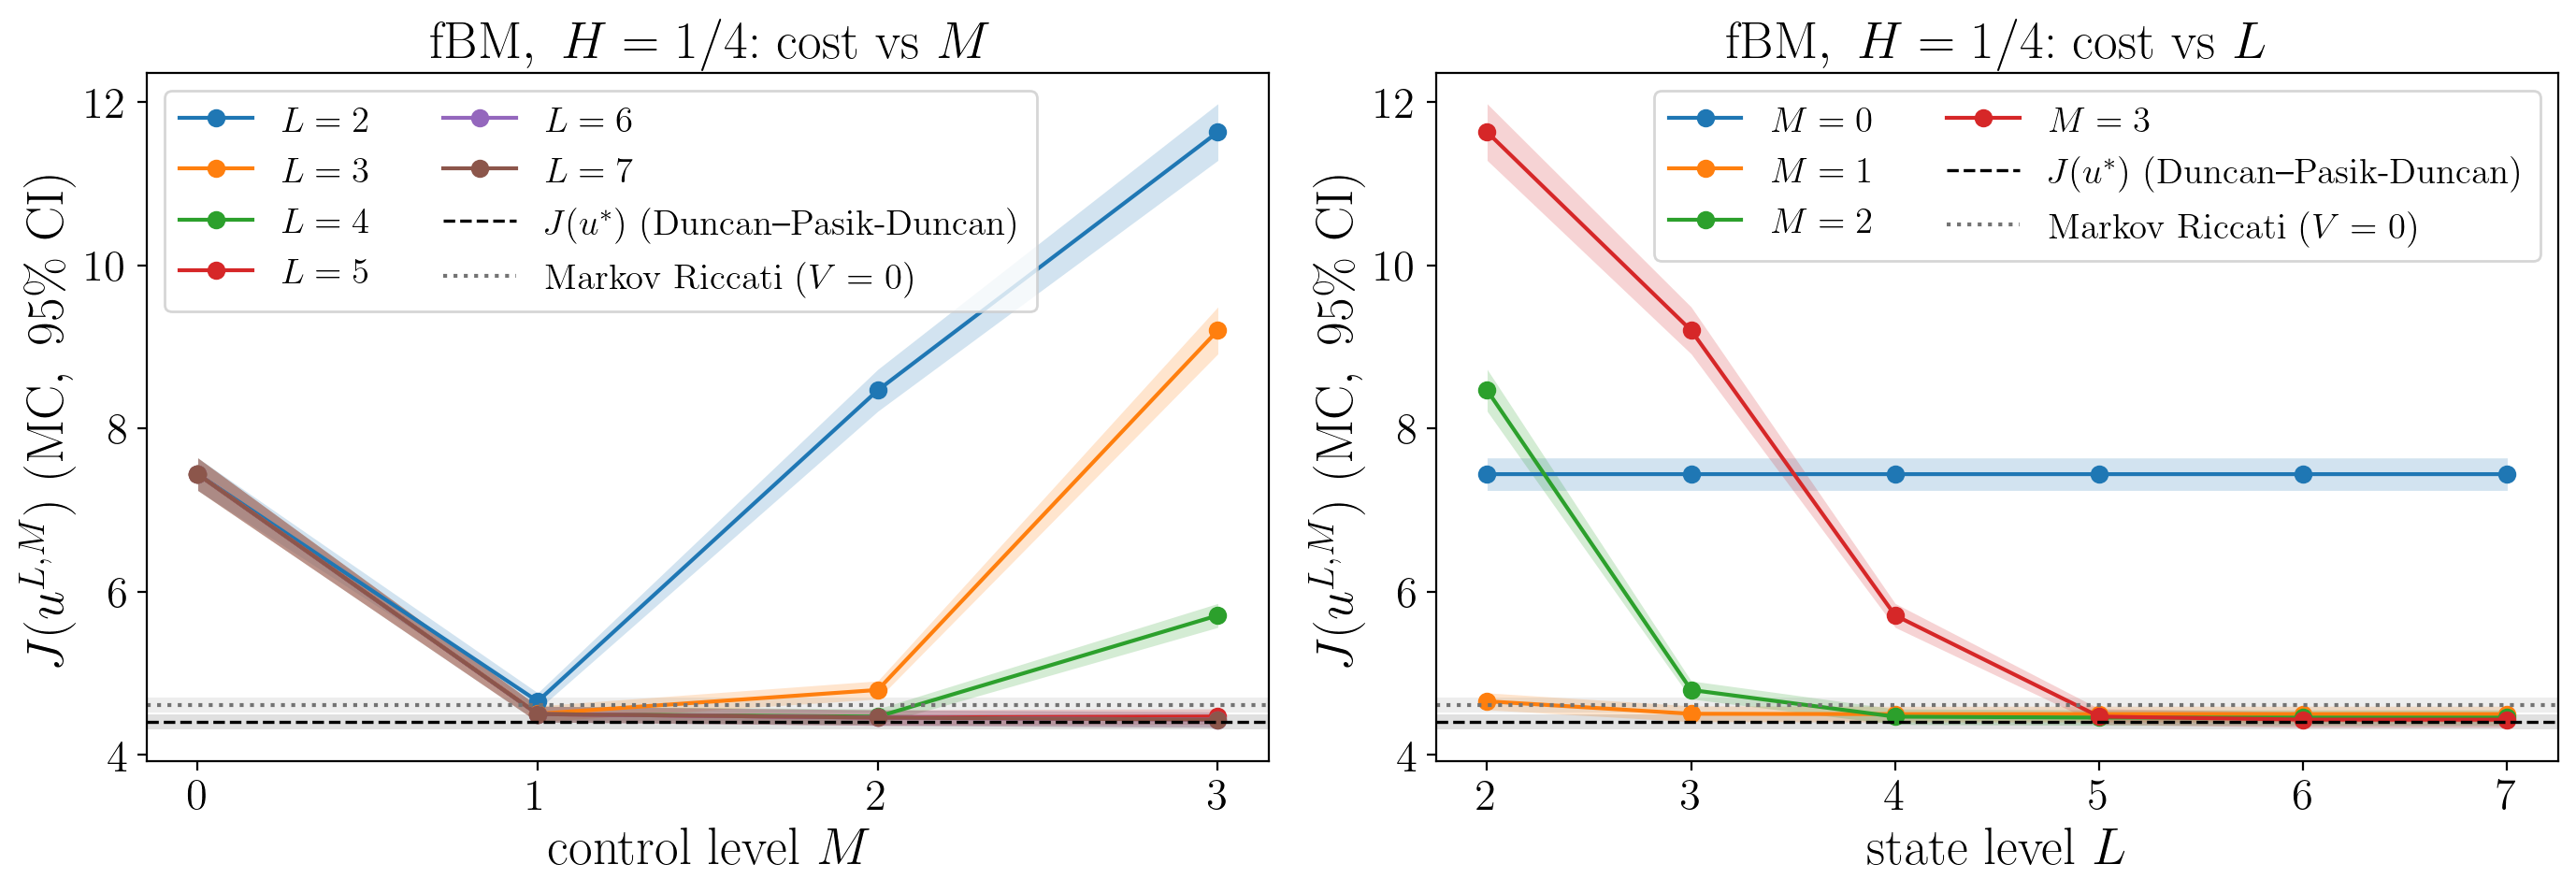

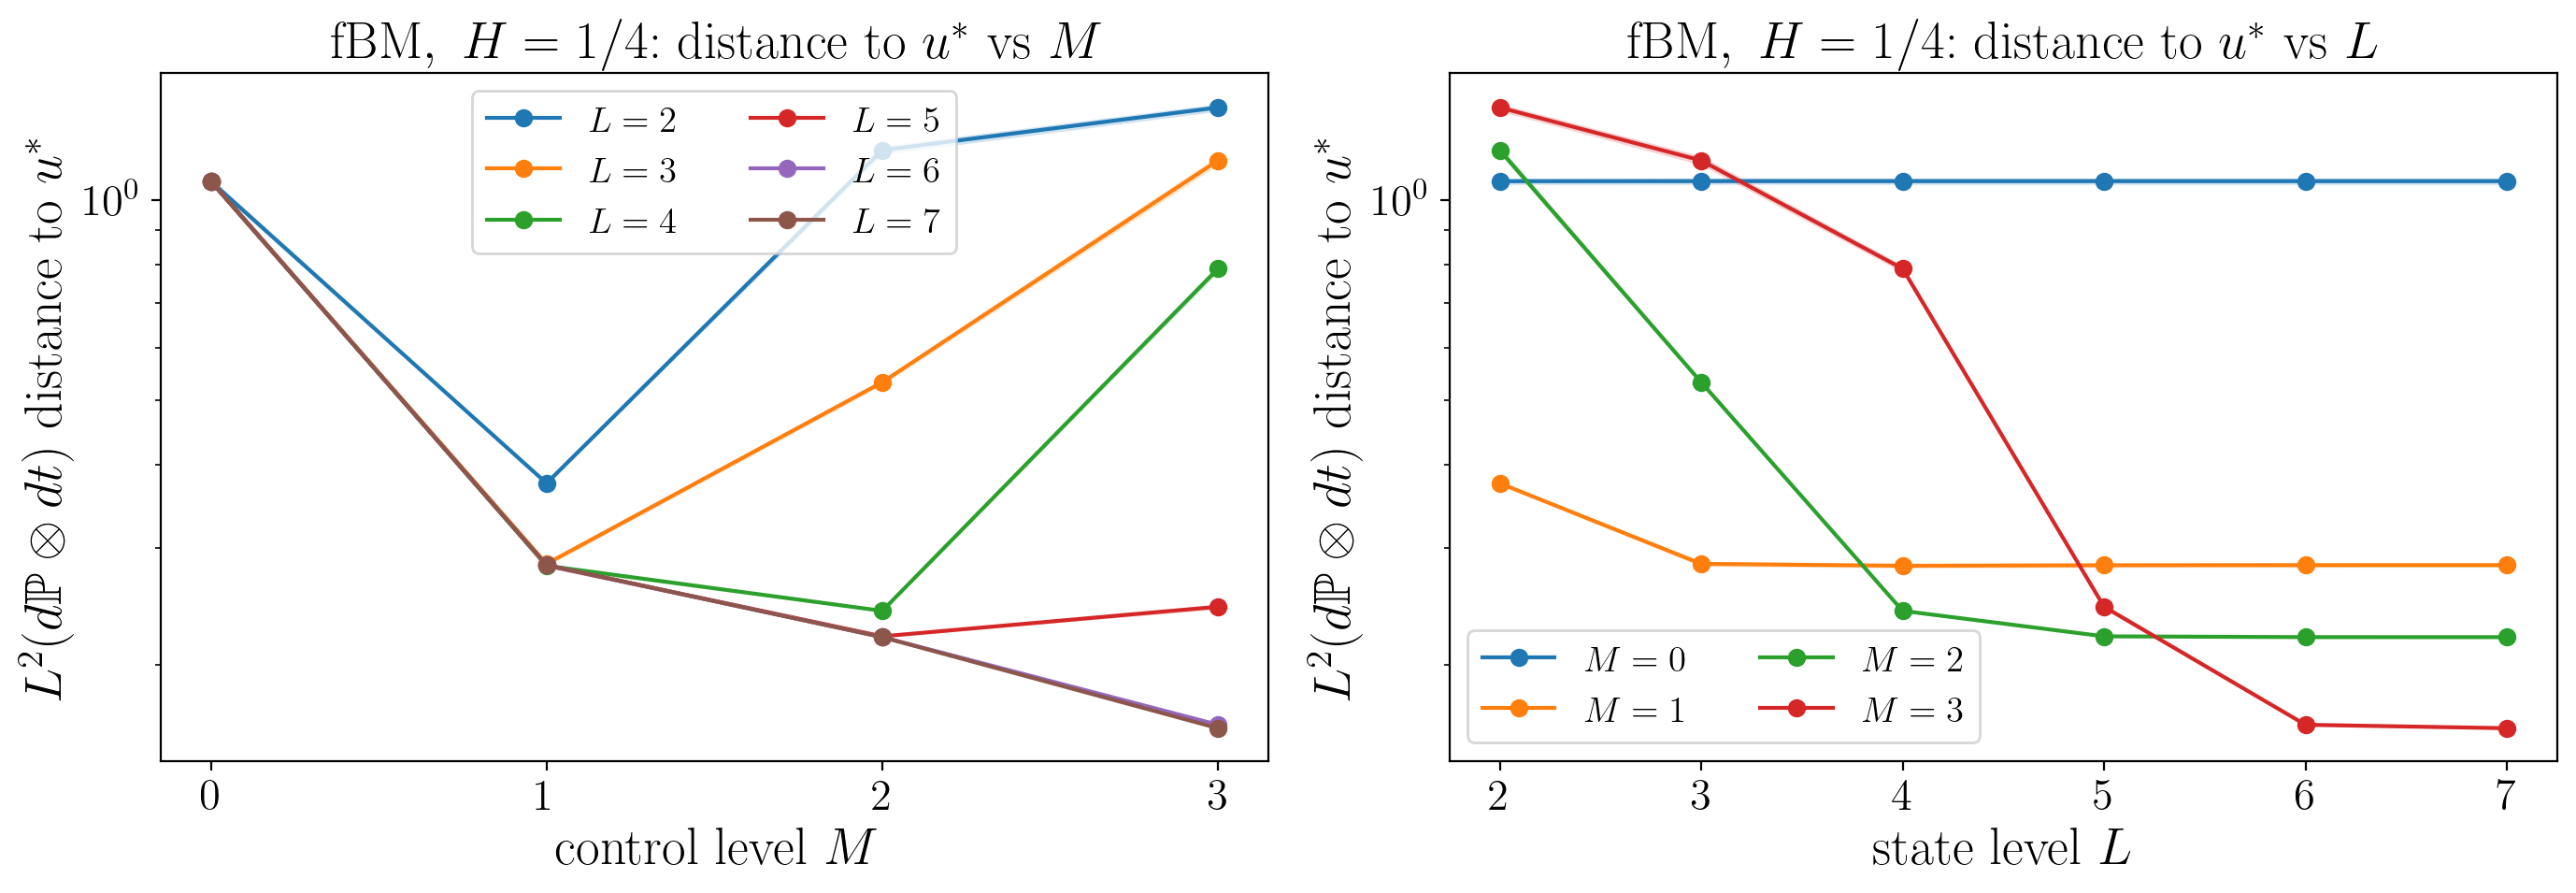

In [30]:
plot_grid(ev1, Ls_f, Ms_f, c_star, r"$J(u^*)\ \mathrm{(Duncan\text{--}Pasik\text{-}Duncan)}$", "fbm_H025",
          r"\mathrm{fBM},\ H=1/4", refs=[(c_mark, r"$\mathrm{Markov\ Riccati}\ (V=0)$")])

### Sample paths: fBM, $H=\tfrac14$, $\sigma_2=0$
All controls below are driven by **the same noise path**. The left panel shows the state and the right panel the control.
The benchmark is drawn in black (and, under fBM, the Markovian Riccati feedback in dashed grey); the signature controls $u^{L,M}$ are in colour.

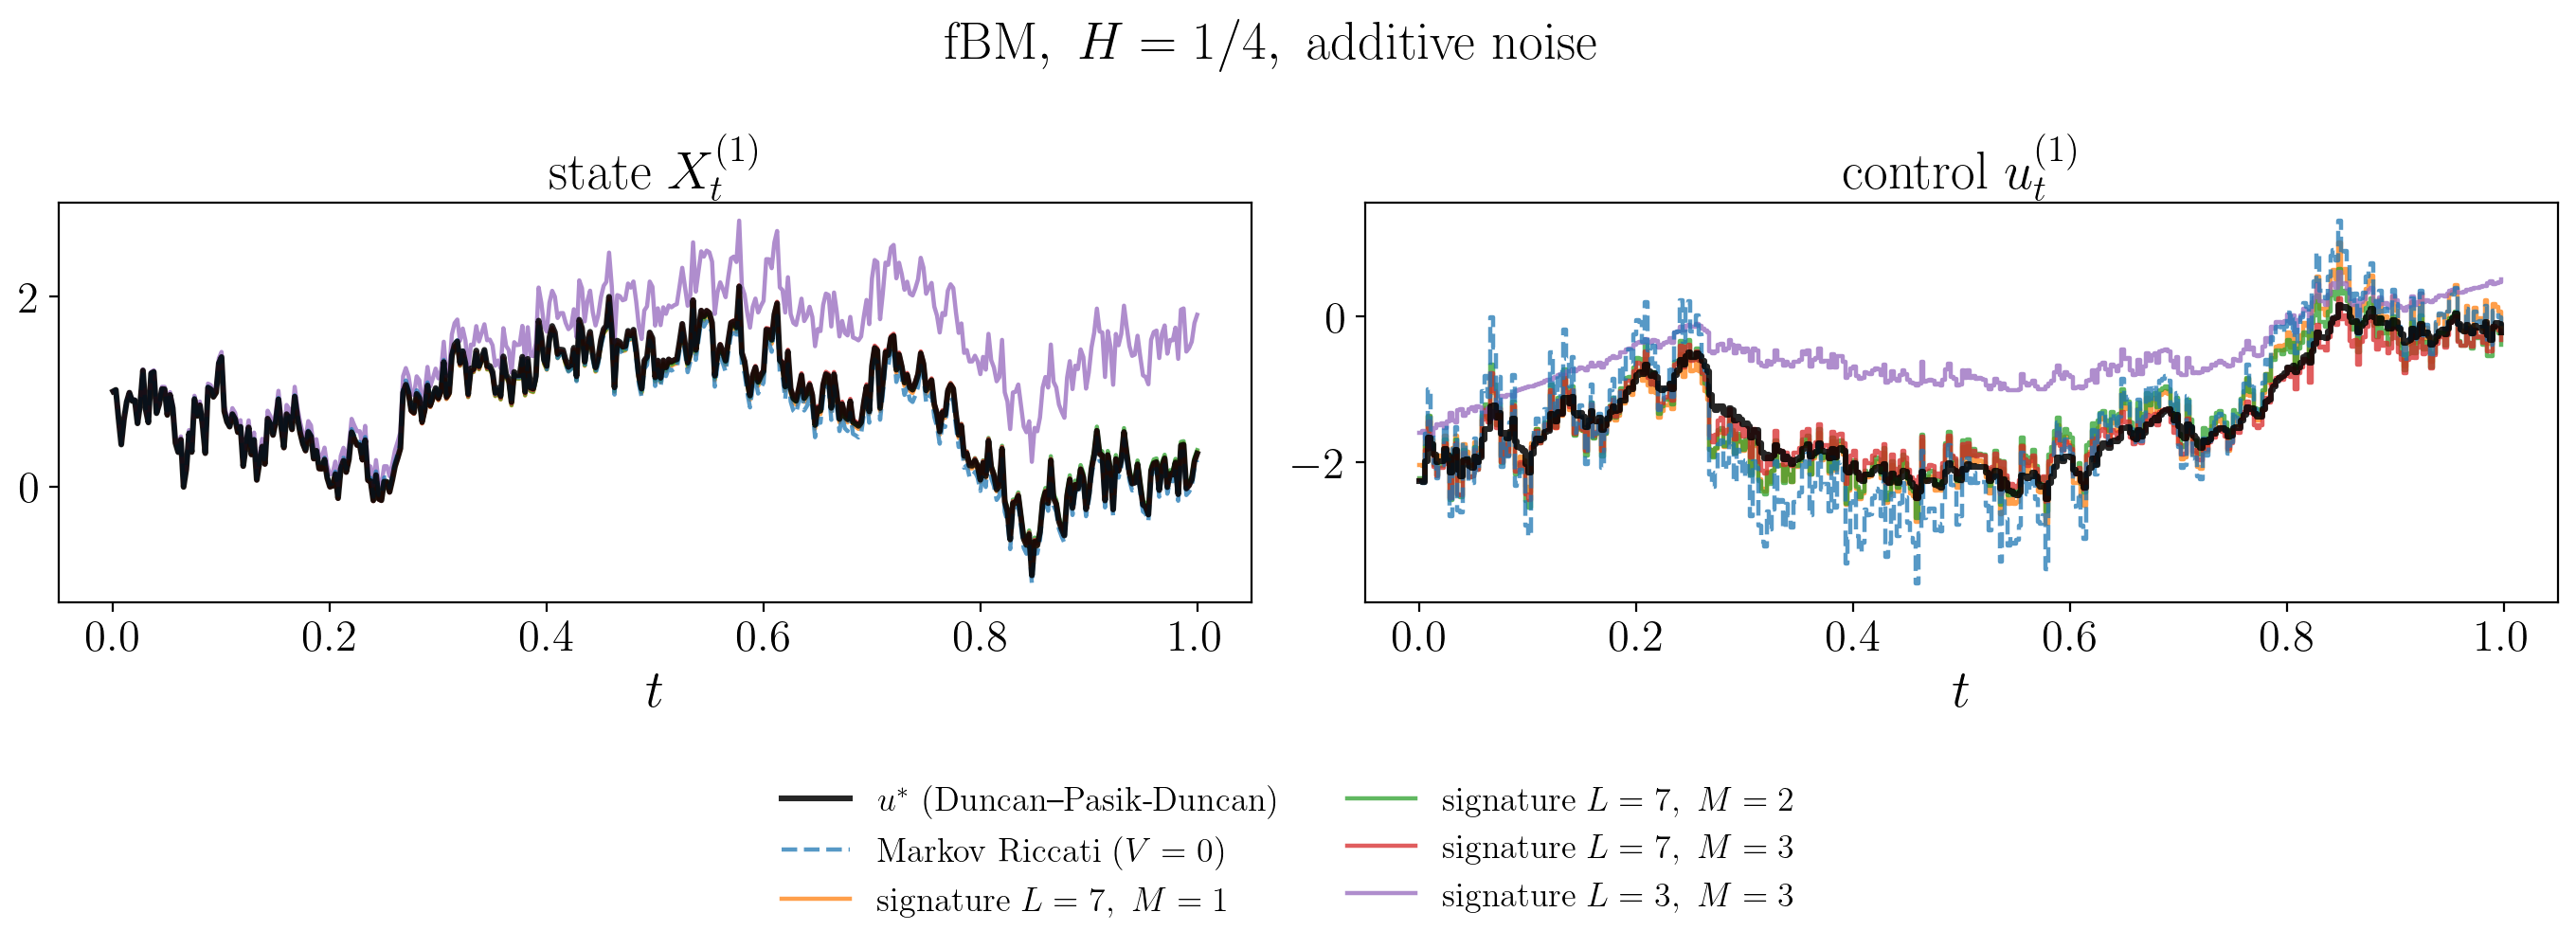

In [31]:
dBp, xip = dB_test[:3], xi_test[:3]                              # first test paths of 10.1
Vp = bench1['V_of'](xip)
ctrls = {r"$u^*\ \mathrm{(Duncan\text{--}Pasik\text{-}Duncan)}$": (bench1['control'](Vp), 0),
         r"$\mathrm{Markov\ Riccati}\ (V=0)$": (bench1['control'](Vp, 0.0), 0)}
for (L, M) in [(7, 1), (7, 2), (7, 3), (3, 3)]:
    ctrls[rf"$\mathrm{{signature}}\ L={L},\ M={M}$"] = (signature_control(thetas1[(L, M)][0], m1f, M), M)
_ = compare_paths(m1f, dBp, dt1, ctrls, simulate_driver, title=r"$\mathrm{fBM},\ H=1/4,\ \mathrm{additive\ noise}$",
                  fname="fbm_H025_sample_paths")

**SGD / Adam under fBM.** The same three gradient modes apply.
* `'exact'` minimises the empirical quadratic built from the training paths.
* `'mc_tensor'` and `'mc_sde'` draw a fresh fBM pool every `refresh_every` iterations, via `increments_fn`.

Resampling acts as a regulariser against the overfitting to a fixed training set that a sample-average closed form can suffer when $P$ is large (see §10.2).

In [32]:
Lo, Mo = 7, 3
chol_pool = fbm_cholesky(H, 200, m1f.T)
fbm_fn = lambda rng: fbm_increments(H, 2048, 200, 1, m1f.T, rng, chol=chol_pool)
F73 = F1_full.restrict(Lo, Mo)
runs_f1 = {
    "Adam, exact (empirical quadratic)": dict(method='adam', mode='exact', lr=0.05, n_iter=3000, average_tail=0),
    "Adam, mc_tensor (fBM pools)":       dict(method='adam', mode='mc_tensor', lr=0.05, n_iter=1500,
                                              increments_fn=fbm_fn, n_pool=2048, n_steps=200, record_every=2, refresh_every=500),
    "Adam, mc_sde (fBM pools)":          dict(method='adam', mode='mc_sde', lr=0.05, n_iter=1500,
                                              increments_fn=fbm_fn, n_pool=2048, n_steps=200, record_every=2, refresh_every=500),
}
res_f1 = {}
for name, kw in runs_f1.items():
    res_f1[name] = fit_signature_control(m1f, Lo, Mo, F=F73, batch_size=256, lr_decay=lambda k: 1 / (1 + k / 500),
                                         eval_every=0, seed=5, **kw)
ev1o = evaluate_thetas(m1f, {k: (o['theta'], Mo) for k, o in res_f1.items()} | {"closed form": thetas1[(Lo, Mo)]},
                       test_pool1, dt1, ref=ref1)
print(f"(L, M) = ({Lo}, {Mo});  out-of-sample excess cost over Duncan–Pasik-Duncan [paired MC: mean ± 95% CI]"
      " and L2 distance to u* [± 95% CI]:")
for k in ["closed form"] + list(res_f1):
    tt = f"{res_f1[k]['time']:.1f}s" if k in res_f1 else "—"
    print(f"{k:>34}: {fmt_mc(ev1o[k]['diff'], 4)}   L2 = {fmt_l2(ev1o[k]['d2'], 4)}   ({tt})")
del test_pool1; gc.collect()

(L, M) = (7, 3);  out-of-sample excess cost over Duncan–Pasik-Duncan [paired MC: mean ± 95% CI] and L2 distance to u* [± 95% CI]:
                       closed form: 0.0253 ± 0.0018   L2 = 0.1608 ± 0.0007   (—)
 Adam, exact (empirical quadratic): 0.0276 ± 0.0020   L2 = 0.1672 ± 0.0007   (0.1s)
       Adam, mc_tensor (fBM pools): 0.0408 ± 0.0029   L2 = 0.1984 ± 0.0009   (15.6s)
          Adam, mc_sde (fBM pools): 0.0391 ± 0.0028   L2 = 0.1941 ± 0.0008   (5.4s)


30197

### 10.2 Multi-dimensional example: $N=D=K=2$, $H=0.35$, $\sigma_2=0$ (with benchmark)
This is the model of §7 with the multiplicative noise removed and $W$ replaced by a 2-D fBM with $H=0.35$.
The pairing matrices use 10,000 training paths and $L\le5$ ($\dim T^5=364$ per component).

In [33]:
mm0 = LQModel(T=mm.T, X0=mm.X0, b0=mm.b0, b1=mm.b1, b2=mm.b2, sigma0=mm.sigma0, sigma2=np.zeros_like(mm.sigma2),
              A=mm.A, B=mm.B, C=mm.C, Dlin=mm.Dlin, E=mm.E, G=mm.G)
H2 = 0.35; chol2 = fbm_cholesky(H2, nF, mm0.T); dt2 = mm0.T / nF
bench2 = dpd_benchmark(mm0, H2, nF, chol=chol2)
t0 = time.perf_counter()
dB_train2 = fbm_increments(H2, 10000, nF, 2, mm0.T, np.random.default_rng(20), chol=chol2)
F2_full = EmpiricalCostFunctionals(mm0, 5, 3, dB_train2, dt2, record_every=4)
print(f"empirical functionals (L=5, M=3, 10000 paths): {time.perf_counter() - t0:.1f}s")
print(f"exact J(u*) = {bench2['exact_cost']():.5f};   Markov Riccati (V=0): {bench2['exact_cost'](0.0):.5f}")

dB_test2, xi_test2 = fbm_increments(H2, 4000, nF, 2, mm0.T, np.random.default_rng(21), chol=chol2, return_xi=True)
V2 = bench2['V_of'](xi_test2)
ctrls2 = {"u* (DPD)": (bench2['control'](V2), 0), "Markov Riccati (V=0)": (bench2['control'](V2, 0.0), 0)}
train_obj = {}
for (L, M) in [(2, 1), (3, 1), (3, 2), (4, 2), (5, 2), (5, 3)]:
    r = fit_signature_control(mm0, L, M, F=F2_full.restrict(L, M))
    ctrls2[f"closed form L={L}, M={M}"] = (signature_control(r['theta'], mm0, M), M); train_obj[f"closed form L={L}, M={M}"] = r['value']
fbm_fn2 = lambda rng: fbm_increments(H2, 2048, 200, 2, mm0.T, rng, chol=fbm_cholesky(H2, 200, mm0.T))
o = fit_signature_control(mm0, 5, 3, method='adam', mode='mc_sde', lr=0.05, n_iter=1500, batch_size=256,
                          increments_fn=fbm_fn2, n_pool=2048, n_steps=200, record_every=2, refresh_every=300,
                          lr_decay=lambda k: 1 / (1 + k / 500), eval_every=0, seed=7, F=F2_full.restrict(5, 3))
ctrls2["Adam mc_sde L=–, M=3"] = (signature_control(o['theta'], mm0, 3), 3)
o2 = fit_signature_control(mm0, 5, 2, method='adam', mode='mc_tensor', lr=0.05, n_iter=1500, batch_size=256,
                           increments_fn=fbm_fn2, n_pool=2048, n_steps=200, record_every=2, refresh_every=300,
                           lr_decay=lambda k: 1 / (1 + k / 500), eval_every=0, seed=8, F=F2_full.restrict(5, 2))
ctrls2["Adam mc_tensor L=5, M=2"] = (signature_control(o2['theta'], mm0, 2), 2)
ev2 = evaluate_controls(mm0, ctrls2, dB_test2, dt2, reference="u* (DPD)")
print(f"\nMC test cost of u* (DPD): {fmt_mc(ev2['u* (DPD)']['cost'], 5)}   [mean ± 95% CI]")
print(f"{'control':>26} | {'train J^L':>9} | {'excess over u* (paired): mean ± 95% CI':>45} | L2 to u* [± 95% CI]")
for k, v in ev2.items():
    if k == "u* (DPD)": continue
    tr = f"{train_obj[k]:9.5f}" if k in train_obj else " " * 9
    print(f"{k:>26} | {tr} | {fmt_mc(v['diff'], 5):>45} | {fmt_l2(v['d2'], 4)}")

empirical functionals (L=5, M=3, 10000 paths): 38.9s
exact J(u*) = 1.32236;   Markov Riccati (V=0): 1.32562



MC test cost of u* (DPD): 1.32101 ± 0.01059   [mean ± 95% CI]
                   control | train J^L |        excess over u* (paired): mean ± 95% CI | L2 to u* [± 95% CI]
      Markov Riccati (V=0) |           |                             0.00312 ± 0.00032 | 0.0623 ± 0.0003
      closed form L=2, M=1 |   1.40091 |                             0.03368 ± 0.00061 | 0.2175 ± 0.0005
      closed form L=3, M=1 |   1.31435 |                             0.00807 ± 0.00034 | 0.0995 ± 0.0006
      closed form L=3, M=2 |   1.20723 |                             0.07430 ± 0.00123 | 0.2997 ± 0.0006
      closed form L=4, M=2 |   1.32283 |                             0.00175 ± 0.00010 | 0.0499 ± 0.0001
      closed form L=5, M=2 |   1.31939 |                             0.00077 ± 0.00007 | 0.0313 ± 0.0001
      closed form L=5, M=3 |   1.31433 |                             0.00392 ± 0.00011 | 0.0721 ± 0.0003
      Adam mc_sde L=–, M=3 |           |                             0.00105 ± 0.00011 | 0.03

**Full $(L,M)$ grid.** Closed-form controls for every $L\le5$, $M\le3$ from the same empirical functionals, evaluated on the same 4,000 test paths as $u^*$. Since $\sigma_2=0$, the Itô Euler step of `simulate_many` coincides with the Euler step of `simulate_driver` on the fBM increments.

MC test cost of u* (DPD): 1.32101 ± 0.01059   [mean ± 95% CI]

excess cost J(u^{L,M}) − J(u*)  [paired MC: mean ± 95% CI]     rows: L, cols: M = [0, 1, 2, 3]
L=1:      0.14835 ± 0.00496       0.39277 ± 0.01061       0.58544 ± 0.01295       0.67109 ± 0.01367
L=2:      0.14200 ± 0.00439       0.03368 ± 0.00061       0.37672 ± 0.00982       0.46472 ± 0.01236
L=3:      0.14183 ± 0.00443       0.00807 ± 0.00034       0.07430 ± 0.00123       0.30406 ± 0.00838
L=4:      0.14183 ± 0.00442       0.00771 ± 0.00035       0.00175 ± 0.00010       0.21533 ± 0.00360
L=5:      0.14183 ± 0.00442       0.00771 ± 0.00035       0.00077 ± 0.00007       0.00392 ± 0.00011

L2(dP⊗dt) distance to u*  [± 95% CI]     rows: L, cols: M = [0, 1, 2, 3]
L=1:      0.37521 ± 0.00203       0.49003 ± 0.00294       0.62566 ± 0.00292       0.69164 ± 0.00283
L=2:      0.37177 ± 0.00218       0.21747 ± 0.00046       0.57633 ± 0.00359       0.58416 ± 0.00493
L=3:      0.37145 ± 0.00214       0.09954 ± 0.00057       0.29974 ± 

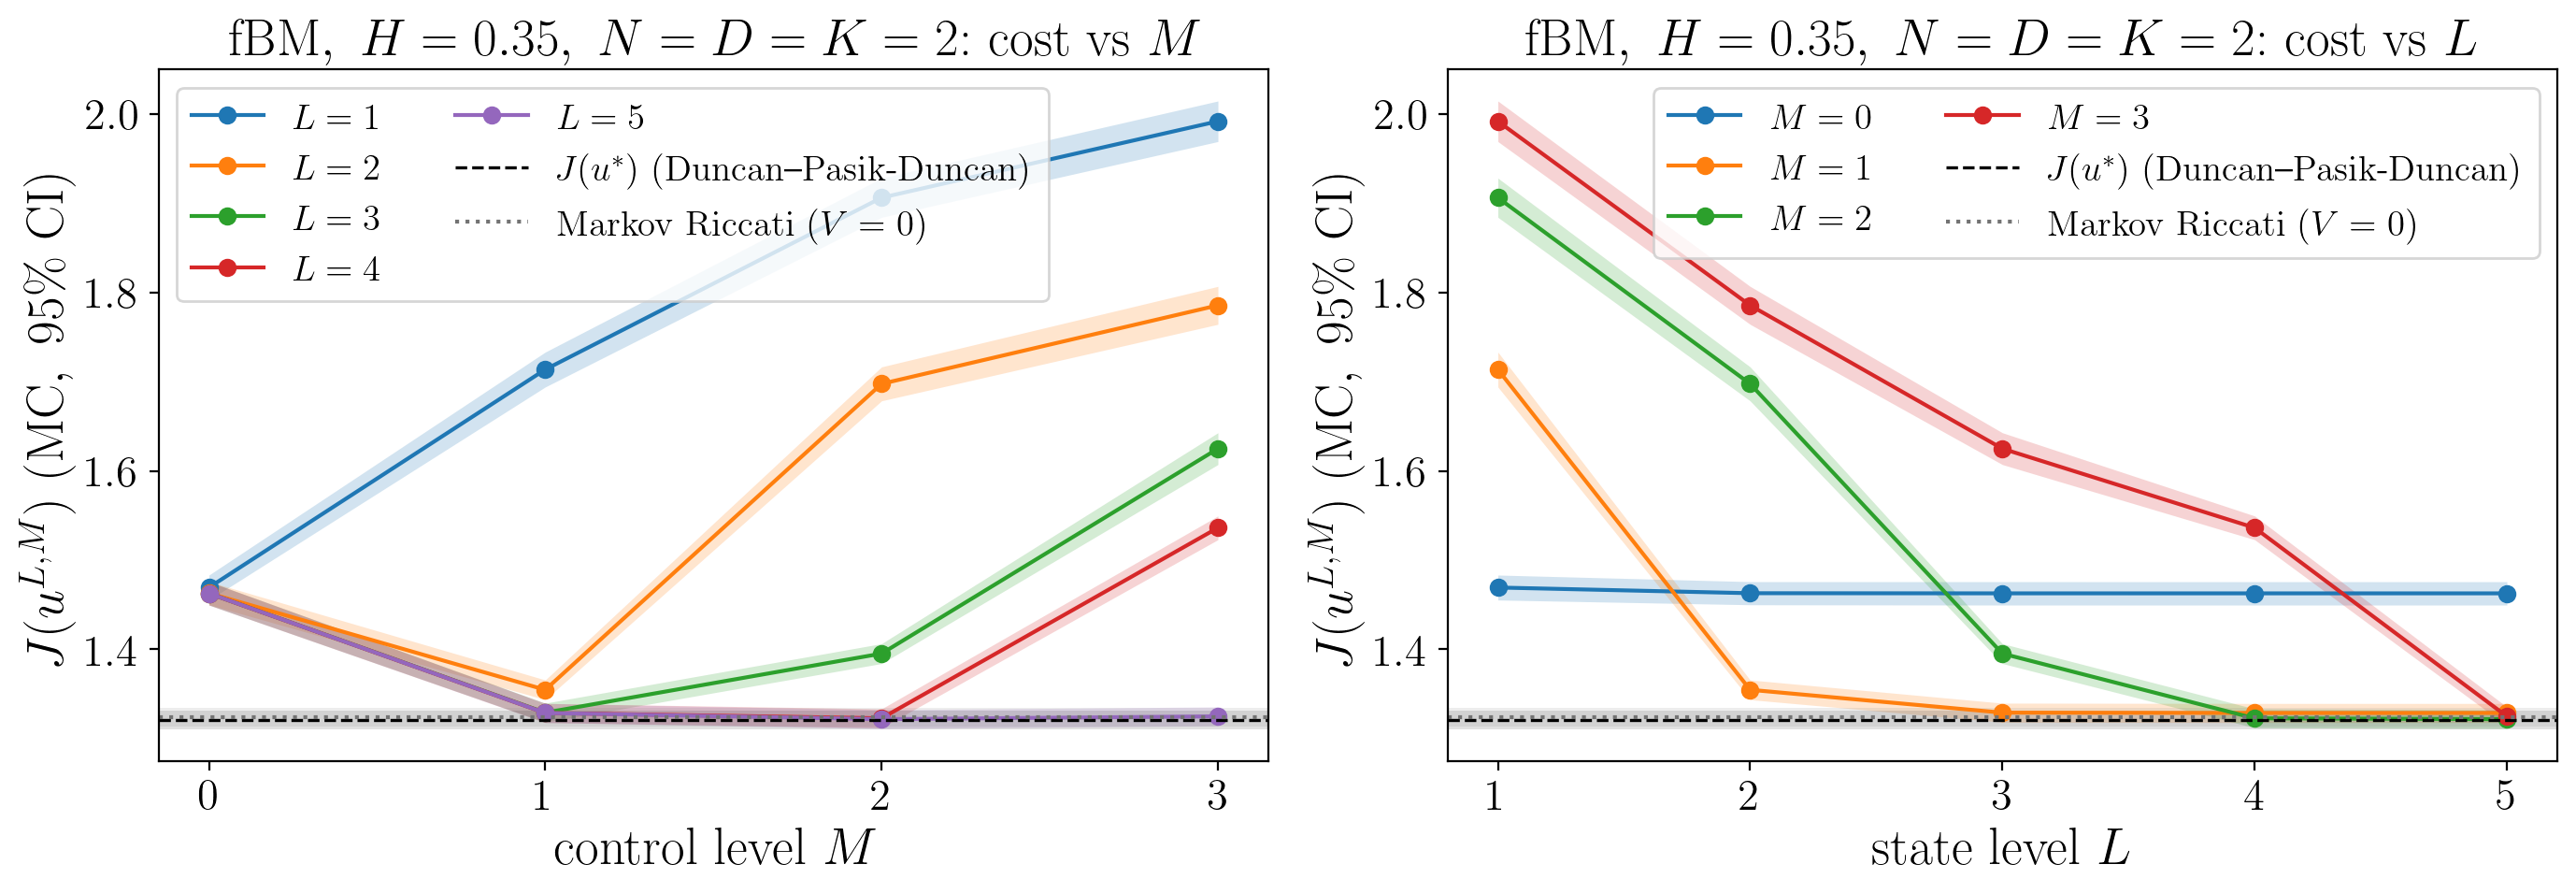

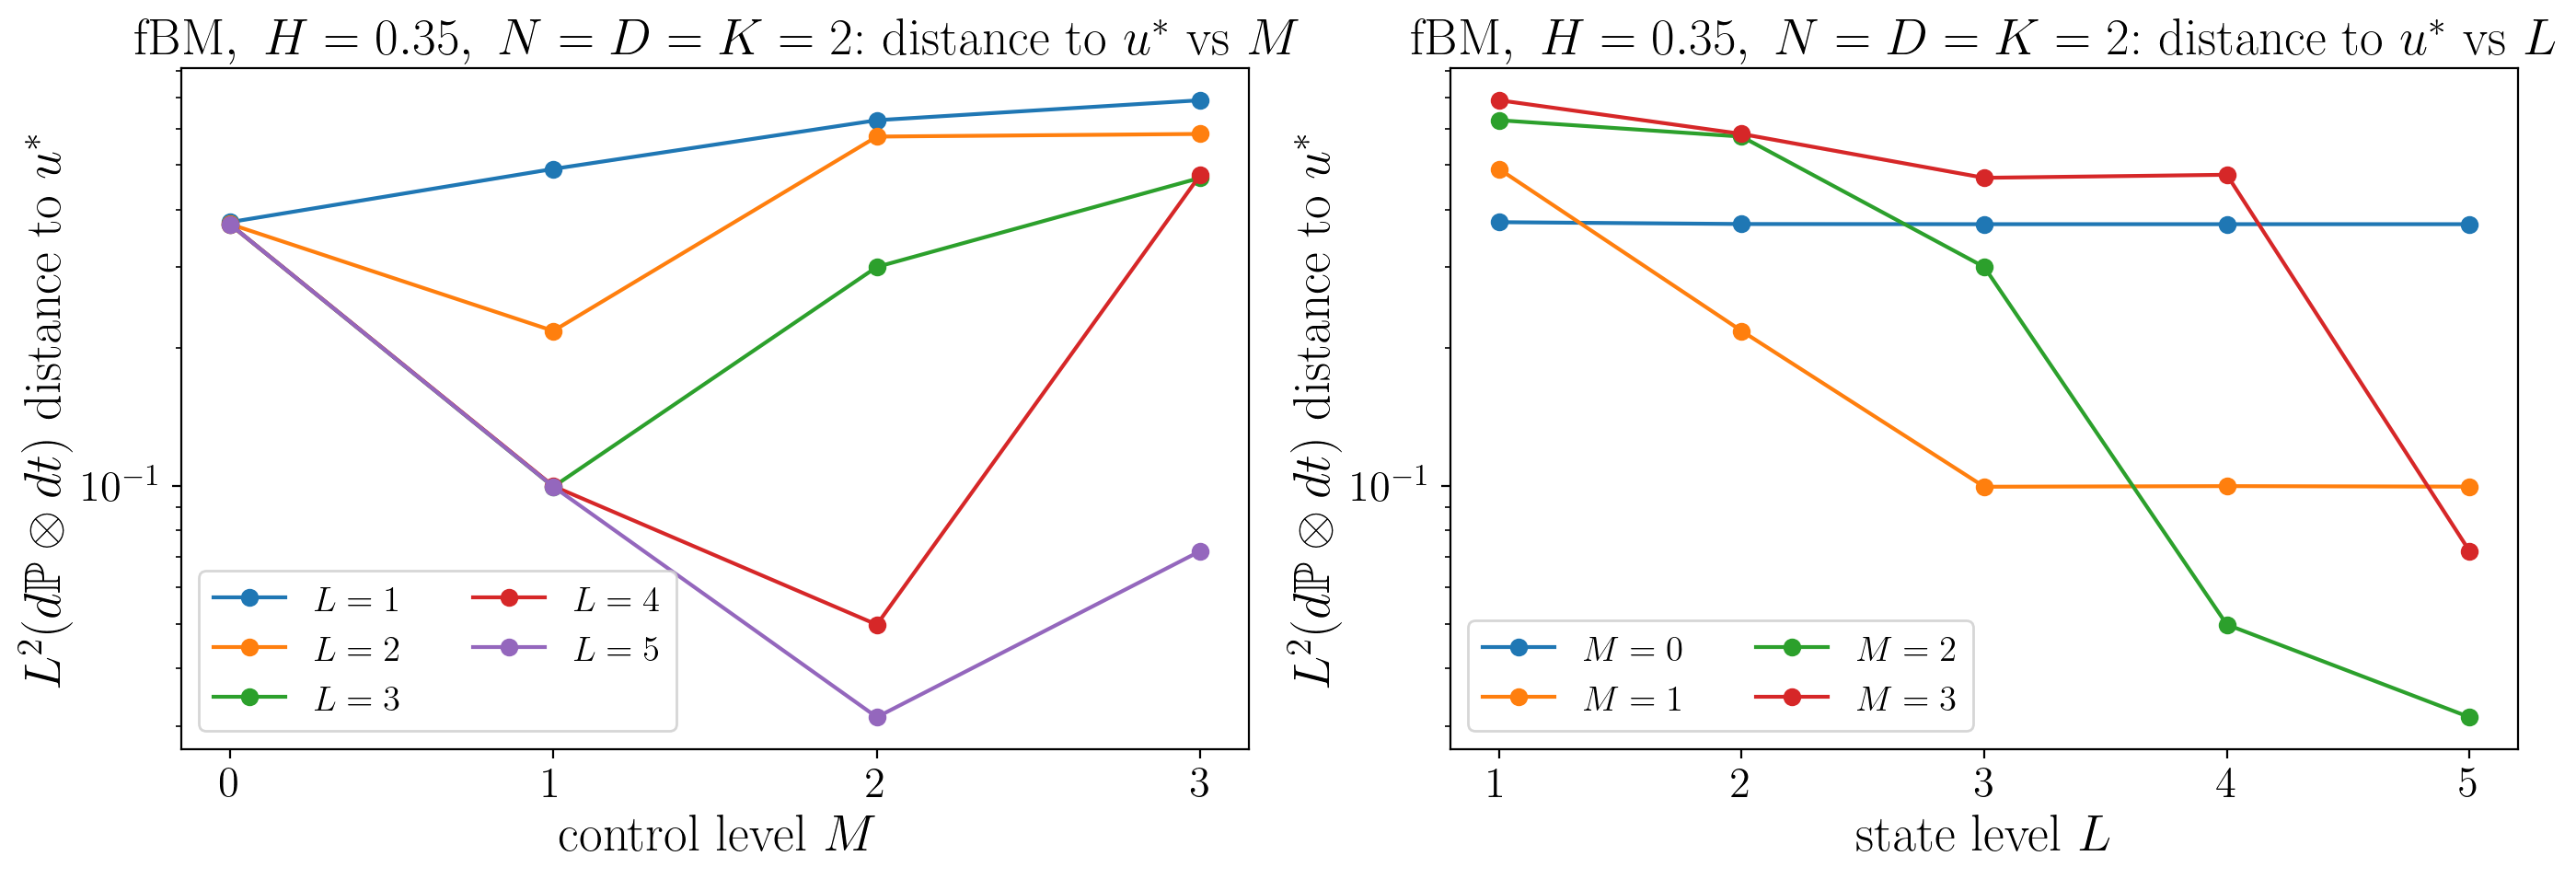

In [34]:
Ls_g2, Ms_g2 = [1, 2, 3, 4, 5], [0, 1, 2, 3]
th_g2 = {(L, M): fit_signature_control(mm0, L, M, F=F2_full.restrict(L, M))['theta'] for L in Ls_g2 for M in Ms_g2}
cost_g2, c_ref_g2, d2_g2 = simulate_many(mm0, dB_test2, dt2, [(th_g2[k], k[1]) for k in th_g2], bench2['control'](V2))
mc_g2 = {k: dict(cost=cost_g2[c], diff=cost_g2[c] - c_ref_g2, d2=d2_g2[c]) for c, k in enumerate(th_g2)}
print(f"MC test cost of u* (DPD): {fmt_mc(c_ref_g2, 5)}   [mean ± 95% CI]\n")
print_grid(mc_g2, Ls_g2, Ms_g2, 5)
plot_grid(mc_g2, Ls_g2, Ms_g2, c_ref_g2, r"$J(u^*)\ \mathrm{(Duncan\text{--}Pasik\text{-}Duncan)}$", "fbm_H035_2d",
          r"\mathrm{fBM},\ H=0.35,\ N=D=K=2", refs=[(ev2["Markov Riccati (V=0)"]['cost'], r"$\mathrm{Markov\ Riccati}\ (V=0)$")])

The prediction term matters less here than in 10.1, because the noise is smaller and $H$ is closer to $\tfrac12$. Even so, signature controls with $M=2$ come close to $u^*$ and clearly improve on the Markovian feedback. They do this without being told about $V$: the signature of the past noise learns the prediction $\mathbb E[\,\cdot\,|\mathcal F_t]$ implicitly.

The closed-form $(L,M)=(5,3)$ control is a cautionary example. Its in-sample objective is the lowest, but out of sample it is *worse* than $M=2$. With $P=80$ coefficients and pairing matrices estimated from 10,000 paths, the sample-average problem overfits, and a smaller $L$ relative to $M$ adds truncation error on top.
Adam with fresh fBM pools at the same $M=3$ avoids the fixed-sample overfit, which is a practical argument for the stochastic modes. More training paths, or a larger $L$, fix the closed form as well.

### Sample paths: fBM, $H=0.35$, $N=D=K=2$
All controls below are driven by **the same noise path**. The top row shows the state components and the bottom row the control components.
The benchmark is drawn in black (and, under fBM, the Markovian Riccati feedback in dashed grey); the signature controls $u^{L,M}$ are in colour.

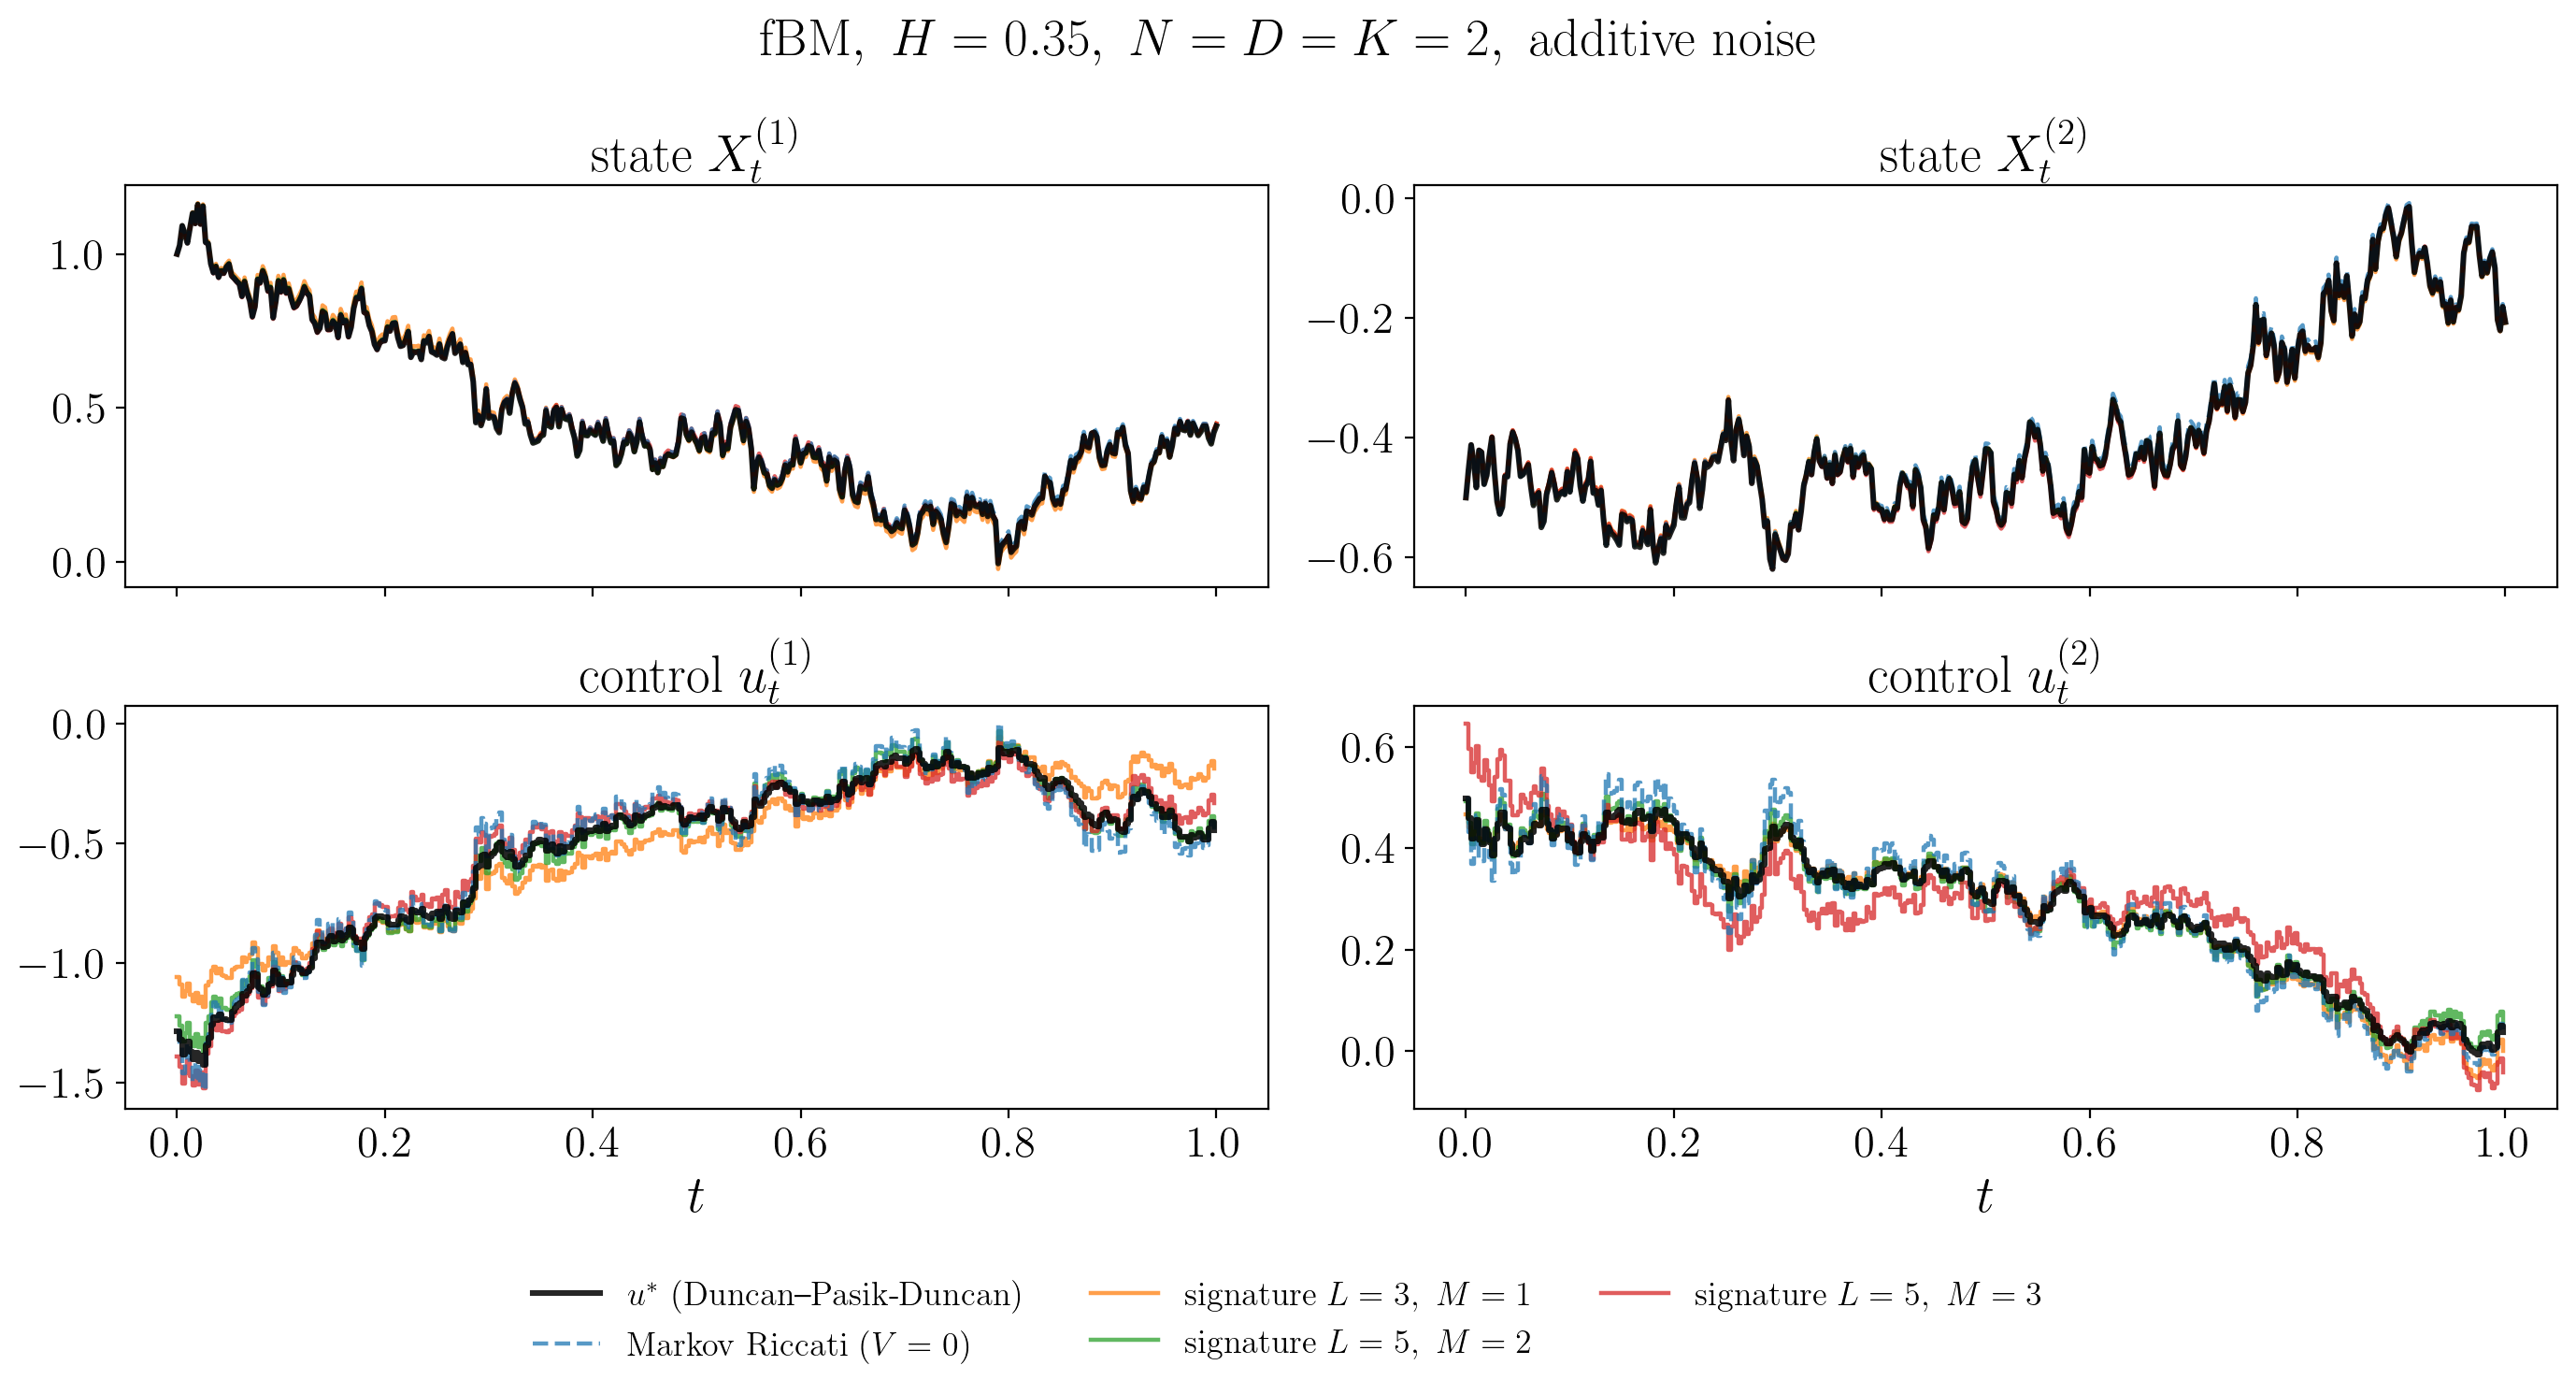

In [35]:
dBp, xip = dB_test2[:3], xi_test2[:3]                            # first test paths of 10.2
Vp = bench2['V_of'](xip)
ctrls = {r"$u^*\ \mathrm{(Duncan\text{--}Pasik\text{-}Duncan)}$": (bench2['control'](Vp), 0),
         r"$\mathrm{Markov\ Riccati}\ (V=0)$": (bench2['control'](Vp, 0.0), 0)}
for k, lab in {"closed form L=3, M=1": r"$\mathrm{signature}\ L=3,\ M=1$",
               "closed form L=5, M=2": r"$\mathrm{signature}\ L=5,\ M=2$",
               "closed form L=5, M=3": r"$\mathrm{signature}\ L=5,\ M=3$"}.items():
    ctrls[lab] = ctrls2[k]
_ = compare_paths(mm0, dBp, dt2, ctrls, simulate_driver, title=r"$\mathrm{fBM},\ H=0.35,\ N=D=K=2,\ \mathrm{additive\ noise}$",
                  fname="fbm_H035_2d_sample_paths")

### 10.3 Multiplicative fBM noise, $\sigma_2\neq0$, $H=\tfrac14$ (no closed-form benchmark)
The model is $dX=(\tfrac12X+u)\,dt+(\tfrac12+\tfrac12X)\circ dB^{1/4}$ with the same cost as 10.1. The Duncan–Pasik-Duncan result does not cover state-dependent noise, so there is no closed-form optimum.
We compare the signature methods with each other and against two heuristics:
* the Duncan–Pasik-Duncan control of the additive surrogate ($\sigma_2$ set to 0);
* the Markovian Riccati feedback of the same surrogate.

All simulations use the exact piecewise-linear (Wong–Zakai) step.

In [36]:
m3f = LQModel(T=1.0, X0=[1.], b0=[0.], b1=[[1.]], b2=[[0.5]], sigma0=[[0.5]], sigma2=[[[0.5]]],
              A=[[[1.]]], B=[[[1.]]], C=[[0.]], Dlin=[[0.]], E=[[1.]], G=[0.])
m3s = LQModel(T=1.0, X0=[1.], b0=[0.], b1=[[1.]], b2=[[0.5]], sigma0=[[0.5]], sigma2=[[[0.]]],
              A=[[[1.]]], B=[[[1.]]], C=[[0.]], Dlin=[[0.]], E=[[1.]], G=[0.])
bench3s = dpd_benchmark(m3s, H, nF, chol=chol1)
F3_full = EmpiricalCostFunctionals(m3f, 7, 3, dB_train, dt1, record_every=4)       # same training fBM paths as 10.1
thetas3 = {f"closed form L={L}, M={M}": (fit_signature_control(m3f, L, M, F=F3_full.restrict(L, M))['theta'], M)
           for (L, M) in [(3, 1), (5, 2), (7, 2), (7, 3)]}
for name, kw in {"Adam mc_sde M=3":    dict(mode='mc_sde'),
                 "Adam mc_tensor L=7, M=3": dict(mode='mc_tensor')}.items():
    o = fit_signature_control(m3f, 7, 3, method='adam', lr=0.05, n_iter=1500, batch_size=256, increments_fn=fbm_fn,
                              n_pool=2048, n_steps=200, record_every=2, refresh_every=500,
                              lr_decay=lambda k: 1 / (1 + k / 500), eval_every=0, seed=11, F=F3_full.restrict(7, 3), **kw)
    thetas3[name] = (o['theta'], 3)
test_pool3 = mc_feature_pool(m3f, 0, 3, 5000, nF, 1, mode='sde', increments=dB_test, driver='general')
V3 = bench3s['V_of'](xi_test)
c_h1, _, U_h1 = simulate_driver(m3f, dB_test, dt1, bench3s['control'](V3))           # wz scheme (sigma2 != 0)
c_h2, _, _ = simulate_driver(m3f, dB_test, dt1, bench3s['control'](V3, 0.0))
ev3 = evaluate_thetas(m3f, thetas3, test_pool3, dt1, ref=dict(cost=c_h1, U=U_h1))
print(f"MC test cost of the DPD control of the additive surrogate (reference): {fmt_mc(c_h1, 4)}   [mean ± 95% CI]")
print(f"{'control':>30} | excess over DPD-of-surrogate (paired): mean ± 95% CI")
print(f"{'Markov Riccati of surrogate':>30} | {fmt_mc(c_h2 - c_h1, 4)}")
for k, v in ev3.items():
    print(f"{k:>30} | {fmt_mc(v['diff'], 4)}")

MC test cost of the DPD control of the additive surrogate (reference): 3.6294 ± 0.1201   [mean ± 95% CI]
                       control | excess over DPD-of-surrogate (paired): mean ± 95% CI
   Markov Riccati of surrogate | 0.1071 ± 0.0046
          closed form L=3, M=1 | -0.0747 ± 0.0301
          closed form L=5, M=2 | -0.1846 ± 0.0247
          closed form L=7, M=2 | -0.1886 ± 0.0247
          closed form L=7, M=3 | -0.2331 ± 0.0249
               Adam mc_sde M=3 | -0.2114 ± 0.0247
       Adam mc_tensor L=7, M=3 | -0.2103 ± 0.0249


**Full $(L,M)$ grid.** There is no closed-form optimum here, so excess costs and distances are measured against the Duncan–Pasik-Duncan control of the additive surrogate (a heuristic benchmark), on the same 5,000 test paths.

excess cost J(u^{L,M}) − J(DPD-of-surrogate)  [paired MC: mean ± 95% CI]     rows: L, cols: M = [0, 1, 2, 3]
L=2:      1.5270 ± 0.1412       0.0492 ± 0.0383       1.9223 ± 0.1754       3.6126 ± 0.2651
L=3:      1.5157 ± 0.1356      -0.0747 ± 0.0301      -0.0194 ± 0.0231       1.9589 ± 0.1920
L=4:      1.5145 ± 0.1332      -0.0922 ± 0.0298      -0.1549 ± 0.0239      -0.1552 ± 0.0199
L=5:      1.5146 ± 0.1326      -0.0925 ± 0.0298      -0.1846 ± 0.0247      -0.1535 ± 0.0191
L=6:      1.5147 ± 0.1325      -0.0922 ± 0.0298      -0.1882 ± 0.0247      -0.2242 ± 0.0245
L=7:      1.5147 ± 0.1324      -0.0921 ± 0.0298      -0.1886 ± 0.0247      -0.2331 ± 0.0249

L2(dP⊗dt) distance to DPD-of-surrogate  [± 95% CI]     rows: L, cols: M = [0, 1, 2, 3]
L=2:      0.8303 ± 0.0123       0.4811 ± 0.0072       0.9625 ± 0.0267       1.1450 ± 0.0259
L=3:      0.8379 ± 0.0118       0.4251 ± 0.0058       0.4815 ± 0.0071       0.8981 ± 0.0307
L=4:      0.8418 ± 0.0116       0.4041 ± 0.0055       0.3849 ± 0.00

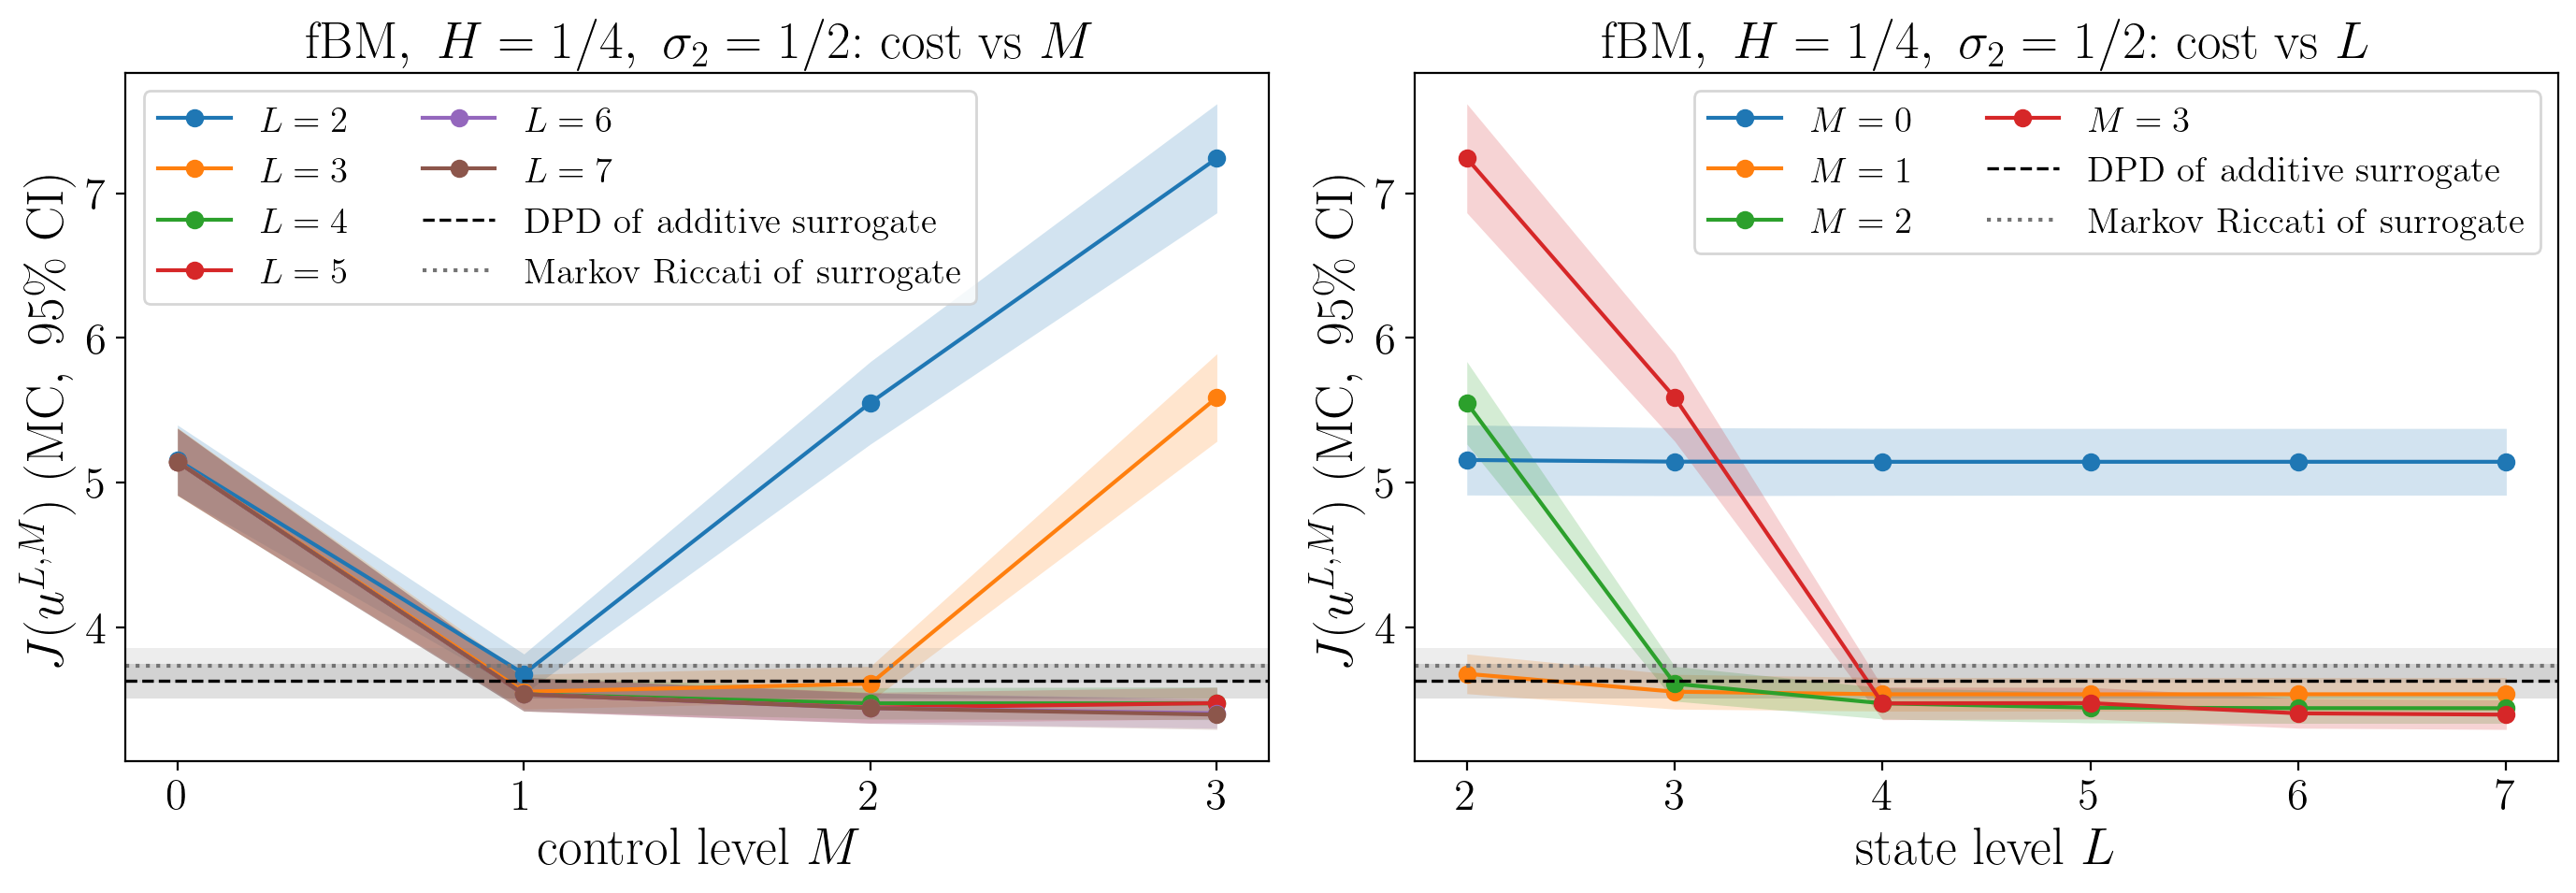

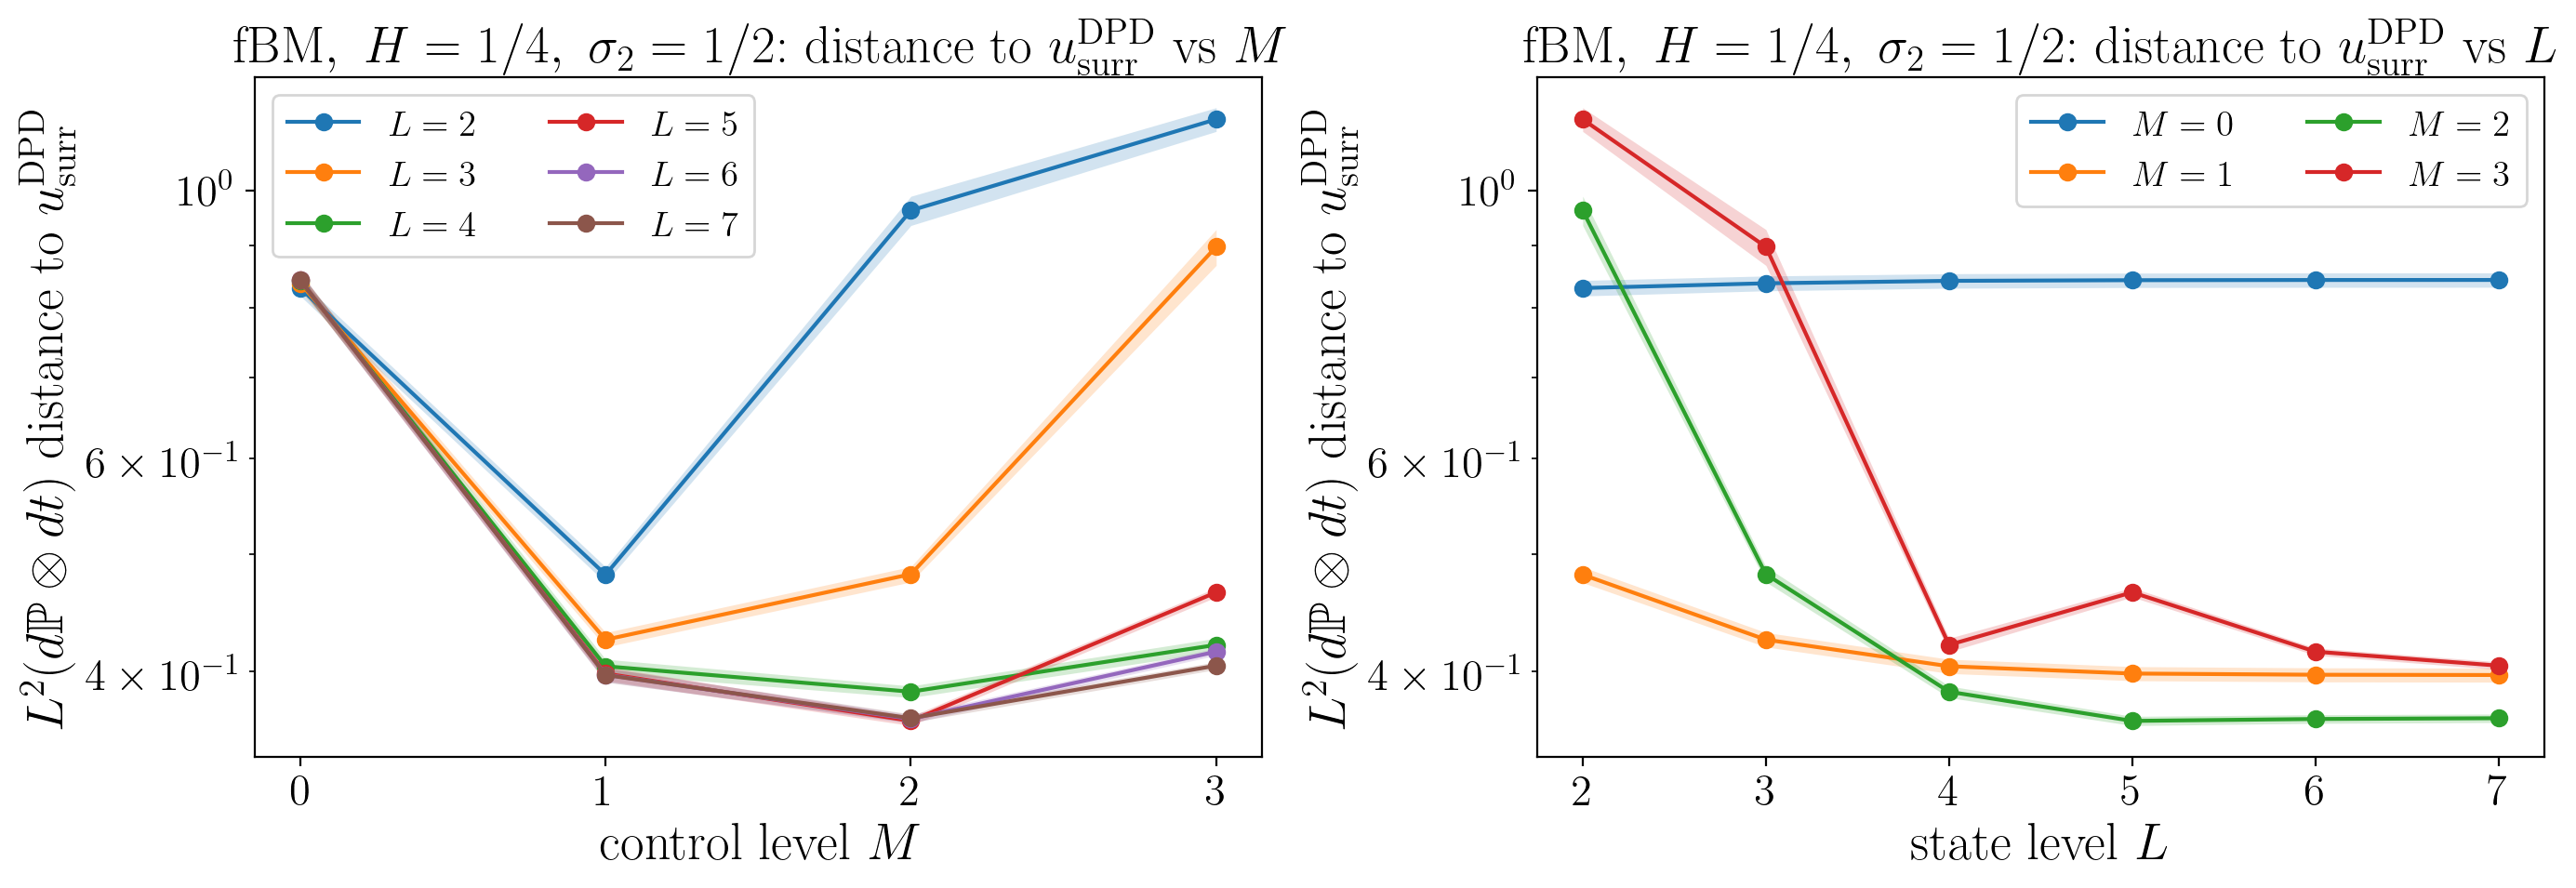

41456

In [37]:
Ls_g3, Ms_g3 = [2, 3, 4, 5, 6, 7], [0, 1, 2, 3]
th_g3 = {(L, M): (fit_signature_control(m3f, L, M, F=F3_full.restrict(L, M))['theta'], M) for L in Ls_g3 for M in Ms_g3}
ev_g3 = evaluate_thetas(m3f, th_g3, test_pool3, dt1, ref=dict(cost=c_h1, U=U_h1))
print_grid(ev_g3, Ls_g3, Ms_g3, 4, ref="DPD-of-surrogate")
plot_grid(ev_g3, Ls_g3, Ms_g3, c_h1, r"$\mathrm{DPD\ of\ additive\ surrogate}$", "fbm_H025_multiplicative",
          r"\mathrm{fBM},\ H=1/4,\ \sigma_2=1/2", refs=[(c_h2, r"$\mathrm{Markov\ Riccati\ of\ surrogate}$")],
          ref_sym=r"u^{\mathrm{DPD}}_{\mathrm{surr}}")
del test_pool3; gc.collect()

With multiplicative fBM noise, the signature controls beat both heuristics, and the paired differences are negative and significant. This is the regime the method is built for: no Riccati or Duncan–Pasik-Duncan formula is available, yet the same machinery yields a near-optimal non-anticipative control.

### Sample paths: fBM, $H=\tfrac14$, $\sigma_2=\tfrac12$
All controls below are driven by **the same noise path**. The left panel shows the state and the right panel the control.
The benchmark is drawn in black (and, under fBM, the Markovian Riccati feedback in dashed grey); the signature controls $u^{L,M}$ are in colour.

There is no closed-form optimum here, so the black curve is the Duncan–Pasik-Duncan control of the additive surrogate ($\sigma_2$ set to 0): a heuristic, not a benchmark. The noise path is the same as in the 10.1 plot.

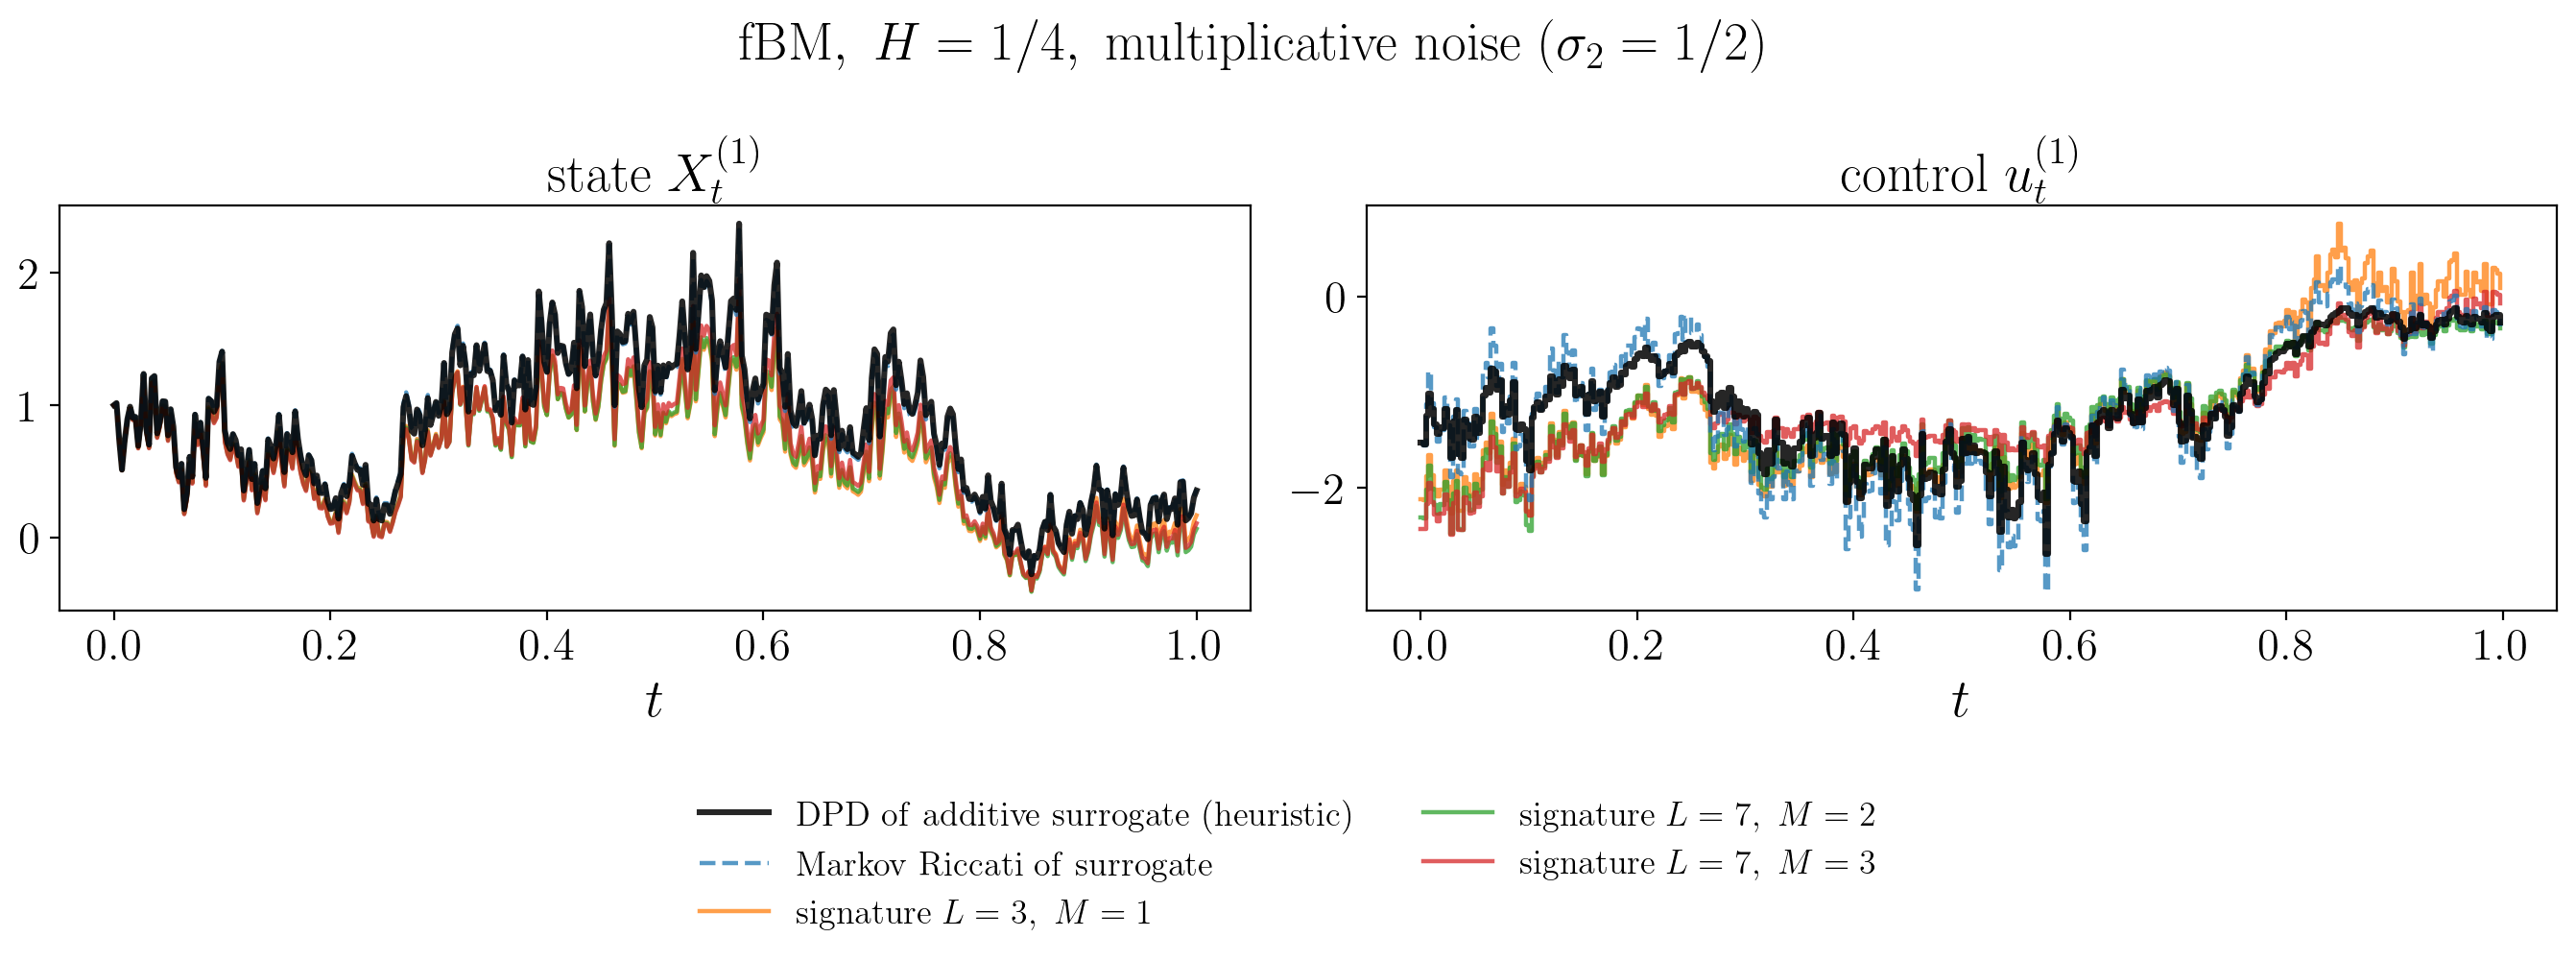

In [38]:
dBp, xip = dB_test[:3], xi_test[:3]                              # same noise path as in 10.1
Vp = bench3s['V_of'](xip)
ctrls = {r"$\mathrm{DPD\ of\ additive\ surrogate\ (heuristic)}$": (bench3s['control'](Vp), 0),
         r"$\mathrm{Markov\ Riccati\ of\ surrogate}$": (bench3s['control'](Vp, 0.0), 0)}
for k, lab in {"closed form L=3, M=1": r"$\mathrm{signature}\ L=3,\ M=1$",
               "closed form L=7, M=2": r"$\mathrm{signature}\ L=7,\ M=2$",
               "closed form L=7, M=3": r"$\mathrm{signature}\ L=7,\ M=3$"}.items():
    th, M = thetas3[k]
    ctrls[lab] = (signature_control(th, m3f, M), M)
_ = compare_paths(m3f, dBp, dt1, ctrls, simulate_driver,
                  title=r"$\mathrm{fBM},\ H=1/4,\ \mathrm{multiplicative\ noise}\ (\sigma_2=1/2)$",
                  fname="fbm_H025_multiplicative_sample_paths")

## 11. Remarks

* **Proposed recursion vs alternatives.** Option (A) is correct and terminates after exactly $L$ sweeps, by nilpotency. Option (B) does the same work without recomputing lower levels. Option (C) separates the dynamics ($R$, independent of the control) from the control ($\mathtt p$). All three are interchangeable through `solver=`.
  In practice the bottleneck is building the cost functionals, i.e. the $\bar D^{2L}$-sized shuffle pairings, not solving for $\mathtt X$.
* **Exact quadratic vs polarisation.** Because $\mathtt X^{\mathtt u}$ is affine in $\theta$, the quadratic can be assembled directly. This avoids $O(P^2)$ black-box evaluations, which matters when $P=K\dim T^M$ is large (here $P=80$ needs 3,321 evaluations).
* **Closed form vs SGD/Adam.** The objective is an exactly known, strictly convex quadratic, so the closed form is exact and fastest for moderate $P$. The first-order methods of §9 are there for large $P$, unknown expected signatures (`mc_*` modes) and non-quadratic extensions.
* **Cost and scaling.** $\dim T^L=(\bar D^{L+1}-1)/(\bar D-1)$, and the pairing matrices involve tensors of level $2L+m_{\max}+1$. For $\bar D=3$, $L=6$ takes a few seconds; $\bar D\ge4$ needs smaller $L$.
  The problem's ordered limit ($L\gg M$) suggests spending the budget on $L$.
* **Other drivers (Section 3.5).** §10 shows the full pipeline for fBM. Any driver that can be simulated works the same way: `EmpiricalCostFunctionals` for the closed form and `increments_fn` for SGD/Adam.
